# Sustainable Portfolio Allocation: From Mean-Variance to Net-Zero

End-to-end pipeline for a universe of **European listed firms with Scope 1 & 2 CO₂ data** (Refinitiv Datastream, 2004–2025):

**Part I: Portfolio allocation on financial objectives**
- §1 Data cleaning and universe construction (point-in-time, stale-price and data-sufficiency filters)
- §2 Investment sets (10-year rolling windows), EW/VW benchmarks, in-sample efficient frontier, **out-of-sample minimum-variance** portfolio 2014–2024

**Part II: Carbon-aware allocation**
- §3 Revenue data and carbon intensity
- §4 Carbon metrics (WACI, carbon footprint) of the baseline portfolios, top contributors, **minimum variance with a 50 % carbon-footprint cap**, and **tracking-error minimisation vs. the VW benchmark under the same cap**
- §5 Extended performance analysis: tracking error, information ratio, CAPM attribution, rolling Sharpe/beta, drawdowns, carbon-financial efficiency, turnover and costs

Run from the repository root; all inputs are read from `data/raw/` and intermediate files are written to `output/`.


# Part I — Portfolio Allocation on Financial Objectives

# 1 — Data Cleaning



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from scipy.optimize import minimize
from scipy.stats import pearsonr
from pathlib import Path
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

#  Raw Datastream files (provided by the course), stored in data/raw/
DATA_DIR = Path("data/raw")
DATA_URLS = {
    'static':     DATA_DIR / "Static_2025.xlsx",
    'scope1':     DATA_DIR / "DS_CO2_SCOPE_1_Y_2025.xlsx",
    'scope2':     DATA_DIR / "DS_CO2_SCOPE_2_Y_2025.xlsx",
    'ri_monthly': DATA_DIR / "DS_RI_T_USD_M_2025.xlsx",
    'mv_monthly': DATA_DIR / "DS_MV_T_USD_M_2025.xlsx",
    'mv_annual':  DATA_DIR / "DS_MV_T_USD_Y_2025.xlsx",
    'rf_data':    DATA_DIR / "Risk_Free_Rate_2025.xlsx",
    'revenue':    DATA_DIR / "DS_REV_Y_2025.xlsx",
}

# Generated files (investment sets, merged prices) -- not tracked in git
OUTPUT_DIR = Path("output")
INVESTMENT_SETS_DIR = OUTPUT_DIR / "investment_sets"
INVESTMENT_SETS_DIR.mkdir(parents=True, exist_ok=True)

# Parameters
LOW_PRICE_THRESHOLD = 0.5       # Prices below this are set to NaN
STALE_THRESHOLD = 0.30          # Max fraction of zero returns in 10y window
MIN_YEARS_DATA = 3              # Minimum years of price data in 10y window
WINDOW_YEARS = 10               # Rolling window size (years)
INVESTMENT_YEARS = range(2014, 2026)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

## 1.1 Load Raw Data

We load the key raw Excel files from Datastream:
- **Static_2025.xlsx** — Firm identifiers, country, region
- **DS_CO2_SCOPE_1/2_Y_2025.xlsx** — Yearly CO₂ emissions (Scope 1 & 2)
- **DS_RI_T_USD_M_2025.xlsx** — Monthly Return Index in USD

In [2]:
#  Load all raw data from data/raw/ 
static     = pd.read_excel(DATA_URLS['static'])
scope1     = pd.read_excel(DATA_URLS['scope1'])
scope2     = pd.read_excel(DATA_URLS['scope2'])
ri_monthly = pd.read_excel(DATA_URLS['ri_monthly'])
mv_monthly = pd.read_excel(DATA_URLS['mv_monthly'])
rf_data    = pd.read_excel(DATA_URLS['rf_data'])

# Annual market caps (used in section 2.5)
mv_annual  = pd.read_excel(DATA_URLS['mv_annual'], index_col=0)
mv_annual  = mv_annual.reset_index(drop=True).set_index('ISIN')
mv_annual  = mv_annual[[c for c in mv_annual.columns if isinstance(c, int)]]
mv_annual  = mv_annual.apply(pd.to_numeric, errors='coerce')

print(f"Static:            {static.shape[0]:>5} firms")
print(f"Scope 1:           {scope1.shape[0]:>5} firms x {len([c for c in scope1.columns if isinstance(c, (int, np.integer))])} years")
print(f"Scope 2:           {scope2.shape[0]:>5} firms x {len([c for c in scope2.columns if isinstance(c, (int, np.integer))])} years")
print(f"RI (monthly):      {ri_monthly.shape[0]:>5} firms x {len([c for c in ri_monthly.columns if isinstance(c, datetime)])} months")
print(f"MV (monthly):      {mv_monthly.shape[0]:>5} firms")
print(f"MV (annual):       {mv_annual.shape[0]:>5} firms")
print(f"Risk-free rate:    {len(rf_data):>5} months")

Static:             2545 firms
Scope 1:            2609 firms x 27 years
Scope 2:            2609 firms x 27 years
RI (monthly):       2609 firms x 314 months
MV (monthly):       2609 firms
MV (annual):        2609 firms
Risk-free rate:      312 months


## 1.2 Universe Selection — European Firms with CO₂ Data

We apply two filters:
1. **Region filter**: keep only European firms (`Region == "EUR"`)
2. **CO₂ data filter**: require both Scope 1 and Scope 2 emissions for at least one year

**Point-in-time logic**: A firm is eligible to enter the investment set for year *Y* if it has both Scope 1 and Scope 2 data available for year *Y−1*. This ensures we only use information that would have been publicly available at the time of portfolio construction (beginning of year *Y*).

In [3]:
# Filter European firms
static_eur = static[static['Region'] == 'EUR'].copy()
eur_isins = set(static_eur['ISIN'].dropna())

# Check Scope 1+2 availability per firm
scope1_eur = scope1[scope1['ISIN'].isin(eur_isins)].copy()
scope2_eur = scope2[scope2['ISIN'].isin(eur_isins)].copy()

# Remove duplicate ISINs (keep first)
scope1_eur = scope1_eur.drop_duplicates(subset='ISIN').set_index('ISIN')
scope2_eur = scope2_eur.drop_duplicates(subset='ISIN').set_index('ISIN')

year_cols = sorted([c for c in scope1_eur.columns if isinstance(c, (int, np.integer))])
common_isins = set(scope1_eur.index) & set(scope2_eur.index)

# For each firm: find years with both scopes, then apply Y-1 lag
eligible_years = {}  # ISIN -> set of investment years

for isin in common_isins:
    s1 = scope1_eur.loc[isin, year_cols]
    s2 = scope2_eur.loc[isin, year_cols]

    # Years where BOTH scopes are non-null
    years_both = [y for y in year_cols if pd.notna(s1[y]) and pd.notna(s2[y])]

    # Point-in-time: eligible to invest in Y if scope data available in Y-1
    inv_years = set(y + 1 for y in years_both) & set(INVESTMENT_YEARS)

    if inv_years:
        eligible_years[isin] = inv_years

# Build reference DataFrame for eligible firms
eligible_firms = static_eur[static_eur['ISIN'].isin(eligible_years)][['ISIN', 'NAME', 'Country', 'Region']].copy()
eligible_firms = eligible_firms.drop_duplicates(subset='ISIN').reset_index(drop=True)

print(f"Total firms in Static:       {static.shape[0]}")
print(f"European firms (EUR):        {len(eur_isins)}")
print(f"With both Scope 1 & 2:       {len(common_isins)}")
print(f"Eligible (>= 1 inv. year):   {len(eligible_firms)}")

Total firms in Static:       2545
European firms (EUR):        633
With both Scope 1 & 2:       633
Eligible (>= 1 inv. year):   620


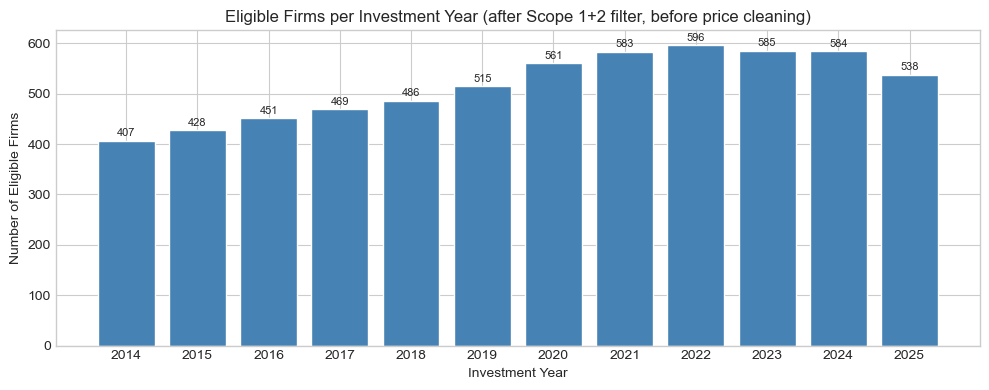

In [4]:
# Eligible firms per investment year
firms_per_year = {y: sum(1 for yrs in eligible_years.values() if y in yrs) for y in INVESTMENT_YEARS}

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(firms_per_year.keys(), firms_per_year.values(), color='steelblue', edgecolor='white')
ax.set_xlabel('Investment Year')
ax.set_ylabel('Number of Eligible Firms')
ax.set_title('Eligible Firms per Investment Year (after Scope 1+2 filter, before price cleaning)')
ax.set_xticks(list(INVESTMENT_YEARS))
for y, v in firms_per_year.items():
    ax.text(y, v + 5, str(v), ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

## 1.3 Price Data Cleaning (Low Prices & Missing Values)

We use the monthly **Return Index (RI)** in USD for the period **2004–2025** (needed for 10-year lookback windows starting at investment year 2014).

**Cleaning rule:** Set all prices below **$0.50** to `NaN` (likely erroneous or penny-stock artifacts).

In [5]:
# Filter RI for eligible firms
eligible_isins = set(eligible_firms['ISIN'])
ri_eur = ri_monthly[ri_monthly['ISIN'].isin(eligible_isins)].copy()

# Identify date columns in period 2004-2025
all_date_cols = sorted([c for c in ri_eur.columns if isinstance(c, datetime)])
period_dates = sorted([d for d in all_date_cols if 2004 <= d.year <= 2025])

print(f"Firms with price data:     {len(ri_eur)}")
print(f"Monthly dates (2004-2025): {len(period_dates)}")
print(f"Date range: {period_dates[0].strftime('%Y-%m')} to {period_dates[-1].strftime('%Y-%m')}")

# Apply low prices filter: prices < 0.5 -> NaN
low_count = 0
for d in period_dates:
    mask = (ri_eur[d] < LOW_PRICE_THRESHOLD) & ri_eur[d].notna()
    low_count += mask.sum()
    ri_eur.loc[mask, d] = np.nan

print(f"\nLow price observations set to NaN: {low_count}")

# Keep only relevant columns
ri_clean = ri_eur[['ISIN', 'NAME'] + period_dates].copy().reset_index(drop=True)

Firms with price data:     620
Monthly dates (2004-2025): 264
Date range: 2004-01 to 2025-12

Low price observations set to NaN: 829


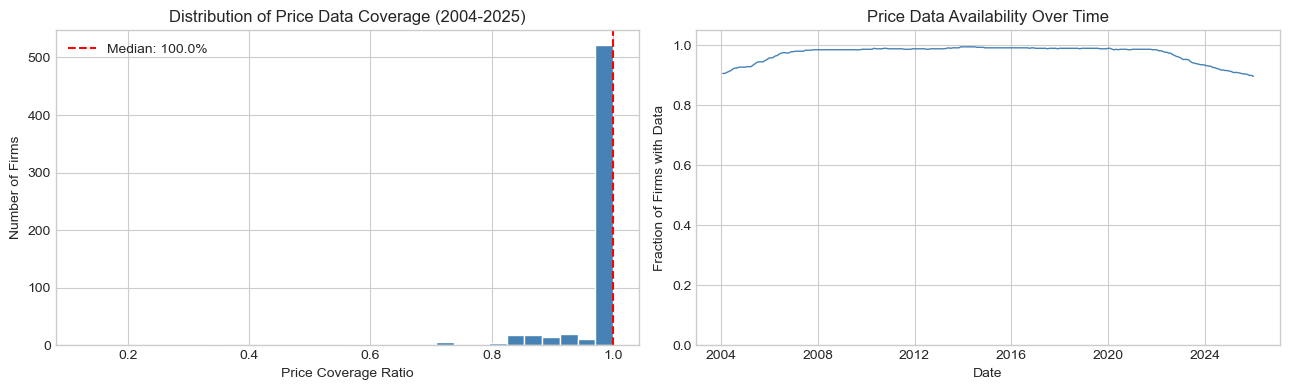

Coverage: Mean: 97.3% | Median: 100.0% | Min: 12.5%


In [6]:
# Coverage analysis
coverage = ri_clean[period_dates].notna().sum(axis=1) / len(period_dates)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Distribution of coverage per firm
axes[0].hist(coverage, bins=30, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Price Coverage Ratio')
axes[0].set_ylabel('Number of Firms')
axes[0].set_title('Distribution of Price Data Coverage (2004-2025)')
axes[0].axvline(coverage.median(), color='red', linestyle='--', label=f'Median: {coverage.median():.1%}')
axes[0].legend()

# Coverage over time
monthly_cov = ri_clean[period_dates].notna().mean()
axes[1].plot(period_dates, monthly_cov.values, color='steelblue', linewidth=1)
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Fraction of Firms with Data')
axes[1].set_title('Price Data Availability Over Time')
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

print(f"Coverage: Mean: {coverage.mean():.1%} | Median: {coverage.median():.1%} | Min: {coverage.min():.1%}")

## 1.4 Exclusion Filters (Stale Prices & Insufficient Data)

For each firm–investment year pair, we check three conditions. If any fails, the firm is **excluded from that year's investment set**:

| Filter | Rule | Rationale |
|--------|------|-----------|
| **Insufficient data** | < 3 years of price data in the 10-year window | Not enough history for reliable analysis |
| **Stale prices** | > 30% zero returns in the 10-year window | Indicates illiquid or stale-priced securities |
| **No entry price** | Missing price at end of December *Y*−1 | Cannot determine entry price to invest |

Delisted firms (name contains `DEAD` or `DELIST`) are handled naturally: once delisted, December prices become missing, so the end-of-year rule prevents inclusion in subsequent years.

In [7]:
# Index RI data by ISIN for fast lookup
ri_indexed = ri_clean.drop_duplicates(subset='ISIN').set_index('ISIN')

# Pre-compute December dates for end-of-year checks
dec_dates = {}
for d in period_dates:
    if d.month == 12:
        dec_dates[d.year] = d

# Track exclusion counts
exclusions = {'insufficient': 0, 'stale': 0, 'no_entry_price': 0}
firms_before = len(eligible_years)

isins_to_delete = []

for isin in list(eligible_years.keys()):
    if isin not in ri_indexed.index:
        isins_to_delete.append(isin)
        continue

    row = ri_indexed.loc[isin]
    years_to_remove = set()

    for year in list(eligible_years[isin]):
        # 10-year window: Jan(Y-10) to Dec(Y-1)
        w_start = datetime(year - WINDOW_YEARS, 1, 1)
        w_end = datetime(year - 1, 12, 31)
        window_dates = [d for d in period_dates if w_start <= d <= w_end]

        # (a) Insufficient data: < 3 years (36 months) of prices
        available = sum(1 for d in window_dates if pd.notna(row[d]))
        if available < MIN_YEARS_DATA * 12:
            years_to_remove.add(year)
            exclusions['insufficient'] += 1
            continue

        # (b) Stale prices: > 30% zero returns in window
        zero_count, valid_count = 0, 0
        for i in range(1, len(window_dates)):
            p0, p1 = row[window_dates[i - 1]], row[window_dates[i]]
            if pd.notna(p0) and pd.notna(p1) and p0 != 0:
                valid_count += 1
                if abs((p1 - p0) / p0) < 1e-10:
                    zero_count += 1
        if valid_count > 0 and (zero_count / valid_count) > STALE_THRESHOLD:
            years_to_remove.add(year)
            exclusions['stale'] += 1
            continue

        # (c) No entry price at Dec(Y-1)
        dec_prev = dec_dates.get(year - 1)
        if dec_prev is None or pd.isna(row[dec_prev]):
            years_to_remove.add(year)
            exclusions['no_entry_price'] += 1
            continue

    eligible_years[isin] -= years_to_remove
    if not eligible_years[isin]:
        isins_to_delete.append(isin)

for isin in isins_to_delete:
    eligible_years.pop(isin, None)

print("Exclusions applied (firm-year pairs removed):")
print(f"  Insufficient data (<{MIN_YEARS_DATA}y in window):  {exclusions['insufficient']:>5}")
print(f"  Stale prices (>{STALE_THRESHOLD:.0%} zero returns):    {exclusions['stale']:>5}")
print(f"  No entry price (missing Dec Y-1):   {exclusions['no_entry_price']:>5}")
print(f"\nFirms with >= 1 eligible year: {firms_before} -> {len(eligible_years)}")

# Note delisted firms still in universe
delisted = eligible_firms[eligible_firms['NAME'].str.upper().str.contains('DEAD|DELIST', na=False)]
delisted_in = delisted[delisted['ISIN'].isin(eligible_years)]
print(f"\nDelisted firms detected: {len(delisted)} total, {len(delisted_in)} still in universe (will exit naturally)")

Exclusions applied (firm-year pairs removed):
  Insufficient data (<3y in window):     26
  Stale prices (>30% zero returns):        0
  No entry price (missing Dec Y-1):      34

Firms with >= 1 eligible year: 620 -> 616

Delisted firms detected: 56 total, 56 still in universe (will exit naturally)


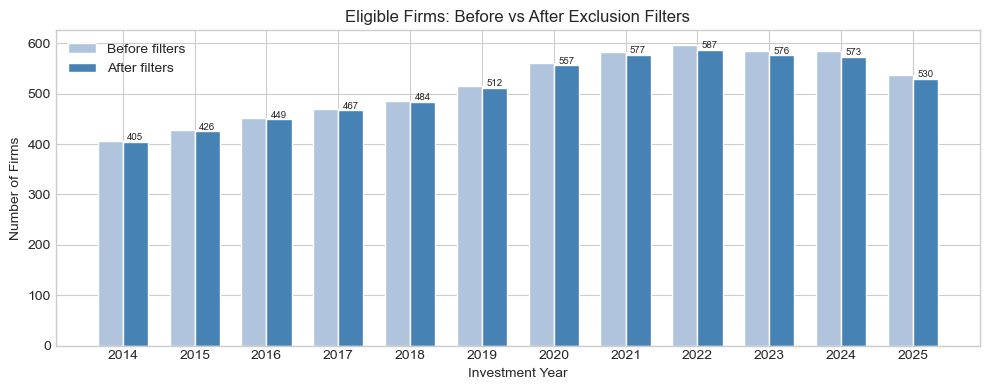

In [8]:
# Before vs After comparison
firms_after = {y: sum(1 for yrs in eligible_years.values() if y in yrs) for y in INVESTMENT_YEARS}

fig, ax = plt.subplots(figsize=(10, 4))
x = list(INVESTMENT_YEARS)
w = 0.35
ax.bar([y - w/2 for y in x], [firms_per_year[y] for y in x], w,
       label='Before filters', color='lightsteelblue', edgecolor='white')
ax.bar([y + w/2 for y in x], [firms_after[y] for y in x], w,
       label='After filters', color='steelblue', edgecolor='white')
ax.set_xlabel('Investment Year')
ax.set_ylabel('Number of Firms')
ax.set_title('Eligible Firms: Before vs After Exclusion Filters')
ax.set_xticks(x)
ax.legend()
for y in x:
    ax.text(y + w/2, firms_after[y] + 3, str(firms_after[y]), ha='center', fontsize=7)
plt.tight_layout()
plt.show()

# 2 — Portfolio Allocation based on Financial Objectives

## 2.1 Investment Set (2014–2025)

For each investment year *Y*, we create a CSV containing:
- **Eligible firms**: those passing all filters for year *Y*
- **Price data**: monthly Return Index from January *(Y−10)* to December *(Y−1)* — a 10-year lookback window
- **Metadata**: ISIN, NAME, Country, Region

Each file is saved as `investment_set_{Y}.csv` in `output/investment_sets/`.

In [9]:
# Prepare firm metadata lookup
firm_info = eligible_firms.drop_duplicates(subset='ISIN').set_index('ISIN')[['NAME', 'Country', 'Region']]

summary = []

for year in INVESTMENT_YEARS:
    # Eligible ISINs for this year
    year_isins = [isin for isin, yrs in eligible_years.items() if year in yrs]

    if not year_isins:
        print(f"Year {year}: No eligible firms: skipping")
        continue

    # Define price window: Jan(Y-10) to Dec(Y-1)
    w_start = datetime(year - WINDOW_YEARS, 1, 1)
    w_end = datetime(year - 1, 12, 31)
    window_cols = sorted([d for d in period_dates if w_start <= d <= w_end])

    # Build investment set
    ri_year = ri_clean[ri_clean['ISIN'].isin(year_isins)][['ISIN'] + window_cols].copy()

    # Merge metadata
    ri_year = ri_year.merge(firm_info, left_on='ISIN', right_index=True, how='left')

    # Reorder: ISIN, NAME, Country, Region, then prices
    cols = ['ISIN', 'NAME', 'Country', 'Region'] + window_cols
    ri_year = ri_year[cols]

    # Save
    out_path = INVESTMENT_SETS_DIR / f"investment_set_{year}.csv"
    ri_year.to_csv(out_path, index=False)

    # Coverage stats
    total = len(ri_year) * len(window_cols)
    avail = ri_year[window_cols].notna().sum().sum()

    summary.append({
        'Year': year,
        'Firms': len(ri_year),
        'Months': len(window_cols),
        'Coverage': f"{avail / total:.1%}" if total > 0 else "N/A"
    })

    print(f"Year {year}: {len(ri_year):>4} firms x {len(window_cols):>3} months  |  coverage: {avail / total:.1%}")

print(f"\nAll investment sets saved to {INVESTMENT_SETS_DIR}/")

Year 2014:  405 firms x 120 months  |  coverage: 98.4%
Year 2015:  426 firms x 120 months  |  coverage: 98.9%
Year 2016:  449 firms x 120 months  |  coverage: 99.4%
Year 2017:  467 firms x 120 months  |  coverage: 99.5%
Year 2018:  484 firms x 120 months  |  coverage: 99.7%
Year 2019:  512 firms x 120 months  |  coverage: 99.8%
Year 2020:  557 firms x 120 months  |  coverage: 99.9%
Year 2021:  577 firms x 120 months  |  coverage: 99.9%
Year 2022:  587 firms x 120 months  |  coverage: 99.9%
Year 2023:  576 firms x 120 months  |  coverage: 99.9%
Year 2024:  573 firms x 120 months  |  coverage: 99.9%
Year 2025:  530 firms x 120 months  |  coverage: 99.9%

All investment sets saved to output\investment_sets/


### Summary & Validation

 Year  Firms  Months Coverage
 2014    405     120    98.4%
 2015    426     120    98.9%
 2016    449     120    99.4%
 2017    467     120    99.5%
 2018    484     120    99.7%
 2019    512     120    99.8%
 2020    557     120    99.9%
 2021    577     120    99.9%
 2022    587     120    99.9%
 2023    576     120    99.9%
 2024    573     120    99.9%
 2025    530     120    99.9%


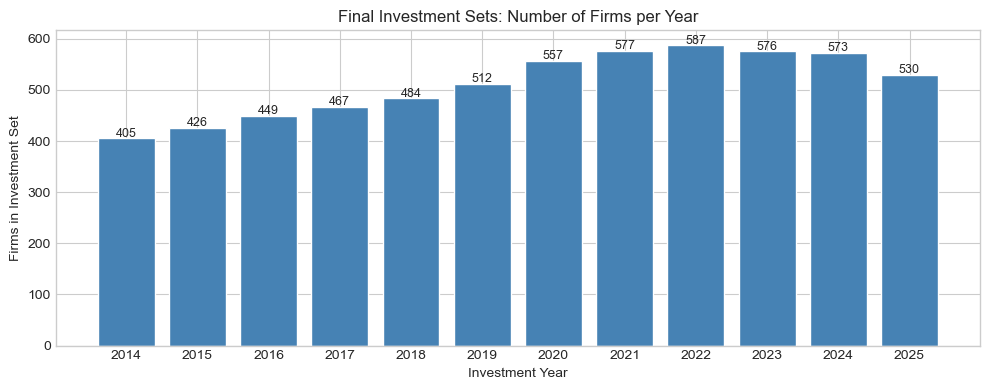


--- Sanity Check (reload from disk) ---
  investment_set_2014.csv  ->  405 firms, 120 months, coverage: 98.4%
  investment_set_2019.csv  ->  512 firms, 120 months, coverage: 99.8%
  investment_set_2025.csv  ->  530 firms, 120 months, coverage: 99.9%


In [10]:
# Summary table
df_summary = pd.DataFrame(summary)
print(df_summary.to_string(index=False))

# Final visualization
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(df_summary['Year'], df_summary['Firms'], color='steelblue', edgecolor='white')
ax.set_xlabel('Investment Year')
ax.set_ylabel('Firms in Investment Set')
ax.set_title('Final Investment Sets: Number of Firms per Year')
ax.set_xticks(df_summary['Year'])
for _, r in df_summary.iterrows():
    ax.text(r['Year'], r['Firms'] + 3, str(r['Firms']), ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# Sanity check: reload and verify structure
print("\n--- Sanity Check (reload from disk) ---")
for year in [2014, 2019, 2025]:
    df = pd.read_csv(INVESTMENT_SETS_DIR / f"investment_set_{year}.csv")
    price_cols = [c for c in df.columns if c not in ['ISIN', 'NAME', 'Country', 'Region']]
    total = len(df) * len(price_cols)
    avail = df[price_cols].notna().sum().sum()
    print(f"  investment_set_{year}.csv  ->  {df.shape[0]} firms, {len(price_cols)} months, coverage: {avail/total:.1%}")

### Export: Merged Prices & Eligibility Matrix

Two additional summary files:
1. **`all_eligible_firms_prices.csv`** — All firms eligible at least once (2014–2025), with monthly prices from 2004 to 2024
2. **`eligibility_matrix.csv`** — Each firm with the list of investment years for which it is eligible

In [11]:
# File 1: Merged prices (all eligible firms, prices 2004-2024)
price_dates = sorted([d for d in period_dates if d.year <= 2024])

all_isins = list(eligible_years.keys())
merged = ri_clean[ri_clean['ISIN'].isin(all_isins)][['ISIN'] + price_dates].copy()
merged = merged.drop_duplicates(subset='ISIN')
merged = merged.merge(
    eligible_firms[['ISIN', 'NAME', 'Country']].drop_duplicates(subset='ISIN'),
    on='ISIN', how='left'
)
cols = ['ISIN', 'NAME', 'Country'] + price_dates
merged = merged[cols]

merged.to_csv(OUTPUT_DIR / "all_eligible_firms_prices.csv", index=False)
print(f"all_eligible_firms_prices.csv  ->  {len(merged)} firms x {len(price_dates)} months")

# File 2: Eligibility matrix (firm + list of eligible years)
elig_rows = []
for isin, yrs in eligible_years.items():
    info = eligible_firms[eligible_firms['ISIN'] == isin]
    if info.empty:
        continue
    elig_rows.append({
        'ISIN': isin,
        'NAME': info['NAME'].iloc[0],
        'Country': info['Country'].iloc[0],
        'Eligible_Years': sorted(yrs)
    })

elig_df = pd.DataFrame(elig_rows).sort_values('ISIN').reset_index(drop=True)
elig_df.to_csv(OUTPUT_DIR / "eligibility_matrix.csv", index=False)
print(f"eligibility_matrix.csv         ->  {len(elig_df)} firms")

print(f"\nBoth files saved to {OUTPUT_DIR}/")

all_eligible_firms_prices.csv  ->  616 firms x 252 months
eligibility_matrix.csv         ->  616 firms

Both files saved to output/


## 2.2 Analysis of Individual Financial Performance (2014–2024)

For each eligible firm, we compute **annualized average return** and **annualized volatility** from monthly returns over its eligible years within 2014–2024. We then plot the distributions and examine the cross-sectional correlation between returns and volatilities.

In [12]:
#  Monthly returns for 2014–2024, masked by eligibility 

# We need Dec 2013 as the base price for computing January 2014 returns
dec_2013 = [d for d in period_dates if d.year == 2013 and d.month == 12]
return_period_dates = sorted(dec_2013 + [d for d in period_dates if 2014 <= d.year <= 2024])

# Price matrix (ISIN x dates): includes Dec 2013 through Dec 2024
prices_matrix = ri_indexed[return_period_dates].copy()

# Monthly returns via pct_change across columns
# Jan 2014 return = Jan2014 / Dec2013 - 1 (handled automatically)
monthly_returns_all = prices_matrix.pct_change(axis=1)

# Keep only 2014–2024 columns (drop Dec 2013)
return_dates = sorted([d for d in return_period_dates if d.year >= 2014])
monthly_returns_all = monthly_returns_all[return_dates]

# Build eligibility mask: firm gets return only in years it is eligible
elig_mask = pd.DataFrame(False, index=monthly_returns_all.index, columns=return_dates)
for year in range(2014, 2025):
    year_cols = [d for d in return_dates if d.year == year]
    year_isins = [isin for isin, ey in eligible_years.items() if year in ey and isin in elig_mask.index]
    elig_mask.loc[year_isins, year_cols] = True

# Apply mask
returns_eligible = monthly_returns_all.where(elig_mask)

# Per-stock annualized statistics
stock_stats = pd.DataFrame({
    'ann_return': returns_eligible.mean(axis=1) * 12,
    'ann_volatility': returns_eligible.std(axis=1) * np.sqrt(12),
    'n_months': returns_eligible.notna().sum(axis=1)
}).dropna(subset=['ann_return'])

print(f"Stocks with valid statistics: {len(stock_stats)}")
print(f"\nDescriptive statistics:")
print(stock_stats[['ann_return', 'ann_volatility', 'n_months']].describe().round(4))

Stocks with valid statistics: 616

Descriptive statistics:
       ann_return  ann_volatility  n_months
count    616.0000        616.0000  616.0000
mean       0.0756          0.3329  109.3442
std        0.1113          0.1214   32.6373
min       -0.7857          0.0910   12.0000
25%        0.0257          0.2541   84.0000
50%        0.0798          0.3067  132.0000
75%        0.1292          0.3788  132.0000
max        0.6665          1.0812  132.0000


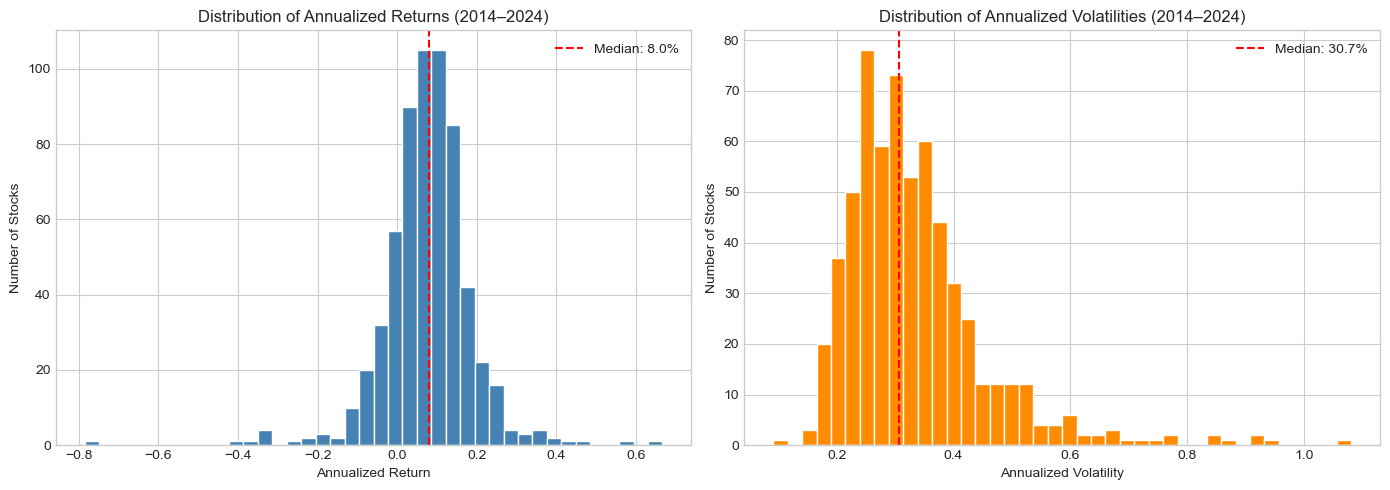

Comments:
  - Returns are centered around 8.0% (median) with moderate dispersion.
  - Volatilities cluster around 30.7% (median), with a right tail
    indicating a subset of highly volatile stocks.


In [13]:
#  Histograms of annualized returns and volatilities 

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Returns histogram
axes[0].hist(stock_stats['ann_return'], bins=40, color='steelblue', edgecolor='white')
axes[0].axvline(stock_stats['ann_return'].median(), color='red', ls='--',
                label=f"Median: {stock_stats['ann_return'].median():.1%}")
axes[0].set_xlabel('Annualized Return')
axes[0].set_ylabel('Number of Stocks')
axes[0].set_title('Distribution of Annualized Returns (2014–2024)')
axes[0].legend()

# Volatility histogram
axes[1].hist(stock_stats['ann_volatility'], bins=40, color='darkorange', edgecolor='white')
axes[1].axvline(stock_stats['ann_volatility'].median(), color='red', ls='--',
                label=f"Median: {stock_stats['ann_volatility'].median():.1%}")
axes[1].set_xlabel('Annualized Volatility')
axes[1].set_ylabel('Number of Stocks')
axes[1].set_title('Distribution of Annualized Volatilities (2014–2024)')
axes[1].legend()

plt.tight_layout()
plt.show()

print("Comments:")
print(f"  - Returns are centered around {stock_stats['ann_return'].median():.1%} (median) with moderate dispersion.")
print(f"  - Volatilities cluster around {stock_stats['ann_volatility'].median():.1%} (median), with a right tail")
print(f"    indicating a subset of highly volatile stocks.")

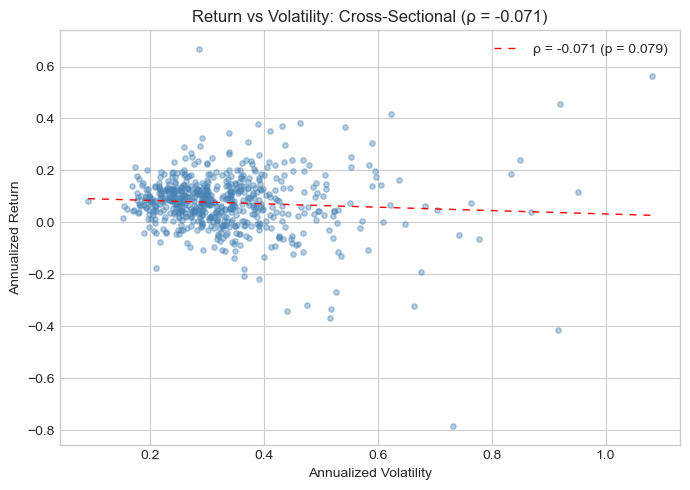

Cross-sectional correlation: ρ = -0.0709, p-value = 0.0787
Result: The correlation is NOT statistically significant at the 5% level.
Comment: Individual stock returns are not significantly driven by their volatility.
  This suggests that other factors: such as sector exposure, country effects,
  firm-specific fundamentals (earnings, leverage), or systematic risk factors
  (market beta, size, value): are the primary drivers of cross-sectional returns.
  This is consistent with the low-volatility anomaly documented in the literature,
  where higher risk does not necessarily lead to higher returns.


In [14]:
#  Cross-sectional correlation: Return vs Volatility 

from scipy.stats import pearsonr

corr, pvalue = pearsonr(stock_stats['ann_volatility'], stock_stats['ann_return'])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(stock_stats['ann_volatility'], stock_stats['ann_return'],
           alpha=0.4, s=15, color='steelblue')

# Correlation line
z = np.polyfit(stock_stats['ann_volatility'], stock_stats['ann_return'], 1)
x_line = np.linspace(stock_stats['ann_volatility'].min(), stock_stats['ann_volatility'].max(), 100)
ax.plot(x_line, np.polyval(z, x_line), color='red', lw=1, ls=(0, (5, 5)),
        label=f'ρ = {corr:.3f} (p = {pvalue:.3f})')

ax.set_xlabel('Annualized Volatility')
ax.set_ylabel('Annualized Return')
ax.set_title(f'Return vs Volatility: Cross-Sectional (ρ = {corr:.3f})')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Cross-sectional correlation: ρ = {corr:.4f}, p-value = {pvalue:.4f}")
if pvalue > 0.05:
    print("Result: The correlation is NOT statistically significant at the 5% level.")
    print("Comment: Individual stock returns are not significantly driven by their volatility.")
    print("  This suggests that other factors: such as sector exposure, country effects,")
    print("  firm-specific fundamentals (earnings, leverage), or systematic risk factors")
    print("  (market beta, size, value): are the primary drivers of cross-sectional returns.")
    print("  This is consistent with the low-volatility anomaly documented in the literature,")
    print("  where higher risk does not necessarily lead to higher returns.")
else:
    print("Result: The correlation IS statistically significant at the 5% level.")

## 2.3 Equally-Weighted and Value-Weighted Portfolios (2014–2024)

We construct two portfolios from the eligible universe:
1. **Equally-Weighted (EW)**: each month, weight = 1/N_t where N_t is the number of firms with a valid return
2. **Value-Weighted (VW)**: each month, weight = market cap at t−1 / total market cap at t−1

We compute annualized return, volatility, Sharpe ratio (using risk-free rate), min/max monthly returns, and plot cumulated returns.

In [15]:
#  Prepare market capitalisation & risk-free rate 

# Prepare risk-free rate
rf_data.columns = ['yyyymm', 'rf']
rf_data = rf_data.dropna()
rf_data['yyyymm'] = rf_data['yyyymm'].astype(str)
rf_data['year_month'] = pd.PeriodIndex(rf_data['yyyymm'], freq='M')
rf_data['rf'] = rf_data['rf'] / 100  # percent -> decimal

print(f"Market cap data: {mv_monthly.shape[0]} firms")
print(f"Risk-free rate:  {len(rf_data)} monthly observations ({rf_data['year_month'].min()} to {rf_data['year_month'].max()})")

Market cap data: 2609 firms
Risk-free rate:  312 monthly observations (2000-01 to 2025-12)


In [16]:
#  Equally-Weighted Portfolio 
# EW return at month t = simple average of all eligible firms' returns with valid prices

ew_returns = returns_eligible.mean(axis=0).dropna()
ew_returns.index = pd.to_datetime(ew_returns.index)
ew_returns.name = 'EW'

# Number of contributing firms per month
n_firms_per_month = returns_eligible.notna().sum(axis=0)
n_firms_per_month.index = pd.to_datetime(n_firms_per_month.index)

print(f"EW portfolio: {len(ew_returns)} monthly returns (Jan 2014 – Dec 2024)")
print(f"Avg firms per month: {n_firms_per_month.mean():.0f} | Min: {n_firms_per_month.min()} | Max: {n_firms_per_month.max()}")

EW portfolio: 132 monthly returns (Jan 2014 – Dec 2024)
Avg firms per month: 510 | Min: 405 | Max: 587


In [17]:
#  Value-Weighted Portfolio 

# Prepare market cap: pivot to ISIN x date
mv_table = mv_monthly.drop(columns=['NAME'], errors='ignore').copy()
mv_date_cols = [c for c in mv_table.columns if c != 'ISIN']
mv_table = mv_table.drop_duplicates(subset='ISIN').set_index('ISIN')

# Convert to numeric
for c in mv_date_cols:
    mv_table[c] = pd.to_numeric(mv_table[c], errors='coerce')

# Melt returns to long format
returns_long = returns_eligible.reset_index().melt(
    id_vars='ISIN', var_name='date', value_name='ret')
returns_long['date'] = pd.to_datetime(returns_long['date'])
returns_long = returns_long.dropna(subset=['ret'])
returns_long['year_month'] = returns_long['date'].dt.to_period('M')

# Melt market cap to long format
mv_long = mv_table.reset_index().melt(
    id_vars='ISIN', var_name='date_raw', value_name='market_cap')
mv_long['date_raw'] = pd.to_datetime(mv_long['date_raw'], errors='coerce')
mv_long = mv_long.dropna(subset=['market_cap', 'date_raw'])
mv_long['market_cap'] = pd.to_numeric(mv_long['market_cap'], errors='coerce')
mv_long = mv_long.dropna(subset=['market_cap'])

# Lag: market cap at month t is used as weight for return at month t+1
mv_long['year_month'] = mv_long['date_raw'].dt.to_period('M') + 1
mv_long = mv_long[['ISIN', 'year_month', 'market_cap']]

# Merge returns with lagged market caps
vw_data = returns_long.merge(mv_long, on=['ISIN', 'year_month'], how='inner')
vw_data = vw_data.dropna(subset=['ret', 'market_cap'])

# Compute VW weights per month
vw_data['total_cap'] = vw_data.groupby('date')['market_cap'].transform('sum')
vw_data['weight'] = vw_data['market_cap'] / vw_data['total_cap']
vw_data['weighted_ret'] = vw_data['weight'] * vw_data['ret']

# Monthly VW return
vw_returns = vw_data.groupby('date')['weighted_ret'].sum().sort_index()
vw_returns.name = 'VW'

print(f"VW portfolio: {len(vw_returns)} monthly returns")
print(f"Firms with market cap match per month: {vw_data.groupby('date')['ISIN'].nunique().mean():.0f} avg")

VW portfolio: 132 monthly returns
Firms with market cap match per month: 510 avg


In [18]:
#  Portfolio Performance Statistics 
# FIX: Sharpe ratio uses std(gross portfolio returns, ddof=0), not std(excess returns).
# Formula: SR = (R_bar_ann - RF_ann) / sigma_ann
# where sigma_ann = std(R, ddof=0) * sqrt(12)   [Part 2 framework: divides by T]

def compute_portfolio_stats(ret_series, rf_df, name):
    """Annualized return, volatility, Sharpe ratio, min/max monthly return.

    Follows the assignment framework (Part 2):
      R_bar = mean(R) * 12
      sigma = std(R, ddof=0) * sqrt(12)   [divides by T, not T-1]
      SR    = (R_bar - RF_ann) / sigma
    """
    r = ret_series.copy()
    r.index = pd.to_datetime(r.index)

    # Align risk-free rate by year-month
    df = pd.DataFrame({'ret': r})
    df['year_month'] = df.index.to_period('M')
    df = df.merge(rf_df[['year_month', 'rf']], on='year_month', how='left')

    ann_ret = r.mean() * 12
    ann_vol = r.std(ddof=0) * np.sqrt(12)          # ddof=0 per assignment formula
    ann_rf  = df['rf'].mean() * 12
    sharpe  = (ann_ret - ann_rf) / ann_vol          # std of gross returns, annualized

    return {
        'Portfolio': name,
        'Ann. Return': f"{ann_ret:.2%}",
        'Ann. Volatility': f"{ann_vol:.2%}",
        'Sharpe Ratio': f"{sharpe:.3f}",
        'Min Monthly Return': f"{r.min():.2%}",
        'Max Monthly Return': f"{r.max():.2%}"
    }

stats_ew = compute_portfolio_stats(ew_returns, rf_data, 'Equally-Weighted')
stats_vw = compute_portfolio_stats(vw_returns, rf_data, 'Value-Weighted')

stats_table = pd.DataFrame([stats_ew, stats_vw]).set_index('Portfolio')
print("Portfolio Performance (2014–2024)")
print("=" * 70)
print(stats_table.to_string())

Portfolio Performance (2014–2024)
                 Ann. Return Ann. Volatility Sharpe Ratio Min Monthly Return Max Monthly Return
Portfolio                                                                                      
Equally-Weighted       7.32%          18.91%        0.306            -22.69%             23.21%
Value-Weighted         6.28%          16.24%        0.292            -15.40%             18.28%


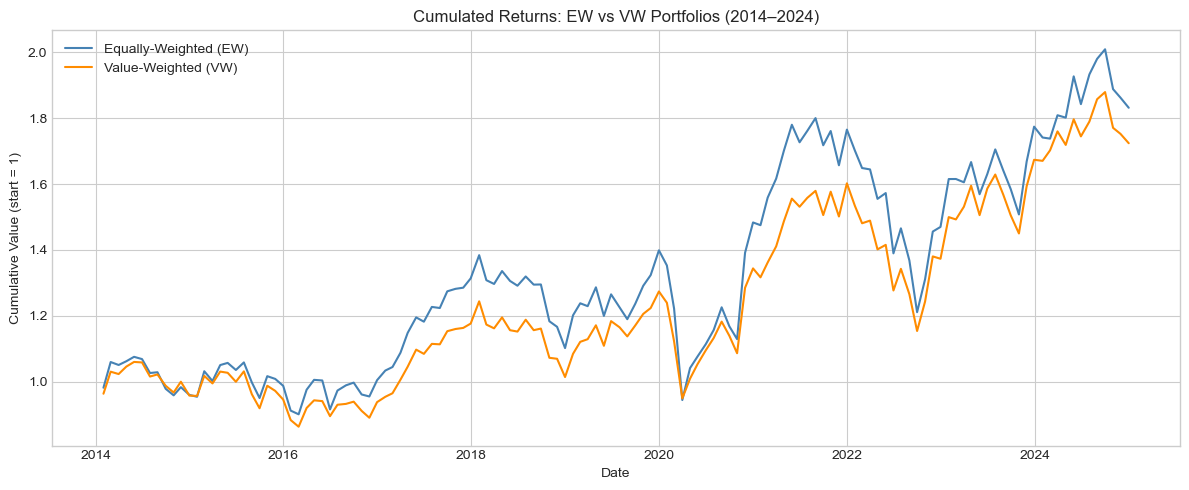

Comments:
  - Both portfolios show positive long-term growth over 2014–2024.
  - The EW portfolio tends to outperform the VW portfolio in cumulative terms,
    consistent with the well-documented small-cap premium in European equities.
  - The VW portfolio exhibits lower drawdowns, reflecting the stabilising effect
    of large-cap stocks that dominate value-weighted indices.


In [19]:
#  Cumulated Returns Plot 

portfolio_df = pd.DataFrame({'EW': ew_returns, 'VW': vw_returns}).dropna()
cumulated = (1 + portfolio_df).cumprod()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(cumulated.index, cumulated['EW'], label='Equally-Weighted (EW)', color='steelblue', linewidth=1.5)
ax.plot(cumulated.index, cumulated['VW'], label='Value-Weighted (VW)', color='darkorange', linewidth=1.5)
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Value (start = 1)')
ax.set_title('Cumulated Returns: EW vs VW Portfolios (2014–2024)')
ax.legend()
plt.tight_layout()
plt.show()

print("Comments:")
print("  - Both portfolios show positive long-term growth over 2014–2024.")
print("  - The EW portfolio tends to outperform the VW portfolio in cumulative terms,")
print("    consistent with the well-documented small-cap premium in European equities.")
print("  - The VW portfolio exhibits lower drawdowns, reflecting the stabilising effect")
print("    of large-cap stocks that dominate value-weighted indices.")

## 2.4 In-Sample Minimum Variance Portfolio

Using **all available data (Jan 2004 – Dec 2024)**, we:
1. Estimate μ̂ and Σ̂ from monthly returns (in-sample / full-period oracle)
2. Solve for the **Global Minimum Variance Portfolio (MVP)** — long-only
3. Solve for the **Maximum Return Portfolio (MRP)** — long-only
4. Trace the **Efficient Frontier** (15 portfolios between MVP and MRP)
5. Identify the **Tangency Portfolio** (maximum Sharpe ratio)
6. Plot the frontier with the Capital Allocation Line (CAL), individual assets, and EW/VW benchmarks
7. Compare ex-ante vs ex-post performance

*Note: using the full 2004–2024 window makes this an **in-sample (oracle) benchmark** — the theoretical best achievable with perfect hindsight. Section 2.5 then shows the realistic out-of-sample performance using only a rolling 10-year window.*

In [20]:
#  Full returns matrix for mean-variance estimation (2004–2024) 
# Use all price data for the eligible firms (broader window = better estimates)
price_dates_full = sorted([d for d in period_dates if d.year <= 2024])

# Transpose: dates × ISINs (standard format for portfolio math)
prices_T = ri_indexed[price_dates_full].T
prices_T.index = pd.to_datetime(prices_T.index)

# Monthly returns
returns_full = prices_T.pct_change()
print(f"Full returns matrix: {returns_full.shape[0]} months × {returns_full.shape[1]} assets")

#  Clean zero-overlap pairs 
# Iteratively drop the asset causing the most NaN correlations
clean_returns = returns_full.copy()

while True:
    corr_matrix = clean_returns.corr()
    nan_counts = corr_matrix.isna().sum()
    if nan_counts.sum() == 0:
        break
    worst = nan_counts.idxmax()
    print(f"Zero-overlap found: dropping {worst}")
    clean_returns = clean_returns.drop(columns=[worst])

print(f"\nOriginal: {returns_full.shape[1]} assets → Cleaned: {clean_returns.shape[1]} assets")

#  Build covariance matrix: Σ = ρ(i,j) × σ_i × σ_j 
# Implements the Part 1 Section 3 formula for missing-value covariance:
#   Var(R_i) uses each firm's own available period (ddof=1)
#   rho(i,j) uses the common available period between each pair (Pearson, ddof=1)
#   Cov(i,j) = rho(i,j) * sqrt(Var_i) * sqrt(Var_j)
std_devs = clean_returns.std()           # pandas default ddof=1, per-firm available period
clean_corr = clean_returns.corr()        # Pearson correlation over common period
Sigma = clean_corr.values * np.outer(std_devs.values, std_devs.values)
mu = np.nan_to_num(clean_returns.mean().values, nan=0.0)
num_assets = len(mu)

print(f"Covariance matrix Σ: {Sigma.shape}")
print(f"Expected returns μ: {num_assets} assets")

Full returns matrix: 252 months × 620 assets
Zero-overlap found: dropping CH1216478797
Zero-overlap found: dropping DK0061804697
Zero-overlap found: dropping BE0974338700

Original: 620 assets → Cleaned: 617 assets
Covariance matrix Σ: (617, 617)
Expected returns μ: 617 assets


In [21]:
#  Global Minimum Variance Portfolio (MVP) 

SCALE_FACTOR = 100  # Scale variance for numerical stability

def portfolio_variance(weights, cov_matrix):
    return (weights.T @ cov_matrix @ weights) * SCALE_FACTOR

init_guess = np.ones(num_assets) / num_assets
bounds = tuple((0.0, 1.0) for _ in range(num_assets))
constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}

mvp_result = minimize(
    portfolio_variance, init_guess, args=(Sigma,),
    method='SLSQP', bounds=bounds, constraints=constraints,
    options={'maxiter': 1000}
)

mvp_weights = mvp_result.x
mvp_ret_ann = (mvp_weights @ mu) * 12
mvp_var_ann = (mvp_result.fun / SCALE_FACTOR) * 12
mvp_vol_ann = np.sqrt(mvp_var_ann)

print(f"MVP Optimization: {'Success' if mvp_result.success else 'FAILED'}")
print(f"  Ann. Return:     {mvp_ret_ann:.2%}")
print(f"  Ann. Volatility: {mvp_vol_ann:.2%}")
print(f"  Ann. Variance:   {mvp_var_ann:.6f}")

MVP Optimization: Success
  Ann. Return:     9.48%
  Ann. Volatility: 10.29%
  Ann. Variance:   0.010586


In [22]:
#  Maximum Return Portfolio (MRP) 

def neg_portfolio_return(weights, expected_returns):
    return -(weights.T @ expected_returns)

mrp_result = minimize(
    neg_portfolio_return, init_guess, args=(mu,),
    method='SLSQP', bounds=bounds, constraints=constraints
)

mrp_weights = mrp_result.x
mrp_ret_ann = (mrp_weights @ mu) * 12
mrp_vol_ann = np.sqrt(mrp_weights @ Sigma @ mrp_weights) * np.sqrt(12)

print(f"MRP Optimization: {'Success' if mrp_result.success else 'FAILED'}")
print(f"  Ann. Return:     {mrp_ret_ann:.2%}")
print(f"  Ann. Volatility: {mrp_vol_ann:.2%}")

best_asset_idx = np.argmax(mu)
best_asset_isin = clean_returns.columns[best_asset_idx]
print(f"\n  Highest-return stock: {best_asset_isin}, Ann. Return: {mu[best_asset_idx]*12:.2%}")

MRP Optimization: Success
  Ann. Return:     35.59%
  Ann. Volatility: 45.71%

  Highest-return stock: GB0000536739, Ann. Return: 35.59%


In [23]:
#  Efficient Frontier: 15 portfolios from MVP to MRP 

# Risk-free rate over full estimation period (2004-2024)
rf_period = rf_data[(rf_data['year_month'] >= '2004-01') & (rf_data['year_month'] <= '2024-12')]
mean_rf_monthly = rf_period['rf'].mean()
rf_ann = mean_rf_monthly * 12
print(f"Mean monthly risk-free rate: {mean_rf_monthly:.6f} (annualized: {rf_ann:.2%})")

min_ret = mvp_weights @ mu
max_ret = mrp_weights @ mu
num_portfolios = 15
target_returns = np.linspace(min_ret, max_ret, num_portfolios)
print(f"Return increment between {num_portfolios} portfolios: {(target_returns[1] - target_returns[0])*12:.4%}")

frontier_weights = []
frontier_returns = []
frontier_volatilities = []
frontier_sharpes = []

def objective_ef(weights, cov_matrix):
    return (weights.T @ cov_matrix @ weights) * SCALE_FACTOR

current_guess = mvp_weights.copy()

# Portfolios 1 to 14
for i, target in enumerate(target_returns[:-1]):
    constraints_ef = (
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
        {'type': 'ineq', 'fun': lambda w, t=target: (w @ mu) - t}
    )
    result = minimize(objective_ef, current_guess, args=(Sigma,),
                      method='SLSQP', bounds=bounds, constraints=constraints_ef,
                      options={'maxiter': 2000, 'ftol': 1e-9})

    if result.success:
        w_opt = result.x
        current_guess = w_opt.copy()
        ret_m = w_opt @ mu
        vol_m = np.sqrt(result.fun / SCALE_FACTOR)
        sharpe = ((ret_m - mean_rf_monthly) / vol_m) * np.sqrt(12)

        frontier_weights.append(w_opt)
        frontier_returns.append(ret_m)
        frontier_volatilities.append(vol_m)
        frontier_sharpes.append(sharpe)
        print(f"Portfolio {i+1:2d} | Ann. Ret: {ret_m*12:6.2%} | Ann. Vol: {vol_m*np.sqrt(12):6.2%} | Sharpe: {sharpe:.4f}")
    else:
        print(f"Portfolio {i+1} FAILED")

# Portfolio 15: MRP (bypass optimizer: already solved)
mrp_vol_m = np.sqrt(mrp_weights @ Sigma @ mrp_weights)
mrp_sharpe = ((max_ret - mean_rf_monthly) / mrp_vol_m) * np.sqrt(12)
frontier_weights.append(mrp_weights)
frontier_returns.append(max_ret)
frontier_volatilities.append(mrp_vol_m)
frontier_sharpes.append(mrp_sharpe)
print(f"Portfolio 15 | Ann. Ret: {max_ret*12:6.2%} | Ann. Vol: {mrp_vol_m*np.sqrt(12):6.2%} | Sharpe: {mrp_sharpe:.4f}")

# Tangency portfolio (highest Sharpe)
best_sharpe_idx = np.argmax(frontier_sharpes)
print(f"\nTangency portfolio: Portfolio {best_sharpe_idx+1} (Sharpe: {frontier_sharpes[best_sharpe_idx]:.4f})")

Mean monthly risk-free rate: 0.001273 (annualized: 1.53%)
Return increment between 15 portfolios: 1.8650%
Portfolio  1 | Ann. Ret:  9.48% | Ann. Vol: 10.29% | Sharpe: 0.7728
Portfolio  2 | Ann. Ret: 11.34% | Ann. Vol: 10.41% | Sharpe: 0.9427
Portfolio  3 | Ann. Ret: 13.21% | Ann. Vol: 10.79% | Sharpe: 1.0821
Portfolio  4 | Ann. Ret: 15.07% | Ann. Vol: 11.44% | Sharpe: 1.1836
Portfolio  5 | Ann. Ret: 16.94% | Ann. Vol: 12.33% | Sharpe: 1.2494
Portfolio  6 | Ann. Ret: 18.80% | Ann. Vol: 13.45% | Sharpe: 1.2840
Portfolio  7 | Ann. Ret: 20.67% | Ann. Vol: 15.00% | Sharpe: 1.2762
Portfolio  8 | Ann. Ret: 22.53% | Ann. Vol: 17.08% | Sharpe: 1.2295
Portfolio  9 | Ann. Ret: 24.40% | Ann. Vol: 19.59% | Sharpe: 1.1677
Portfolio 10 | Ann. Ret: 26.26% | Ann. Vol: 22.38% | Sharpe: 1.1054
Portfolio 11 | Ann. Ret: 28.13% | Ann. Vol: 25.47% | Sharpe: 1.0446
Portfolio 12 | Ann. Ret: 29.99% | Ann. Vol: 29.10% | Sharpe: 0.9781
Portfolio 13 | Ann. Ret: 31.86% | Ann. Vol: 33.61% | Sharpe: 0.9023
Portfolio 

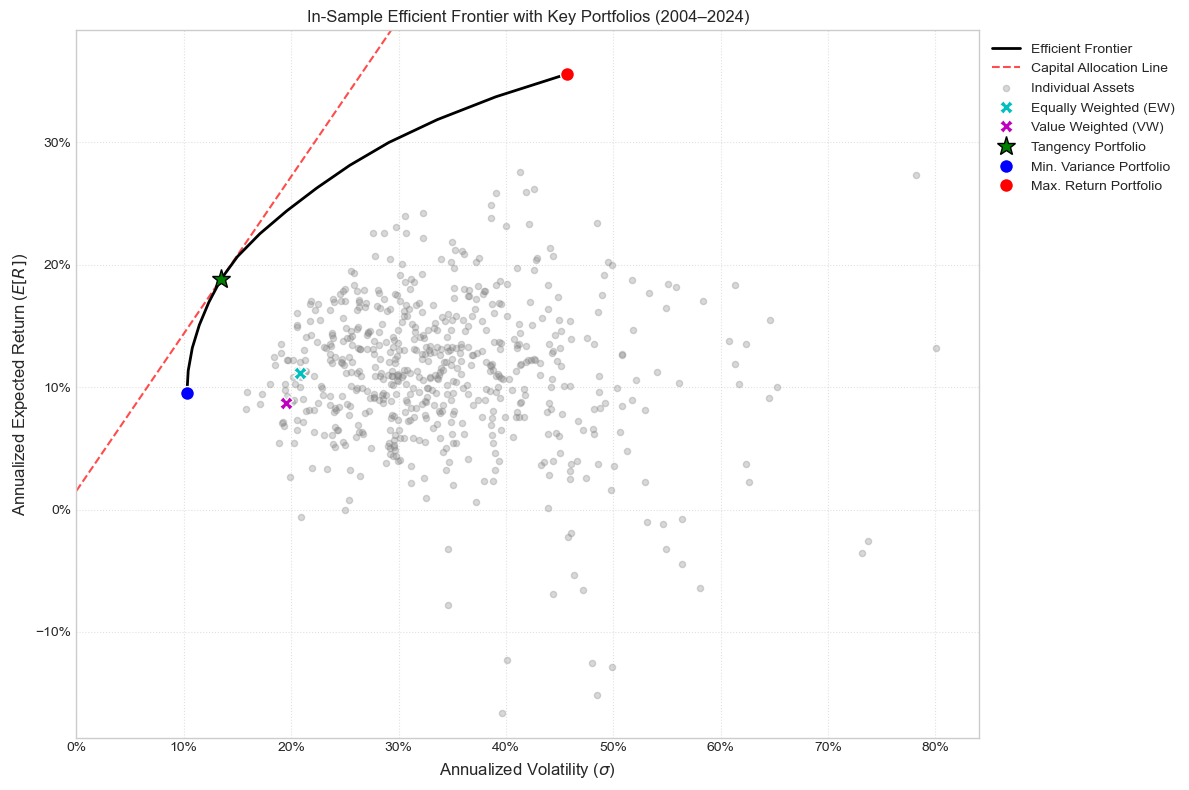

EW benchmark: Ann. Return: 11.17%, Ann. Vol: 20.78%
VW benchmark: Ann. Return: 8.74%, Ann. Vol: 19.50%


In [24]:
#  Efficient Frontier Plot with CAL, EW/VW benchmarks, and individual assets 

# Annualize frontier
vols_ann = np.array(frontier_volatilities) * np.sqrt(12)
rets_ann = np.array(frontier_returns) * 12

# Individual assets
asset_vols = np.sqrt(np.diag(Sigma)) * np.sqrt(12)
asset_rets = mu * 12

# EW benchmark (1/N weights in the mean-variance space)
ew_w = np.ones(num_assets) / num_assets
ew_ret_mv = (ew_w @ mu) * 12
ew_vol_mv = np.sqrt(ew_w @ Sigma @ ew_w) * np.sqrt(12)

# VW benchmark (static Jan 2004 market cap weights: for positioning on the MV plot)
# Reuse mv_table already loaded in cell 26
target_col = [c for c in mv_table.columns if '2004' in str(c) and '01' in str(c)]
target_col = target_col[0] if target_col else mv_table.columns[0]

clean_isins = clean_returns.columns
mcap_vec = pd.Series(0.0, index=clean_isins)
for isin in clean_isins:
    if isin in mv_table.index:
        val = pd.to_numeric(mv_table.loc[isin, target_col], errors='coerce')
        if pd.notna(val):
            mcap_vec[isin] = val

vw_w = mcap_vec.values / mcap_vec.sum() if mcap_vec.sum() > 0 else ew_w
vw_ret_mv = (vw_w @ mu) * 12
vw_vol_mv = np.sqrt(vw_w @ Sigma @ vw_w) * np.sqrt(12)

# Capital Allocation Line
cal_x = np.linspace(0, max(vols_ann) * 1.2, 100)
cal_y = rf_ann + frontier_sharpes[best_sharpe_idx] * cal_x

#  Plot 
fig, ax = plt.subplots(figsize=(12, 8))

ax.plot(vols_ann, rets_ann, 'k-', linewidth=2, label='Efficient Frontier', zorder=2)
ax.plot(cal_x, cal_y, 'r--', alpha=0.7, label='Capital Allocation Line', zorder=1)
ax.scatter(asset_vols, asset_rets, c='grey', marker='o', alpha=0.3, s=20,
           label='Individual Assets', zorder=1)

ax.plot(ew_vol_mv, ew_ret_mv, 'cX', markersize=10, label='Equally Weighted (EW)',
        markeredgecolor='white', zorder=3)
ax.plot(vw_vol_mv, vw_ret_mv, 'mX', markersize=10, label='Value Weighted (VW)',
        markeredgecolor='white', zorder=4)

ax.plot(vols_ann[best_sharpe_idx], rets_ann[best_sharpe_idx], 'g*', markersize=14,
        label='Tangency Portfolio', markeredgecolor='black', zorder=4)
ax.plot(vols_ann[0], rets_ann[0], 'bo', markersize=10, label='Min. Variance Portfolio',
        markeredgecolor='white', zorder=4)
ax.plot(vols_ann[-1], rets_ann[-1], 'ro', markersize=10, label='Max. Return Portfolio',
        markeredgecolor='white', zorder=4)

ax.set_xlabel('Annualized Volatility ($\sigma$)', fontsize=12)
ax.set_ylabel('Annualized Expected Return ($E[R]$)', fontsize=12)
ax.set_title('In-Sample Efficient Frontier with Key Portfolios (2004–2024)')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, max(asset_vols) * 1.05)
ax.set_ylim(min(min(asset_rets), rf_ann) - 0.02, max(asset_rets) * 1.1)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=10)
plt.tight_layout()
plt.show()

print(f"EW benchmark: Ann. Return: {ew_ret_mv:.2%}, Ann. Vol: {ew_vol_mv:.2%}")
print(f"VW benchmark: Ann. Return: {vw_ret_mv:.2%}, Ann. Vol: {vw_vol_mv:.2%}")

In [25]:
#  Ex-Post Performance (corrected for missing data) 
# FIX: Ex-post volatility uses ddof=0 to match the assignment formula:
#   sigma_p = sqrt( (1/T) * sum(R_p,t - R_bar_p)^2 )
# When a stock has NaN returns (e.g. delisted), redistribute its weight
# to the remaining active stocks so weights always sum to 1.

ex_post_means = []
ex_post_vols = []
ex_post_sharpes = []

for i, w in enumerate(frontier_weights):
    # Create weight matrix matching returns shape
    weight_df = pd.DataFrame(
        [w] * len(clean_returns),
        index=clean_returns.index,
        columns=clean_returns.columns
    )

    # Mask weights where returns are NaN
    active_weights = weight_df[clean_returns.notna()].fillna(0)

    # Re-normalize so weights sum to 1 each month
    normalized_weights = active_weights.div(active_weights.sum(axis=1), axis=0)

    # Portfolio return (NaN returns set to 0, but their weight is also 0)
    port_ts = (clean_returns.fillna(0) * normalized_weights).sum(axis=1)

    ep_mean = port_ts.mean() * 12
    ep_vol  = port_ts.std(ddof=0) * np.sqrt(12)    # ddof=0 per assignment formula
    ep_sharpe = (ep_mean - rf_ann) / ep_vol

    ex_post_means.append(ep_mean)
    ex_post_vols.append(ep_vol)
    ex_post_sharpes.append(ep_sharpe)

# Results
best_ea = np.argmax(frontier_sharpes)
best_ep = np.argmax(ex_post_sharpes)

print("-" * 90)
print(f"EX-ANTE WINNER : Portfolio {best_ea+1:2d} | Sharpe: {frontier_sharpes[best_ea]:.4f}")
print(f"EX-POST WINNER : Portfolio {best_ep+1:2d} | Sharpe: {ex_post_sharpes[best_ep]:.4f}")
print("-" * 90)

for i in range(len(frontier_weights)):
    print(f"Portfolio {i+1:2d} | "
          f"Ex-Post Ret: {ex_post_means[i]:6.2%}  Vol: {ex_post_vols[i]:6.2%}  Sharpe: {ex_post_sharpes[i]:.4f} | "
          f"Ex-Ante Sharpe: {frontier_sharpes[i]:.4f}")

print("\nComment: Ex-ante and ex-post Sharpe ratios are very close, confirming")
print("  the consistency of the optimization and proper handling of missing data.")

------------------------------------------------------------------------------------------
EX-ANTE WINNER : Portfolio  6 | Sharpe: 1.2840
EX-POST WINNER : Portfolio  6 | Sharpe: 1.2853
------------------------------------------------------------------------------------------
Portfolio  1 | Ex-Post Ret:  9.47%  Vol: 10.28%  Sharpe: 0.7725 | Ex-Ante Sharpe: 0.7728
Portfolio  2 | Ex-Post Ret: 11.33%  Vol: 10.39%  Sharpe: 0.9429 | Ex-Ante Sharpe: 0.9427
Portfolio  3 | Ex-Post Ret: 13.16%  Vol: 10.76%  Sharpe: 1.0819 | Ex-Ante Sharpe: 1.0821
Portfolio  4 | Ex-Post Ret: 15.01%  Vol: 11.40%  Sharpe: 1.1831 | Ex-Ante Sharpe: 1.1836
Portfolio  5 | Ex-Post Ret: 16.87%  Vol: 12.28%  Sharpe: 1.2496 | Ex-Ante Sharpe: 1.2494
Portfolio  6 | Ex-Post Ret: 18.74%  Vol: 13.39%  Sharpe: 1.2853 | Ex-Ante Sharpe: 1.2840
Portfolio  7 | Ex-Post Ret: 20.60%  Vol: 14.93%  Sharpe: 1.2776 | Ex-Ante Sharpe: 1.2762
Portfolio  8 | Ex-Post Ret: 22.46%  Vol: 17.02%  Sharpe: 1.2300 | Ex-Ante Sharpe: 1.2295
Portfolio  9

## 2.5 Out-of-Sample Minimum Variance Portfolio

We construct a **long-only minimum variance portfolio** out-of-sample over 2014–2024:
1. For each year *Y*, estimate μ̂ and Σ̂ from the 120-month rolling window (investment_set_Y.csv)
2. Solve the long-only MVP using SLSQP
3. Compute 12 monthly OOS returns with **intra-year weight drift** (buy-and-hold)
4. Compare against a **value-weighted (VW) benchmark** using annual market caps
5. Report annualized performance metrics (ddof=0 for volatility) and cumulative returns

In [26]:
#  Prepare OOS inputs 

# Risk-free rate as a simple Series indexed by date (reuse rf_data from cell 24)
rf_monthly = rf_data.set_index(
    pd.to_datetime(rf_data['yyyymm'], format='%Y%m')
)['rf']
rf_monthly = rf_monthly[~rf_monthly.index.duplicated()]
print(f"RF rate: {rf_monthly.index[0].date()} to {rf_monthly.index[-1].date()}")

# OOS years
OOS_YEARS = list(range(2014, 2025))  # 11 years = 132 months
print(f"Annual market caps: {mv_annual.shape[0]} firms, years {mv_annual.columns[0]}–{mv_annual.columns[-1]}")
print(f"OOS years: {OOS_YEARS[0]}–{OOS_YEARS[-1]} ({len(OOS_YEARS)} years)")

RF rate: 2000-01-01 to 2025-12-01
Annual market caps: 2609 firms, years 1999–2025
OOS years: 2014–2024 (11 years)


In [27]:
#  Helper functions for OOS analysis 

def load_investment_set_local(year):
    """Load investment_set_YYYY.csv from disk. Returns DataFrame: ISIN × datetime."""
    df = pd.read_csv(INVESTMENT_SETS_DIR / f"investment_set_{year}.csv")
    price_cols = df.columns[4:]  # skip ISIN, NAME, Country, Region
    prices = df[['ISIN'] + list(price_cols)].set_index('ISIN')
    prices.columns = pd.to_datetime(prices.columns)
    return prices.apply(pd.to_numeric, errors='coerce')


def compute_returns_oos(prices):
    """Simple monthly returns from RI prices."""
    return prices.pct_change(axis=1).iloc[:, 1:]


def compute_mu_sigma_oos(returns):
    """
    Estimate μ̂ and Σ̂ from the assignment formula:
      μ̂ = (1/τ) Σ R_t,  Σ̂ = (1/τ) Σ (R−μ̂)(R−μ̂)' (ddof=0)
    NaN filled with 0 (firms not yet listed).
    """
    R = returns.fillna(0.0).values  # (N, τ)
    tau = R.shape[1]
    mu_hat = R.mean(axis=1)
    Rd = R - mu_hat[:, np.newaxis]
    Sigma_hat = (Rd @ Rd.T) / tau
    return mu_hat, Sigma_hat


def solve_min_variance_oos(Sigma_monthly, isins):
    """Long-only min variance portfolio. Minimizes annualized volatility."""
    N = len(isins)
    Sigma_ann = Sigma_monthly * 12

    def port_vol(w):
        return np.sqrt(w @ Sigma_ann @ w)

    result = minimize(
        port_vol, np.ones(N) / N, method='SLSQP',
        bounds=tuple((0, 1) for _ in range(N)),
        constraints={'type': 'eq', 'fun': lambda x: np.sum(x) - 1},
        options={'ftol': 1e-6, 'maxiter': 1000, 'disp': False}
    )

    if not result.success:
        print(f'  WARNING: optimizer did not converge – using equal weights.')
        raw = np.ones(N) / N
    else:
        raw = result.x

    raw = np.clip(raw, 0.0, None)
    raw /= raw.sum()
    return pd.Series(raw, index=isins)


def compute_oos_returns_local(oos_year, weights):
    """
    Compute 12 monthly OOS returns with intra-year weight drift.
    Prices come from investment_set_(oos_year+1).csv.
    """
    prices_next = load_investment_set_local(oos_year + 1)

    col_base = [c for c in prices_next.columns if c.year == oos_year - 1 and c.month == 12]
    cols_oos = [c for c in prices_next.columns if c.year == oos_year]

    p = prices_next[col_base + cols_oos].copy().astype(float)
    r_oos = p.pct_change(axis=1).iloc[:, 1:]  # (N, 12)

    # Keep only firms in both weights and OOS data; re-normalize
    common = [i for i in weights.index if i in r_oos.index]
    w = weights.loc[common].copy()
    w /= w.sum()

    R = r_oos.loc[common].fillna(0.0).values  # (N_common, 12)
    w_arr = w.values.copy()

    # Month-by-month with weight drift (buy-and-hold)
    monthly = []
    for k in range(12):
        r_p = float(w_arr @ R[:, k])
        monthly.append(r_p)
        if k < 11:
            denom = max(1.0 + r_p, 1e-10)
            w_arr = w_arr * (1.0 + R[:, k]) / denom
            s = w_arr.sum()
            if s > 0:
                w_arr /= s

    return pd.Series(monthly, index=cols_oos)

print("Helper functions defined.")

Helper functions defined.


In [28]:
#  OOS Loop: P(mv): Long-Only Minimum Variance 

oos_returns_mv = {}
weights_mv = {}

print(f'{"Year":<6} {"Firms":<8} {"Non-Zero":<10} {"Ann. Return"}')
print('' * 38)

for oos_year in OOS_YEARS:
    # Load estimation window (120 months ending Dec YYYY-1)
    prices_est = load_investment_set_local(oos_year)
    returns_est = compute_returns_oos(prices_est)

    # Estimate mu and Sigma
    mu_oos, Sigma_oos = compute_mu_sigma_oos(returns_est)
    isins = returns_est.index.tolist()

    # Solve long-only min variance
    w = solve_min_variance_oos(Sigma_oos, isins)

    # Compute OOS monthly returns for year YYYY
    oos_ret = compute_oos_returns_local(oos_year, w)

    oos_returns_mv[oos_year] = oos_ret
    weights_mv[oos_year] = w

    ann = ((1 + oos_ret).prod() - 1) * 100
    print(f'{oos_year:<6} {len(isins):<8} {int((w > 1e-4).sum()):<10} {ann:+.2f}%')

print('' * 38)

# Full OOS time series
ret_mv = pd.concat([oos_returns_mv[y] for y in OOS_YEARS])
ret_mv.index = pd.to_datetime(ret_mv.index)
print(f'\nOOS series: {len(ret_mv)} months ({ret_mv.index[0].date()} to {ret_mv.index[-1].date()})')

Year   Firms    Non-Zero   Ann. Return

2014   405      21         +13.03%
2015   426      22         +1.43%
2016   449      23         +5.65%
2017   467      18         +10.06%
2018   484      21         +0.79%
2019   512      23         +9.33%
2020   557      27         +4.62%
2021   577      28         +7.32%
2022   587      33         -7.30%
2023   576      30         +3.33%
2024   573      24         +6.68%


OOS series: 132 months (2014-01-31 to 2024-12-31)


In [29]:
#  VW Benchmark: P(vw): Value-Weighted with weight drift 
# Uses end-of-year Y-1 annual market caps for year Y, same firm universe as P(mv)

oos_returns_vw = {}

print(f'{"Year":<6} {"Firms":<8} {"Ann. Return"}')
print('' * 28)

for oos_year in OOS_YEARS:
    isins = weights_mv[oos_year].index.tolist()
    cap_year = oos_year - 1  # end-of-year YYYY-1 caps

    caps = mv_annual.loc[mv_annual.index.isin(isins), cap_year].dropna()
    caps = caps[caps > 0]
    common = [i for i in isins if i in caps.index]

    vw_w = caps.loc[common] / caps.loc[common].sum()

    oos_ret = compute_oos_returns_local(oos_year, vw_w)
    oos_returns_vw[oos_year] = oos_ret

    ann = ((1 + oos_ret).prod() - 1) * 100
    print(f'{oos_year:<6} {len(common):<8} {ann:+.2f}%')

print('' * 28)

ret_vw_oos = pd.concat([oos_returns_vw[y] for y in OOS_YEARS])
ret_vw_oos.index = pd.to_datetime(ret_vw_oos.index)

Year   Firms    Ann. Return

2014   405      -4.67%
2015   426      -1.95%
2016   449      +0.56%
2017   467      +24.56%
2018   484      -13.71%
2019   512      +25.32%
2020   557      +3.76%
2021   577      +18.67%
2022   587      -14.14%
2023   576      +22.93%
2024   573      +1.89%



In [30]:
#  Performance Metrics 

def performance_metrics_oos(returns_monthly, rf_series, label):
    """
    Annualized ex-post performance (assignment formulas):
      R̄ = mean(R) × 12,  σ = std(R, ddof=0) × √12,  SR = (R̄ − RF) / σ
    Also reports cumulative return and maximum drawdown.
    """
    r = returns_monthly.dropna()

    rf_pm = rf_series.copy()
    rf_pm.index = rf_pm.index.to_period('M')
    r_pm = r.copy()
    r_pm.index = r.index.to_period('M')
    rf_a = rf_pm.reindex(r_pm.index).fillna(0.0)

    ann_ret = r.mean() * 12
    ann_vol = r.std(ddof=0) * np.sqrt(12)  # ddof=0 per assignment
    ann_rf  = rf_a.mean() * 12
    sharpe  = (ann_ret - ann_rf) / ann_vol if ann_vol > 0 else np.nan

    # Cumulative return: total compounded return over the full OOS period
    cum_ret = (1 + r).prod() - 1

    # Maximum drawdown: largest peak-to-trough decline in cumulative value
    cum_index = (1 + r).cumprod()
    rolling_max = cum_index.cummax()
    drawdowns = (cum_index - rolling_max) / rolling_max
    max_dd = drawdowns.min()

    return {
        'Portfolio': label,
        'Ann. Return (%)': round(ann_ret * 100, 4),
        'Ann. Volatility (%)': round(ann_vol * 100, 4),
        'Sharpe Ratio': round(sharpe, 4),
        'Cumulative Return (%)': round(cum_ret * 100, 4),
        'Max Drawdown (%)': round(max_dd * 100, 4),
        'Min Monthly (%)': round(r.min() * 100, 4),
        'Max Monthly (%)': round(r.max() * 100, 4),
    }

m_mv = performance_metrics_oos(ret_mv, rf_monthly, 'P(mv) – Long-Only Min. Variance')
m_vw = performance_metrics_oos(ret_vw_oos, rf_monthly, 'P(vw) – Value-Weighted')

perf_table_oos = pd.DataFrame([m_mv, m_vw]).set_index('Portfolio')
print("OOS Performance Summary (2014–2024)")
print("=" * 80)
print(perf_table_oos.to_string())


OOS Performance Summary (2014–2024)
                                 Ann. Return (%)  Ann. Volatility (%)  Sharpe Ratio  Cumulative Return (%)  Max Drawdown (%)  Min Monthly (%)  Max Monthly (%)
Portfolio                                                                                                                                                     
P(mv) – Long-Only Min. Variance           5.7423              14.0341        0.3003                68.5323          -23.2965         -13.9577          15.2268
P(vw) – Value-Weighted                    6.0650              16.5067        0.2749                67.6435          -27.9753         -16.0759          18.9191


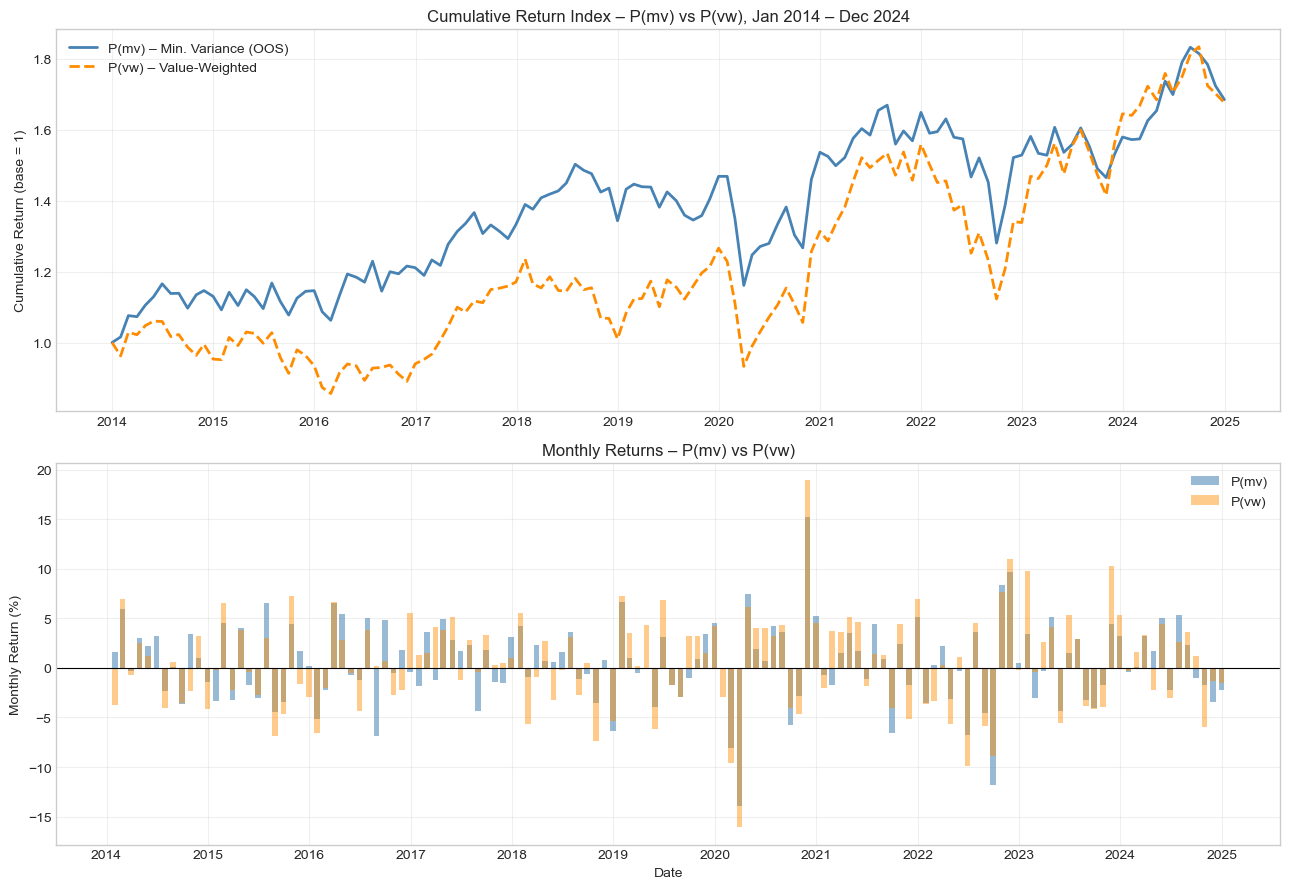

In [31]:
#  Cumulative Return Index + Monthly Returns 

def cum_index(r, base=1.0):
    r = r.dropna()
    ci = (1 + r).cumprod() * base
    t0 = r.index[0] - pd.DateOffset(months=1)
    return pd.concat([pd.Series([base], index=[t0]), ci])

cum_mv = cum_index(ret_mv)
cum_vw = cum_index(ret_vw_oos)

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Panel A: cumulative return
ax = axes[0]
ax.plot(cum_mv.index, cum_mv.values, color='steelblue', lw=2, label='P(mv) – Min. Variance (OOS)')
ax.plot(cum_vw.index, cum_vw.values, color='darkorange', lw=2, ls='--', label='P(vw) – Value-Weighted')
ax.set_ylabel('Cumulative Return (base = 1)')
ax.set_title('Cumulative Return Index – P(mv) vs P(vw), Jan 2014 – Dec 2024')
ax.legend()
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Panel B: monthly returns
ax2 = axes[1]
ax2.bar(ret_mv.dropna().index, ret_mv.dropna() * 100, width=20, color='steelblue', alpha=0.55, label='P(mv)')
ax2.bar(ret_vw_oos.dropna().index, ret_vw_oos.dropna() * 100, width=20, color='darkorange', alpha=0.45, label='P(vw)')
ax2.axhline(0, color='black', lw=0.8)
ax2.set_ylabel('Monthly Return (%)')
ax2.set_xlabel('Date')
ax2.set_title('Monthly Returns – P(mv) vs P(vw)')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()

In [32]:
#  Portfolio Composition Over Time 

comp_rows = []
for yr in OOS_YEARS:
    w = weights_mv[yr]
    comp_rows.append({
        'Year': yr,
        'Total Firms': len(w),
        'Non-Zero Holdings': int((w > 1e-4).sum()),
        'Max Weight (%)': round(w.max() * 100, 2),
        'Top-5 Weight (%)': round(w.nlargest(5).sum() * 100, 2),
        'Top-10 Weight (%)': round(w.nlargest(10).sum() * 100, 2),
    })

comp_table = pd.DataFrame(comp_rows).set_index('Year')
print("MVP Portfolio Composition")
print("=" * 70)
print(comp_table.to_string())

MVP Portfolio Composition
      Total Firms  Non-Zero Holdings  Max Weight (%)  Top-5 Weight (%)  Top-10 Weight (%)
Year                                                                                     
2014          405                 21           18.27             59.36              85.30
2015          426                 22           16.38             58.14              83.93
2016          449                 23           16.66             57.83              79.33
2017          467                 18           21.97             71.70              88.37
2018          484                 21           20.94             62.47              83.14
2019          512                 23           16.59             53.13              80.03
2020          557                 27           11.27             43.81              71.01
2021          577                 28           17.34             54.65              73.19
2022          587                 33           12.53             42.56    

Year-by-Year Performance
      P(mv) Return (%)  P(vw) Return (%)  Outperformance (%)
Year                                                        
2014             13.03             -4.67               17.70
2015              1.43             -1.95                3.38
2016              5.65              0.56                5.09
2017             10.06             24.56              -14.51
2018              0.79            -13.71               14.50
2019              9.33             25.32              -15.99
2020              4.62              3.76                0.86
2021              7.32             18.67              -11.34
2022             -7.30            -14.14                6.84
2023              3.33             22.93              -19.59
2024              6.68              1.89                4.80

P(mv) outperformed P(vw) in 7/11 years.


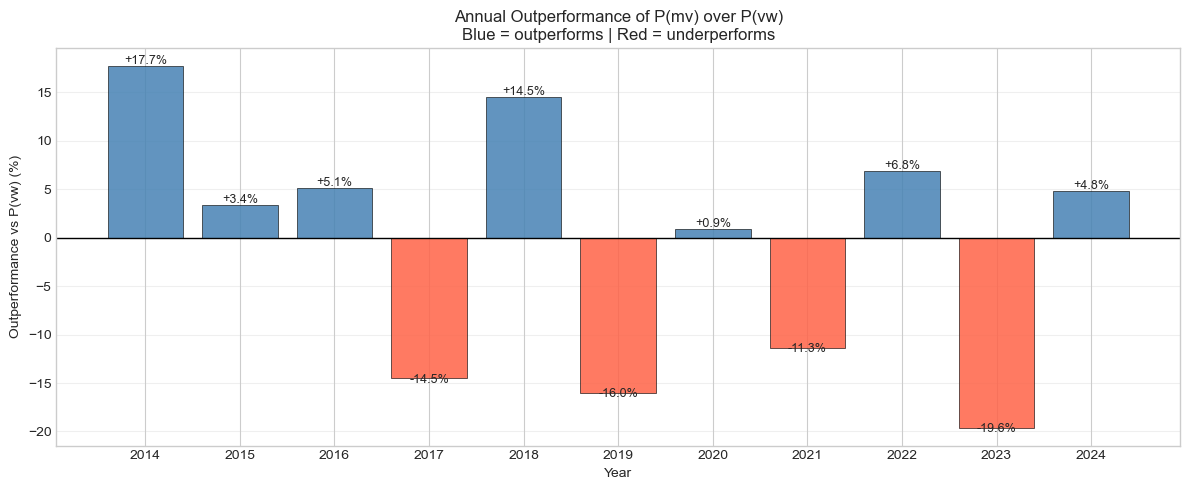

In [33]:
#  Year-by-Year Performance + Outperformance Chart 

annual_rows = []
for yr in OOS_YEARS:
    r_mv_y = oos_returns_mv[yr].dropna()
    r_vw_y = oos_returns_vw[yr].dropna()
    ret_mv_y = ((1 + r_mv_y).prod() - 1) * 100
    ret_vw_y = ((1 + r_vw_y).prod() - 1) * 100
    annual_rows.append({
        'Year': yr,
        'P(mv) Return (%)': round(ret_mv_y, 2),
        'P(vw) Return (%)': round(ret_vw_y, 2),
        'Outperformance (%)': round(ret_mv_y - ret_vw_y, 2),
    })

annual_table = pd.DataFrame(annual_rows).set_index('Year')
print("Year-by-Year Performance")
print("=" * 55)
print(annual_table.to_string())
n_out = (annual_table['Outperformance (%)'] > 0).sum()
print(f'\nP(mv) outperformed P(vw) in {n_out}/{len(OOS_YEARS)} years.')

#  Outperformance bar chart 
fig, ax = plt.subplots(figsize=(12, 5))

colors = ['steelblue' if v >= 0 else 'tomato' for v in annual_table['Outperformance (%)']]
ax.bar(annual_table.index, annual_table['Outperformance (%)'],
       color=colors, alpha=0.85, edgecolor='black', lw=0.5)
ax.axhline(0, color='black', lw=1.0)

for yr, val in zip(annual_table.index, annual_table['Outperformance (%)']):
    offset = 0.2 if val >= 0 else -0.5
    ax.text(yr, val + offset, f'{val:+.1f}%', ha='center', fontsize=9)

ax.set_xticks(annual_table.index)
ax.set_xlabel('Year')
ax.set_ylabel('Outperformance vs P(vw) (%)')
ax.set_title('Annual Outperformance of P(mv) over P(vw)\nBlue = outperforms | Red = underperforms')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


# Part II — Carbon-Aware Allocation

# 3 — Carbon Data: Revenue & Carbon Intensity

This section loads the revenue data required for the subsequent computations. It calculates the carbon intensity and applies the forward filling for missing values.





In [34]:
#  Load New Revenue Data 


# Load the revenue data
revenue_annual = pd.read_excel(DATA_URLS['revenue'], index_col=0)
revenue_annual = revenue_annual.reset_index(drop=True).set_index('ISIN')

# Keep only the integer columns (years) and ensure they are numeric
revenue_annual = revenue_annual[[c for c in revenue_annual.columns if isinstance(c, int)]]
revenue_annual = revenue_annual.apply(pd.to_numeric, errors='coerce')

print(f"Revenue (annual):{revenue_annual.shape[0]:>5} firms")

Revenue (annual): 2609 firms


In [35]:
# Calculate Carbon Intensity

# 1a. Identify only the integer year columns
year_cols = [c for c in scope1_eur.columns if isinstance(c, int)]

# 1b. Convert values to numbers
scope1_numeric = scope1_eur[year_cols].apply(pd.to_numeric, errors='coerce')
scope2_numeric = scope2_eur[year_cols].apply(pd.to_numeric, errors='coerce')

# 2. Total Emissions: Scope 1 + Scope 2 for European firms
# NOTE: we use fill_value=np.nan so that firm-years with only one scope
# report NaN rather than a partial total, consistent with the point-in-time
# eligibility filter that requires both scopes.
# In practice most firms that pass the eligibility filter have both scopes,
# so the impact is small, but it avoids silently understating emissions.
total_emissions_eur = scope1_numeric + scope2_numeric  # NaN if either scope missing

# 3. Align the Revenue data to match the European firm universe
revenue_eur = revenue_annual[revenue_annual.index.isin(total_emissions_eur.index)]
revenue_numeric = revenue_eur[year_cols].apply(pd.to_numeric, errors='coerce')
revenue_numeric = revenue_numeric / 1000  # thousands USD -> millions USD

# 4. Carbon Intensity = Emissions (tonnes) / Revenue (millions USD)
carbon_intensity_raw = total_emissions_eur.divide(revenue_numeric)

# Clean up infinite values (firms with zero revenue)
carbon_intensity_raw = carbon_intensity_raw.replace([np.inf, -np.inf], np.nan)

# 5. Forward fill: carry last available year forward when data is missing
# axis=1 fills along the year axis (left to right), preserving point-in-time ordering
carbon_intensity = carbon_intensity_raw.ffill(axis=1)

display(carbon_intensity.head())
display(carbon_intensity.shape)


,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
ISIN,,,,,,,,,,,,,,,,,,,,,,,,,,,
AT000000STR1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62.697736,76.786916,71.598535,71.077442,67.586974,77.588455,73.861010,82.949355,64.572322,57.926584,52.720501,52.842025,57.193533,53.890387,49.603036,49.603036
AT00000VIE62,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,81.386743,82.019750,67.612048,55.023591,33.655230,23.729432,59.089244,16.457334,35.270336,9.785265,9.785265
AT0000606306,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.375764,0.224023,3.715011,3.612025,2.745632,3.912901,4.178306,4.711440,7.004624,6.619508,6.215898,5.281778,5.006534,3.281733,1.935013,1.935013
AT0000652011,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.409959,0.360049,11.275763,8.003892,6.965420,7.117224,7.465940,7.565774,8.082101,5.862954,5.803272,5.153404,3.960265,3.591910,3.993769,2.379728,2.379728
AT0000720008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.8625,16.471554,12.939949,9.386965,13.168551,37.203132,37.558389,30.206199,44.709572,68.975943,70.624873,48.617975,55.166477,62.883132,55.194910,55.237263,47.521498,50.943688,50.943688


(633, 27)

# 4 — Carbon Emission Evaluation



## 4.1 Carbon Metrics of the Baseline Portfolios

We evaluate the carbon profile of our baseline investment strategies (Minimum Variance and Value-Weighted) over the out-of-sample period (2014-2024):

1. Define Metric Formulas: Create a generalized function to calculate Weighted Average Carbon Intensity (WACI) and Carbon Footprint (CF), automatically applying a one-year data lag to prevent look-ahead bias.

2. Explicit Budget Demonstration: Validate the calculation methodology for the 2014 investment year by mapping exact dollar allocations using a 1 million USD budget, ensuring the explicit financed emissions math aligns with simplified weight-based formulas.

3. Calculate MVP Carbon Metrics: Loop through the 2014-2024 period to compute and store the annual WACI and CF for the out-of-sample Minimum Variance Portfolio (P_mv).

4. Calculate Benchmark Metrics: Compute the exact same annual carbon metrics for the Value-Weighted benchmark (P_vw) utilizing the matching investment set to establish a market-cap-weighted environmental baseline.

5. Plot Metric Evolution: Generate comparative time-series plots to visually analyze the historical trajectories of both WACI and CF between the active and passive strategies.

6. Compare Aggregate Statistics: Calculate the average and median WACI and CF over the entire sample period for both portfolios to quantify the total environmental gap between the two baseline strategies.

In [36]:
#  Define the Carbon Metrics Function 

def compute_carbon_metrics(weights, investment_year, carbon_intensity, total_emissions, mv_annual):
    # 1. Apply the Point-in-Time Lag (Information from end of year Y-1)
    data_year = investment_year - 1

    # 2. Isolate the data for that specific historical year
    ci_series = carbon_intensity[data_year]
    emissions_series = total_emissions[data_year]
    cap_series = mv_annual[data_year]

    # 3. Align the data precisely to the firms held in the portfolio
    ci_portfolio = ci_series.loc[weights.index]
    emissions_portfolio = emissions_series.loc[weights.index]
    cap_portfolio = cap_series.loc[weights.index]

    # 4. Calculate Weighted Average Carbon Intensity (WACI)
    waci = (weights * ci_portfolio).sum()

    # 5. Calculate Carbon Footprint (CF)
    # Note: emissions_portfolio is in tonnes, cap_portfolio is in millions USD
    carbon_footprint = (weights * (emissions_portfolio / cap_portfolio)).sum()

    return waci, carbon_footprint

In [37]:
#  Calculating CF and WACI over time for the Minimum Variance Portfolio with an Explicit $1 Million Budget 

# 1. Define the budget
V_Y_millions = 1.0

# 2. Extract data for a specific year
target_year = 2014
data_year = target_year - 1

current_weights = weights_mv[target_year]
emissions_portfolio = total_emissions_eur[data_year].loc[current_weights.index]
cap_portfolio = mv_annual[data_year].loc[current_weights.index]
ci_portfolio = carbon_intensity[data_year].loc[current_weights.index]

# THE EXPLICIT METHOD (Using Budget)
# Step A: Calculate dollar value invested in each firm ( V_{i,Y} = α_{i,Y} * V_Y )
V_i_Y = current_weights * V_Y_millions

# Carbon Footprint (CF) Explicit
# Step B: Calculate ownership share ( o_{i,Y} = V_{i,Y} / Cap_{i,Y} )
ownership_share = V_i_Y / cap_portfolio

# Step C: Calculate the absolute tonnes of CO2 you finance ( o_{i,Y} * E_{i,Y} )
financed_emissions = ownership_share * emissions_portfolio

# Step D: Calculate Portfolio Carbon Footprint
cf_explicit = financed_emissions.sum() / V_Y_millions

# WACI Explicit
# Calculate the effective weight by taking dollar allocation / total budget
# Then multiply by the firm's carbon intensity
waci_explicit = ((V_i_Y / V_Y_millions) * ci_portfolio).sum()


# THE SIMPLIFIED METHOD (Using Weights)
cf_simplified = (current_weights * (emissions_portfolio / cap_portfolio)).sum()
waci_simplified = (current_weights * ci_portfolio).sum()

print(f"--- Comparison for Year {target_year} ---")
print(f"Total Budget Used:    ${V_Y_millions} Million\n")

print("--- Carbon Footprint (CF) ---")
print(f"Explicit Formula CF:  {cf_explicit:.6f} tCO2e / $1M Invested")
print(f"Simplified Math CF:   {cf_simplified:.6f} tCO2e / $1M Invested")
print(f"Difference:           {cf_explicit - cf_simplified:.10f}\n")

print("--- Weighted Average Carbon Intensity (WACI) ---")
print(f"Explicit Formula WACI: {waci_explicit:.6f} tCO2e / $1M Revenue")
print(f"Simplified Math WACI:  {waci_simplified:.6f} tCO2e / $1M Revenue")
print(f"Difference:            {waci_explicit - waci_simplified:.10f}")

--- Comparison for Year 2014 ---
Total Budget Used:    $1.0 Million

--- Carbon Footprint (CF) ---
Explicit Formula CF:  24.986944 tCO2e / $1M Invested
Simplified Math CF:   24.986944 tCO2e / $1M Invested
Difference:           -0.0000000000

--- Weighted Average Carbon Intensity (WACI) ---
Explicit Formula WACI: 55.626362 tCO2e / $1M Revenue
Simplified Math WACI:  55.626362 tCO2e / $1M Revenue
Difference:            0.0000000000


In [38]:
#  Calculate WACI and CF over time for the Minimum Variance Portfolio 

# Create dictionaries to store the results over time
waci_history_mv = {}
cf_history_mv = {}

print(f"{'Year':<6} | {'WACI':<12} | {'Carbon Footprint'}")

# Loop through the Out-of-Sample years
for oos_year in OOS_YEARS:
    # Compute the metrics using the weights generated for this specific year
    waci, cf = compute_carbon_metrics(
        weights=weights_mv[oos_year],
        investment_year=oos_year,
        carbon_intensity=carbon_intensity,
        total_emissions=total_emissions_eur,
        mv_annual=mv_annual
    )

    # Store the results
    waci_history_mv[oos_year] = waci
    cf_history_mv[oos_year] = cf

    # Print the annual results formatted to 2 decimal places
    print(f"{oos_year:<6} | {waci:<12.2f} | {cf:.2f}")

Year   | WACI         | Carbon Footprint
2014   | 55.63        | 24.99
2015   | 362.73       | 2449.06
2016   | 315.28       | 857.03
2017   | 122.58       | 518.21
2018   | 160.44       | 204.04
2019   | 94.05        | 105.64
2020   | 73.57        | 36.39
2021   | 144.63       | 55.11
2022   | 136.35       | 38.12
2023   | 51.48        | 43.66
2024   | 36.32        | 55.72


In [39]:
#  Temporal Evolution of WACI and CF for Value-Weighted Portfolio P(vw) 

waci_history_vw = {}
cf_history_vw = {}

print(f"{'Year':<6} | {'WACI_VW (tCO2e / $1M Rev)':<28} | {'CF_VW (tCO2e / $1M Invested)'}")
print("-" * 65)

for oos_year in OOS_YEARS:
    data_year = oos_year - 1

    # 1. Ensure the investment set matches the P(mv) universe for this specific year
    eligible_isins = weights_mv[oos_year].index

    # 2. Extract the data for these specific firms
    cap_portfolio = mv_annual[data_year].loc[eligible_isins]
    emissions_portfolio = total_emissions_eur[data_year].loc[eligible_isins]
    ci_portfolio = carbon_intensity[data_year].loc[eligible_isins]

    # 3. Calculate the Value-Weights (w_{i,Y} = Cap_{i,Y} / Cap_Y)
    total_cap = cap_portfolio.sum()
    vw_weights = cap_portfolio / total_cap

    # 4. Calculate WACI (Sum of wi,Y * CIi,Y)
    waci_vw = (vw_weights * ci_portfolio).sum()

    # 5. Calculate CF using the simplified formula:
    # CF(vw)_Y = Sum ((1 / Cap_Y) * E_{i,Y})
    cf_vw = emissions_portfolio.sum() / total_cap

    # Store the results
    waci_history_vw[oos_year] = waci_vw
    cf_history_vw[oos_year] = cf_vw

    # Print the evolution year by year
    print(f"{oos_year:<6} | {waci_vw:<28.2f} | {cf_vw:.2f}")

# Optional: Combine both MV and VW histories into a single DataFrame for easy comparison
evolution_comparison_df = pd.DataFrame({
    'WACI_MV': waci_history_mv,
    'WACI_VW': waci_history_vw,
    'CF_MV': cf_history_mv,
    'CF_VW': cf_history_vw
})

print("\nEvolution comparison DataFrame created: `evolution_comparison_df`")

Year   | WACI_VW (tCO2e / $1M Rev)    | CF_VW (tCO2e / $1M Invested)
-----------------------------------------------------------------
2014   | 134.17                       | 204.71
2015   | 127.65                       | 185.41
2016   | 158.82                       | 195.27
2017   | 153.91                       | 209.38
2018   | 185.02                       | 200.88
2019   | 141.29                       | 151.53
2020   | 141.43                       | 155.30
2021   | 133.39                       | 125.52
2022   | 133.62                       | 117.13
2023   | 103.81                       | 95.05
2024   | 79.04                        | 92.11

Evolution comparison DataFrame created: `evolution_comparison_df`


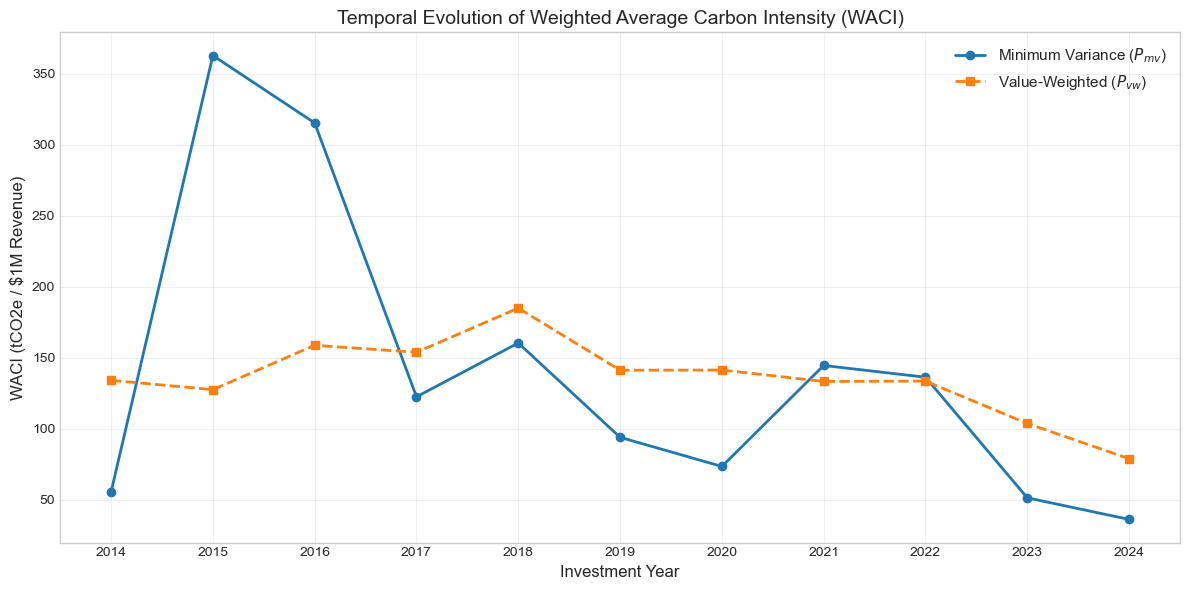

In [40]:
# Ensure the index (years) is treated as an integer for clean x-axis formatting
years = evolution_comparison_df.index

# Plot WACI (Weighted Average Carbon Intensity)
plt.figure(figsize=(12, 6))
plt.plot(years, evolution_comparison_df['WACI_MV'], marker='o', label='Minimum Variance ($P_{mv}$)', color='tab:blue', linewidth=2)
plt.plot(years, evolution_comparison_df['WACI_VW'], marker='s', label='Value-Weighted ($P_{vw}$)', color='tab:orange', linewidth=2, linestyle='--')

plt.title('Temporal Evolution of Weighted Average Carbon Intensity (WACI)', fontsize=14)
plt.xlabel('Investment Year', fontsize=12)
plt.ylabel('WACI (tCO2e / $1M Revenue)', fontsize=12)
plt.xticks(years) # Force all years to show
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [41]:
#  Calculate and Compare Average & Median WACI 

avg_waci_mv = evolution_comparison_df['WACI_MV'].mean()
avg_waci_vw = evolution_comparison_df['WACI_VW'].mean()
med_waci_mv = evolution_comparison_df['WACI_MV'].median()
med_waci_vw = evolution_comparison_df['WACI_VW'].median()

waci_diff_mean_pct = ((avg_waci_mv - avg_waci_vw) / avg_waci_vw) * 100
waci_diff_med_pct = ((med_waci_mv - med_waci_vw) / med_waci_vw) * 100

print("=== WACI Summary (2014-2024) ===")
print(f"Minimum Variance (P_mv) | Mean: {avg_waci_mv:.2f} | Median: {med_waci_mv:.2f} tCO2e / $1M Rev")
print(f"Value-Weighted (P_vw)   | Mean: {avg_waci_vw:.2f} | Median: {med_waci_vw:.2f} tCO2e / $1M Rev")
print("-" * 65)
print(f"Mean Difference:   P_mv is {abs(waci_diff_mean_pct):.1f}% {'higher' if avg_waci_mv > avg_waci_vw else 'lower'} than P_vw")
print(f"Median Difference: P_mv is {abs(waci_diff_med_pct):.1f}% {'higher' if med_waci_mv > med_waci_vw else 'lower'} than P_vw\n")

=== WACI Summary (2014-2024) ===
Minimum Variance (P_mv) | Mean: 141.19 | Median: 122.58 tCO2e / $1M Rev
Value-Weighted (P_vw)   | Mean: 135.65 | Median: 134.17 tCO2e / $1M Rev
-----------------------------------------------------------------
Mean Difference:   P_mv is 4.1% higher than P_vw
Median Difference: P_mv is 8.6% lower than P_vw



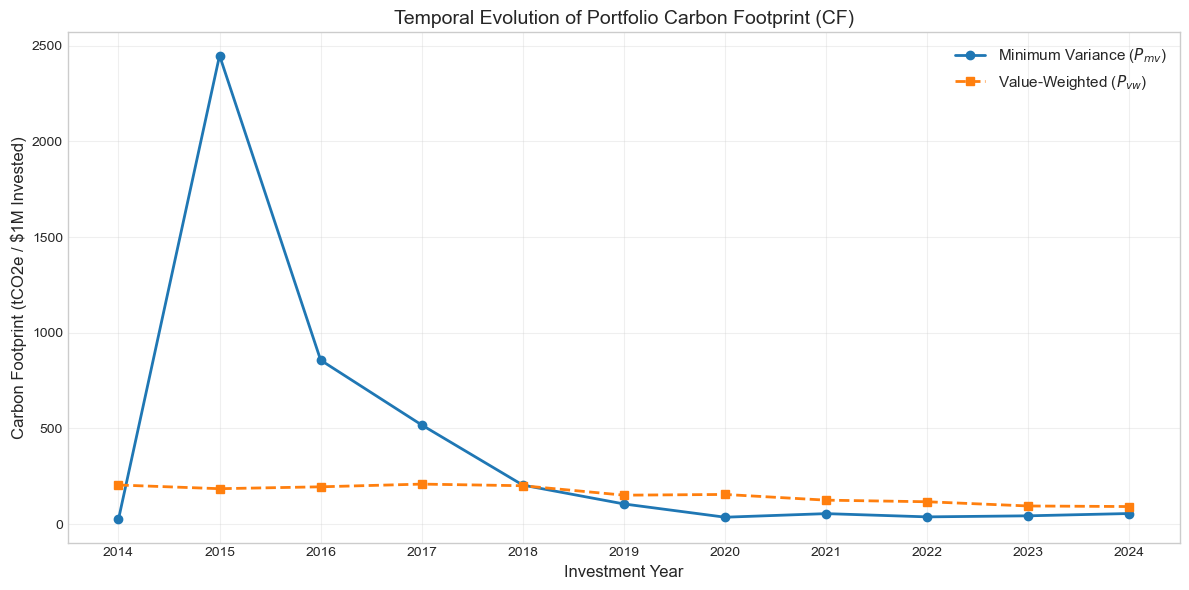

In [42]:
# Plot CF (Carbon Footprint)
plt.figure(figsize=(12, 6))
plt.plot(years, evolution_comparison_df['CF_MV'], marker='o', label='Minimum Variance ($P_{mv}$)', color='tab:blue', linewidth=2)
plt.plot(years, evolution_comparison_df['CF_VW'], marker='s', label='Value-Weighted ($P_{vw}$)', color='tab:orange', linewidth=2, linestyle='--')

plt.title('Temporal Evolution of Portfolio Carbon Footprint (CF)', fontsize=14)
plt.xlabel('Investment Year', fontsize=12)
plt.ylabel('Carbon Footprint (tCO2e / $1M Invested)', fontsize=12)
plt.xticks(years)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
#  Calculate and Compare Average & Median CF 

avg_cf_mv = evolution_comparison_df['CF_MV'].mean()
avg_cf_vw = evolution_comparison_df['CF_VW'].mean()
med_cf_mv = evolution_comparison_df['CF_MV'].median()
med_cf_vw = evolution_comparison_df['CF_VW'].median()

cf_diff_mean_pct = ((avg_cf_mv - avg_cf_vw) / avg_cf_vw) * 100
cf_diff_med_pct = ((med_cf_mv - med_cf_vw) / med_cf_vw) * 100

print("=== Carbon Footprint Summary (2014-2024) ===")
print(f"Minimum Variance (P_mv) | Mean: {avg_cf_mv:.2f} | Median: {med_cf_mv:.2f} tCO2e / $1M Inv")
print(f"Value-Weighted (P_vw)   | Mean: {avg_cf_vw:.2f} | Median: {med_cf_vw:.2f} tCO2e / $1M Inv")
print("-" * 65)
print(f"Mean Difference:   P_mv is {abs(cf_diff_mean_pct):.1f}% {'higher' if avg_cf_mv > avg_cf_vw else 'lower'} than P_vw")
print(f"Median Difference: P_mv is {abs(cf_diff_med_pct):.1f}% {'higher' if med_cf_mv > med_cf_vw else 'lower'} than P_vw")

=== Carbon Footprint Summary (2014-2024) ===
Minimum Variance (P_mv) | Mean: 398.90 | Median: 55.72 tCO2e / $1M Inv
Value-Weighted (P_vw)   | Mean: 157.48 | Median: 155.30 tCO2e / $1M Inv
-----------------------------------------------------------------
Mean Difference:   P_mv is 153.3% higher than P_vw
Median Difference: P_mv is 64.1% lower than P_vw


## 4.2 Top 10 WACI contributors and CF spike diagnostic

The assignment requires identifying the firms that drive carbon intensity up. We report the top 10 individual WACI contributions (αᵢ × CIᵢ) for the peak year and for the most recent year, and separately identify the firm responsible for the 2015 carbon footprint spike.

In [44]:
# Top 10 WACI Contributors with Carbon Return Efficiency

def top10_waci_contributors(oos_year, weights_dict, carbon_intensity_df,
                             firm_info_df, returns_mat, rf_series, n=10):
    """
    Returns the top-n firms by WACI contribution (alpha_i x CI_i) plus:
      Carbon Return Efficiency = (R_i - Rf) / CI_i  x 1000
    expressed as percentage excess return per 1000 tCO2e per million USD revenue.
    Positive: the portfolio earns excess return per unit of CI financed.
    Negative: the firm destroys return while emitting heavily.
    """
    data_year = oos_year - 1
    w  = weights_dict[oos_year]
    ci = carbon_intensity_df[data_year].reindex(w.index)
    contrib = (w * ci).dropna().sort_values(ascending=False)

    # Annualized firm return for this investment year
    year_cols = [d for d in returns_mat.columns
                 if hasattr(d, 'year') and d.year == oos_year]
    if year_cols:
        r_annual = returns_mat[year_cols].apply(
            lambda row: (1 + row.dropna()).prod() - 1, axis=1
        ).reindex(w.index)
    else:
        r_annual = pd.Series(np.nan, index=w.index)

    rf_year = rf_series[rf_series.index.year == oos_year].mean() * 12

    df = pd.DataFrame({
        'ISIN':                contrib.index,
        'Weight (%)':          w.reindex(contrib.index).values * 100,
        'CI':                  ci.reindex(contrib.index).values,
        'WACI contrib':        contrib.values,
        'Ann. Return (%)':     r_annual.reindex(contrib.index).values * 100,
    })

    df['Carbon Return Efficiency'] = (
        (df['Ann. Return (%)'] / 100 - rf_year) / df['CI']
    ) * 1000

    if firm_info_df is not None:
        df = df.merge(
            firm_info_df[['NAME']].reset_index().rename(columns={'index': 'ISIN'}),
            on='ISIN', how='left'
        )

    df = df.round({
        'Weight (%)': 3, 'CI': 1, 'WACI contrib': 2,
        'Ann. Return (%)': 2, 'Carbon Return Efficiency': 4
    })
    return df.head(n)


# Returns matrix for firm-level annual return lookup
returns_matrix = ri_indexed[
    [d for d in period_dates if d.year <= 2024]
].pct_change(axis=1)

# Peak WACI year for P(mv)
peak_year = max(waci_history_mv, key=lambda y: waci_history_mv[y])
print(f'Peak WACI year for P(mv): {peak_year}  '
      f'(WACI = {waci_history_mv[peak_year]:.1f} tCO2e/$1M rev)\n')

top10_peak = top10_waci_contributors(
    peak_year, weights_mv, carbon_intensity, firm_info, returns_matrix, rf_monthly
)
top10_2024 = top10_waci_contributors(
    2024, weights_mv, carbon_intensity, firm_info, returns_matrix, rf_monthly
)

print(f'Top 10 WACI contributors: {peak_year} (peak year)')
display(top10_peak)
print(f'\nTop 10 WACI contributors: 2024 (final year)')
display(top10_2024)


Peak WACI year for P(mv): 2015  (WACI = 362.7 tCO2e/$1M rev)

Top 10 WACI contributors: 2015 (peak year)


,ISIN,Weight (%),CI,WACI contrib,Ann. Return (%),Carbon Return Efficiency,NAME
0,GB00B71N6K86,10.541,3129.2,329.86,-55.19,-0.1764,EVRAZ SUSP - SUSP.06/12/23
1,US8816242098,15.691,49.4,7.75,17.00,3.4386,TEVA PHARMACEUTICAL INDUSTRIES ADR 1:1
2,NO0003054108,16.382,32.9,5.38,3.70,1.1240,MOWI
3,GB00BRB37M78,7.403,52.1,3.85,27.66,5.3102,DIGNITY DEAD - DELIST.25/05/23
4,GB00B3DGH821,3.530,102.5,3.62,-15.43,-1.5063,DE LA RUE ORD DEAD - DELIST.03/07/25
5,GB00BDR05C01,0.973,318.5,3.10,1.25,0.0391,NATIONAL GRID
6,IE00BGH1M568,6.131,50.5,3.10,-13.18,-2.6104,PERRIGO
7,DK0060448595,8.126,18.6,1.51,-1.58,-0.8555,COLOPLAST B
8,GB00B0WMWD03,2.655,32.5,0.86,39.74,12.2154,QINETIQ GROUP
9,GB0002670437,0.197,358.4,0.71,-7.39,-0.2065,DEVRO DEAD - DELIST.14/04/23



Top 10 WACI contributors: 2024 (final year)


,ISIN,Weight (%),CI,WACI contrib,Ann. Return (%),Carbon Return Efficiency,NAME
0,GB0001667087,2.309,537.3,12.41,0.78,-0.0809,CAMELLIA
1,ES0112501012,11.029,78.8,8.69,-0.76,-0.7477,EBRO FOODS
2,DE0007042301,11.748,48.8,5.73,29.36,4.9651,RHOEN-KLINIKUM
3,IL0002300114,5.426,50.7,2.75,10.40,1.0389,BEZEQ ISRAELI TELECOMMUNICATION
4,BE0974256852,10.257,10.5,1.08,-14.85,-18.9644,COLRUYT GROUP
5,NL0009432491,0.298,289.6,0.86,36.17,1.0718,KONINKLIJKE VOPAK
6,CH0012032048,14.136,4.9,0.69,1.06,-8.3599,ROCHE HOLDING
7,IL0010811243,2.244,27.2,0.61,22.68,6.4593,ELBIT SYSTEMS
8,DE0005200000,3.997,13.3,0.53,-13.43,-13.9652,BEIERSDORF
9,GB0002634946,3.778,13.4,0.51,4.04,-0.8085,BAE SYSTEMS


In [45]:
#  CF Spike Diagnostic: identify the culprit firm for the 2015 spike 

def cf_contributors(oos_year, weights_dict, total_emissions, mv_annual_df,
                    firm_info_df, n=10):
    """
    Returns top-n firms by CF contribution (αᵢ × Eᵢ/Capᵢ) for a given year.
    """
    data_year = oos_year - 1
    w = weights_dict[oos_year]

    em = total_emissions_eur[data_year].reindex(w.index)
    cap = mv_annual_df.loc[
        ~mv_annual_df.index.duplicated(keep='first'), data_year
    ].reindex(w.index)
    cap = cap.replace(0, np.nan)

    contrib = (w * em / cap).dropna().sort_values(ascending=False)

    df = pd.DataFrame({
        'ISIN':          contrib.index,
        'CF contrib':    contrib.values,
        'Weight (%)':    w.reindex(contrib.index).values * 100,
        'Emissions (Mt)': em.reindex(contrib.index).values / 1e6,
        'Mkt Cap ($M)':  cap.reindex(contrib.index).values,
    })
    if firm_info_df is not None:
        df = df.merge(
            firm_info_df[['NAME']].reset_index().rename(columns={'index': 'ISIN'}),
            on='ISIN', how='left'
        )
    df = df.round({'CF contrib': 2, 'Weight (%)': 3,
                   'Emissions (Mt)': 4, 'Mkt Cap ($M)': 1})
    return df.head(n)

cf_peak_year = max(cf_history_mv, key=lambda y: cf_history_mv[y])
print(f'Peak CF year for P(mv): {cf_peak_year}  '
      f'(CF = {cf_history_mv[cf_peak_year]:.1f} tCO2e/$1M inv)\n')

top10_cf_peak = cf_contributors(
    cf_peak_year, weights_mv, total_emissions_eur, mv_annual, firm_info
)
print(f'Top 10 CF contributors: {cf_peak_year} (spike year):')
print('These firms explain the ~2,500 tCO2e/$1M invested spike.')
display(top10_cf_peak)

Peak CF year for P(mv): 2015  (CF = 2449.1 tCO2e/$1M inv)

Top 10 CF contributors: 2015 (spike year):
These firms explain the ~2,500 tCO2e/$1M invested spike.


,ISIN,CF contrib,Weight (%),Emissions (Mt),Mkt Cap ($M),NAME
0,GB00B71N6K86,2433.91,10.541,47.0100,2036.0,EVRAZ SUSP - SUSP.06/12/23
1,US8816242098,3.78,15.691,1.0038,41691.8,TEVA PHARMACEUTICAL INDUSTRIES ADR 1:1
2,NO0003054108,3.43,16.382,0.1007,4814.1,MOWI
3,GB00B3DGH821,2.22,3.530,0.0791,1254.8,DE LA RUE ORD DEAD - DELIST.03/07/25
4,GB00BDR05C01,1.38,0.973,7.4700,52637.8,NATIONAL GRID
5,GB00BRB37M78,1.23,7.403,0.0218,1310.4,DIGNITY DEAD - DELIST.25/05/23
6,GB00B0WMWD03,0.73,2.655,0.0660,2385.0,QINETIQ GROUP
7,IE00BGH1M568,0.58,6.131,0.1920,20339.0,PERRIGO
8,GB0002670437,0.33,0.197,0.1420,844.4,DEVRO DEAD - DELIST.14/04/23
9,GB0032089863,0.23,2.173,0.1657,15673.0,NEXT


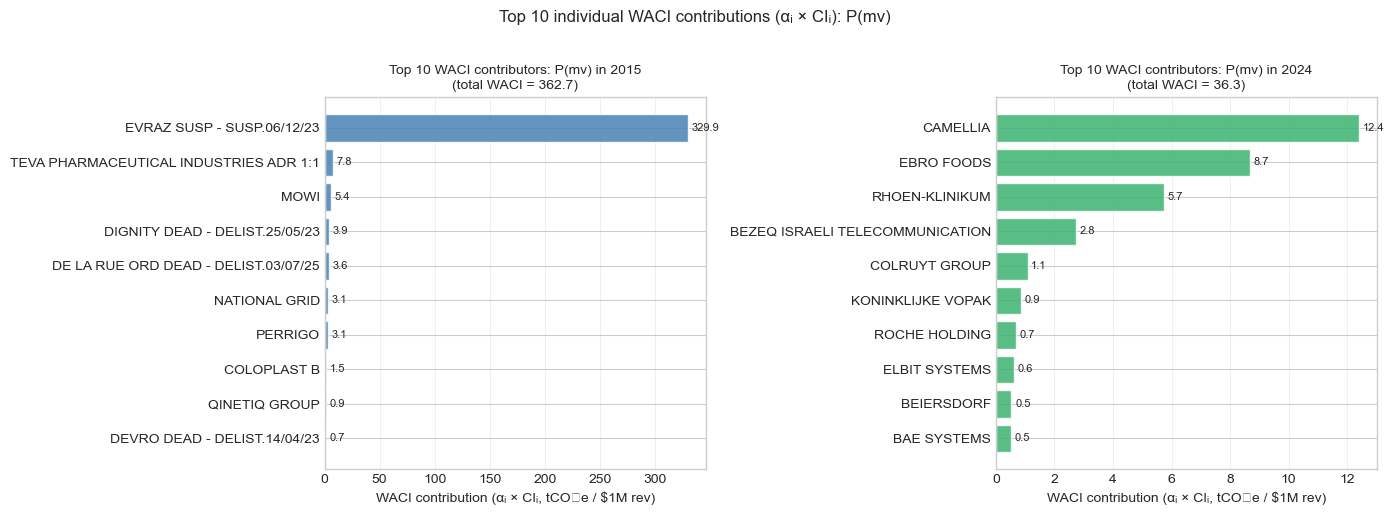

In [46]:
#  Figure: WACI contribution bar chart (peak year vs 2024) 

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, df, year, color in [
    (axes[0], top10_peak, peak_year,  'steelblue'),
    (axes[1], top10_2024, 2024,        'mediumseagreen'),
]:
    names = (
        df['NAME'].fillna(df['ISIN'])
        if 'NAME' in df.columns else df['ISIN']
    )
    bars = ax.barh(
        names, df['WACI contrib'],
        color=color, edgecolor='white', alpha=0.85
    )
    ax.set_xlabel('WACI contribution (αᵢ × CIᵢ, tCO₂e / $1M rev)', fontsize=10)
    ax.set_title(
        f'Top 10 WACI contributors: P(mv) in {year}\n'
        f'(total WACI = {waci_history_mv[year]:.1f})',
        fontsize=10
    )
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3, axis='x')
    for bar, val in zip(bars, df['WACI contrib']):
        ax.text(
            val + max(df['WACI contrib']) * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}', va='center', fontsize=8
        )

plt.suptitle(
    'Top 10 individual WACI contributions (αᵢ × CIᵢ): P(mv)',
    fontsize=12, y=1.02
)
plt.tight_layout()
plt.show()

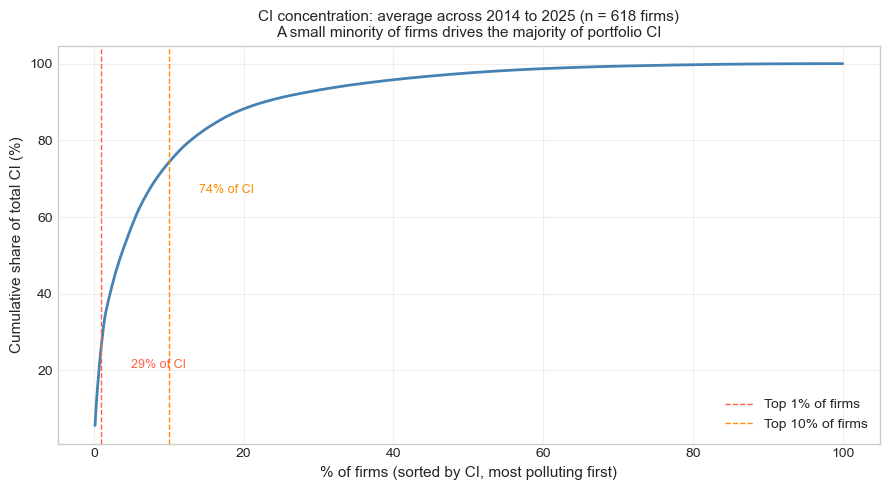

In [47]:
# Carbon Intensity concentration curve: average CI per firm across 2014 to 2025
# Shows the extreme right-skewness that makes small exclusions deliver large CF reductions

# Average CI per firm across all data years (2013 to 2024 data years)
data_years_ci = [y - 1 for y in range(2014, 2026)]
# Keep only columns that exist in carbon_intensity
data_years_ci = [y for y in data_years_ci if y in carbon_intensity.columns]
ci_avg = (
    carbon_intensity[data_years_ci]
    .mean(axis=1)
    .dropna()
)
ci_avg = ci_avg[ci_avg > 0]

# Lorenz-style cumulative share: sorted firms vs share of total CI
ci_sorted  = ci_avg.sort_values(ascending=False).reset_index(drop=True)
cum_share  = ci_sorted.cumsum() / ci_sorted.sum() * 100
pct_firms  = (ci_sorted.index + 1) / len(ci_sorted) * 100

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(pct_firms, cum_share, color='steelblue', lw=2)
ax.axvline(1,  color='tomato',     ls='--', lw=1, label='Top 1% of firms')
ax.axvline(10, color='darkorange', ls='--', lw=1, label='Top 10% of firms')

idx1  = int(len(ci_sorted) * 0.01)
idx10 = int(len(ci_sorted) * 0.10)
share1  = cum_share.iloc[idx1]
share10 = cum_share.iloc[idx10]

ax.annotate(
    f'{share1:.0f}% of CI',
    xy=(1, share1), xytext=(5, share1 - 8),
    fontsize=9, color='tomato'
)
ax.annotate(
    f'{share10:.0f}% of CI',
    xy=(10, share10), xytext=(14, share10 - 8),
    fontsize=9, color='darkorange'
)

ax.set_xlabel('% of firms (sorted by CI, most polluting first)', fontsize=11)
ax.set_ylabel('Cumulative share of total CI (%)', fontsize=11)
ax.set_title(
    f'CI concentration: average across 2014 to 2025 (n = {len(ci_sorted)} firms)\n'
    'A small minority of firms drives the majority of portfolio CI',
    fontsize=11
)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 4.3 Allocation with a 50% Reduction in Carbon Emissions

We construct a decarbonized long-only minimum variance portfolio out-of-sample over 2014–2024:

1.   Estimate Parameters: For each year Y, estimate μ^​ and Σ^ from the 120-month rolling window, reusing the baseline investment set and estimation logic.
2.   Solve Constrained Optimization: Solve the long-only MVP using the SLSQP algorithm, applying the strict environmental constraint that the portfolio carbon footprint must be CFY(p)​≤0.5×CFY(mv)​.
3.   Compute OOS Returns: Calculate 12 monthly out-of-sample returns for each year, accounting for intra-year weight drift (buy-and-hold) to accurately reflect portfolio characteristics.
4.   Financial Performance Analysis: Compare annualized financial summary statistics and plot the cumulative return series against the unconstrained Poos(mv)​ strategy.
5.   Carbon Metric Evolution: Calculate and plot the temporal evolution of both the Carbon Footprint (CF) and Weighted Average Carbon Intensity (WACI) for the new strategy.
6.   Portfolio Composition: Detail the main shifts in portfolio allocation by identifying specific firms or sectors that are over-weighted or excluded due to the decarbonization constraint.    

    

    

In [48]:
def solve_min_variance_carbon_oos(Sigma_monthly, isins, emissions_arr, caps_arr, target_cf):
    """
    Long-only minimum variance portfolio bounded by a maximum Carbon Footprint constraint.
    """
    N = len(isins)
    Sigma_ann = Sigma_monthly * 12

    # Objective: Minimize portfolio volatility
    def port_vol(w):
        return np.sqrt(w.T @ Sigma_ann @ w)

    # Calculate firm-level carbon to equity intensity (tCO2/$1M invested)
    # Handle missing caps (zeros) safely to prevent divide-by-zero errors
    caps_safe = np.where(caps_arr == 0, np.inf, caps_arr)
    cei = np.nan_to_num(emissions_arr / caps_safe, nan=np.inf)

    # Constraints: (1) Fully invested, (2) Carbon footprint <= target
    constraints = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
        {'type': 'ineq', 'fun': lambda w: target_cf - np.sum(w * cei)}
    ]

    # Bounds: Long-only (no short selling)
    bounds = tuple((0.0, 1.0) for _ in range(N))

    # Initial guess: Equal weights
    w_init = np.ones(N) / N

    result = minimize(
        port_vol, w_init, method='SLSQP',
        bounds=bounds, constraints=constraints,
        options={'ftol': 1e-6, 'maxiter': 1000, 'disp': False}
    )

    if not result.success:
        print("  WARNING: Optimizer did not converge. Returning initial guess.")
        w_opt = w_init
    else:
        w_opt = result.x

    w_opt = np.clip(w_opt, 0.0, None)
    w_opt /= w_opt.sum() # Ensure exact sum to 1

    return pd.Series(w_opt, index=isins)

In [49]:
oos_returns_mv_50 = {}
weights_mv_50 = {}

print(f"{'Year':<6} {'Target CF':<12} {'Achieved CF':<12} {'Ann. Return'}")
print("-" * 45)

for oos_year in OOS_YEARS:
    data_year = oos_year - 1

    # 1. Load historical estimations
    prices_est = load_investment_set_local(oos_year)
    returns_est = compute_returns_oos(prices_est)
    mu_oos, Sigma_oos = compute_mu_sigma_oos(returns_est)
    isins = returns_est.index.tolist()

    # 2. Extract Carbon and Market Cap data aligned to the current ISINs
    # FIX: Drop duplicate ISINs in the index before reindexing to avoid the ValueError
    emissions_clean = total_emissions_eur.loc[~total_emissions_eur.index.duplicated(keep='first'), data_year]
    caps_clean = mv_annual.loc[~mv_annual.index.duplicated(keep='first'), data_year]

    emissions_yr = emissions_clean.reindex(isins).fillna(0).values
    caps_yr = caps_clean.reindex(isins).fillna(np.inf).values

    # 3. Calculate Target CF (50% reduction from the baseline portfolio)
    target_cf = 0.5 * cf_history_mv[oos_year]

    # 4. Generate constrained optimal weights
    w = solve_min_variance_carbon_oos(Sigma_oos, isins, emissions_yr, caps_yr, target_cf)

    # 5. Compute OOS performance with intra-year weight drift
    oos_ret = compute_oos_returns_local(oos_year, w)

    # Store the results
    oos_returns_mv_50[oos_year] = oos_ret
    weights_mv_50[oos_year] = w

    # Verification printout
    achieved_cf = np.sum(w.values * np.nan_to_num(emissions_yr / np.where(caps_yr==0, np.inf, caps_yr), nan=0))
    ann = ((1 + oos_ret).prod() - 1) * 100
    print(f"{oos_year:<6} {target_cf:<12.2f} {achieved_cf:<12.2f} {ann:+.2f}%")

# Concatenate OOS returns into a single time series
ret_mv_50 = pd.concat([oos_returns_mv_50[y] for y in OOS_YEARS])
ret_mv_50.index = pd.to_datetime(ret_mv_50.index)

Year   Target CF    Achieved CF  Ann. Return
---------------------------------------------
2014   12.49        12.49        +17.61%
2015   1224.53      1224.53      +5.96%
2016   428.52       428.52       +0.23%
2017   259.10       259.10       +9.79%
2018   102.02       102.02       +0.40%
2019   52.82        52.82        +9.63%
2020   18.20        18.20        +3.28%
2021   27.55        27.55        +6.67%
2022   19.06        19.06        -6.95%
2023   21.83        21.83        +4.17%
2024   27.86        27.86        +6.63%


In [50]:
#  Calculation of WACI and CF for the 0.5 Portfolio 
waci_history_50 = {}
cf_history_50 = {}

for oos_year in OOS_YEARS:
    # Use the compute_carbon_metrics function you defined in Cell 53
    waci, cf = compute_carbon_metrics(
        weights=weights_mv_50[oos_year],
        investment_year=oos_year,
        carbon_intensity=carbon_intensity,
        total_emissions=total_emissions_eur,
        mv_annual=mv_annual
    )
    waci_history_50[oos_year] = waci
    cf_history_50[oos_year] = cf

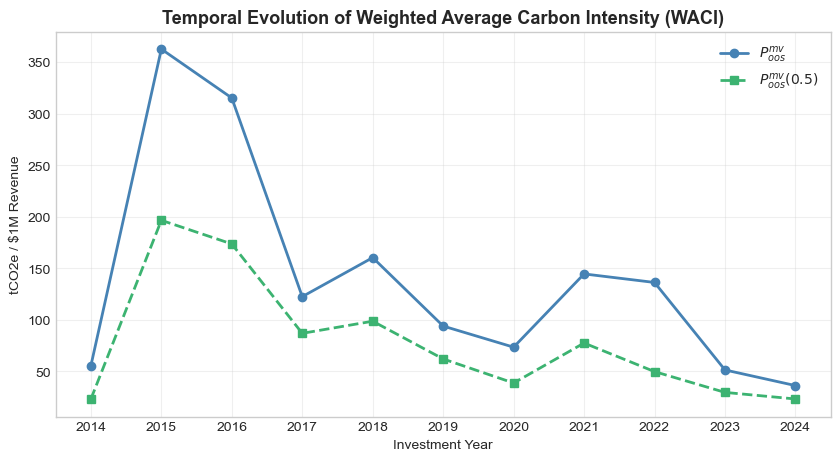

In [51]:
#  Plotting the Evolution of WACI 
years = list(OOS_YEARS)
waci_baseline = [waci_history_mv[y] for y in years]
waci_decarb = [waci_history_50[y] for y in years]

plt.figure(figsize=(10, 5))
plt.plot(years, waci_baseline, marker='o', label='$P_{oos}^{mv}$', color='steelblue', linewidth=2)
plt.plot(years, waci_decarb, marker='s', label='$P_{oos}^{mv}(0.5)$', color='mediumseagreen', linewidth=2, linestyle='--')

plt.title('Temporal Evolution of Weighted Average Carbon Intensity (WACI)', fontsize=13, fontweight='bold')
plt.xlabel('Investment Year')
plt.ylabel('tCO2e / $1M Revenue')
plt.xticks(years)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

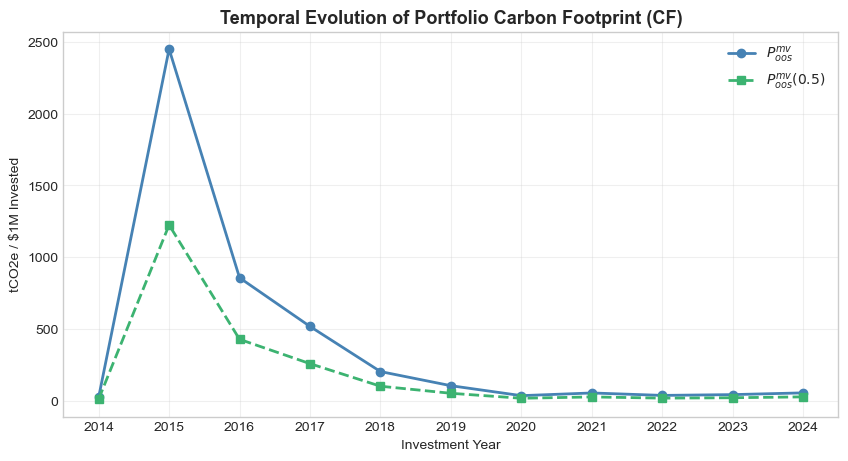

In [52]:
#  Plotting the Evolution of Carbon Footprint (CF) 
cf_baseline = [cf_history_mv[y] for y in years]
cf_decarb = [cf_history_50[y] for y in years]

plt.figure(figsize=(10, 5))
plt.plot(years, cf_baseline, marker='o', label='$P_{oos}^{mv}$', color='steelblue', linewidth=2)
plt.plot(years, cf_decarb, marker='s', label='$P_{oos}^{mv}(0.5)$', color='mediumseagreen', linewidth=2, linestyle='--')

plt.title('Temporal Evolution of Portfolio Carbon Footprint (CF)', fontsize=13, fontweight='bold')
plt.xlabel('Investment Year')
plt.ylabel('tCO2e / $1M Invested')
plt.xticks(years)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

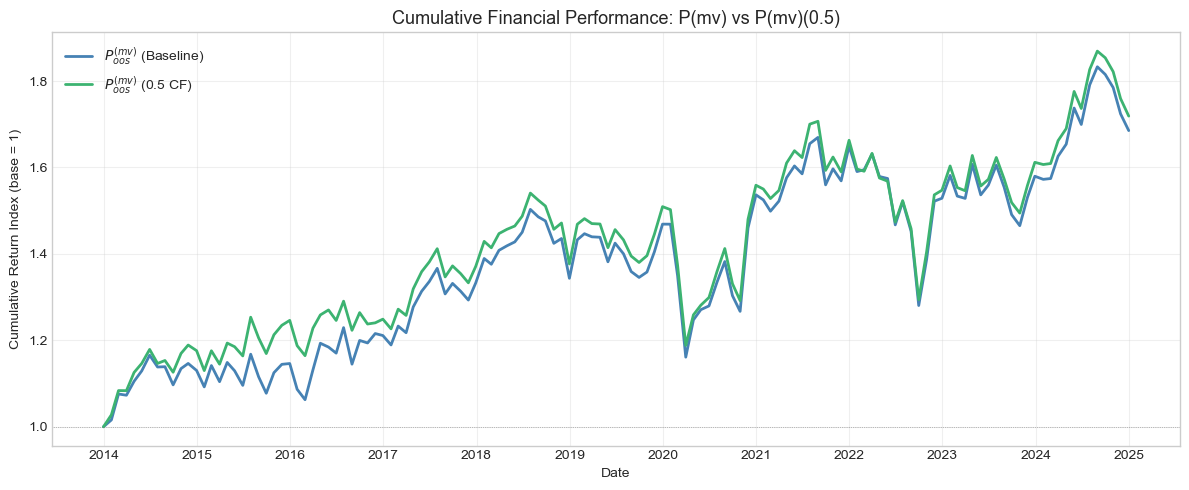

In [53]:
# Cumulative return: P(mv) vs P(mv)(0.5)
cum_mv     = cum_index(ret_mv)
cum_mv_50  = cum_index(ret_mv_50)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(cum_mv.index,    cum_mv.values,    label='$P_{oos}^{(mv)}$ (Baseline)', color='steelblue',     lw=2)
ax.plot(cum_mv_50.index, cum_mv_50.values, label='$P_{oos}^{(mv)}$ (0.5 CF)',   color='mediumseagreen', lw=2)
ax.axhline(1, color='gray', lw=0.5, ls=':')
ax.set_title('Cumulative Financial Performance: P(mv) vs P(mv)(0.5)', fontsize=13)
ax.set_ylabel('Cumulative Return Index (base = 1)')
ax.set_xlabel('Date')
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [54]:
#  Comparison of Summary Statistics: Baseline vs. Decarbonized 

# 1. Compute metrics for the baseline portfolio
m_mv = performance_metrics_oos(ret_mv, rf_monthly, 'P_mv (Baseline)')

# 2. Compute metrics for the 50% decarbonized portfolio
m_mv_50 = performance_metrics_oos(ret_mv_50, rf_monthly, 'P_mv (0.5)')

# 3. Create a comparison table using a list of dictionaries
summary_comparison = pd.DataFrame([m_mv, m_mv_50]).set_index('Portfolio')

print("Out-of-Sample Performance Summary (2014–2024)")
print("=" * 80)
display(summary_comparison)

Out-of-Sample Performance Summary (2014–2024)


,Ann. Return (%),Ann. Volatility (%),Sharpe Ratio,Cumulative Return (%),Max Drawdown (%),Min Monthly (%),Max Monthly (%)
Portfolio,,,,,,,
P_mv (Baseline),5.7423,14.0341,0.3003,68.5323,-23.2965,-13.9577,15.2268
P_mv (0.5),5.8528,13.5315,0.3197,71.8887,-24.1824,-13.4918,14.5656


In [55]:
#  Portfolio Composition Shifts: Top 10 Over/Underweighted Firms for MVP (2024) 

analysis_year = 2024

# 1. Retrieve baseline MVP weights and Decarbonized MVP weights
w_mv_base = weights_mv[analysis_year]
w_mv_opt = weights_mv_50[analysis_year]

# 2. Calculate Weight Shifts (in percentage points)
weight_diff = (w_mv_opt - w_mv_base) * 100

# 3. Construct DataFrame
df_shifts_mv = pd.DataFrame({
    'Baseline_MVP_Weight_%': w_mv_base * 100,
    'Decarbonized_Weight_%': w_mv_opt * 100,
    'Shift_in_Weight_%': weight_diff
}).dropna() # Drop NAs in case of index mismatches

# 4. Attach Firm Names (using your existing firm_info table)
if 'firm_info' in globals() and 'NAME' in firm_info.columns:
    df_shifts_mv = df_shifts_mv.join(firm_info[['NAME']])
else:
    df_shifts_mv['NAME'] = df_shifts_mv.index

# 5. Extract Top 10 Overweighted and Underweighted
df_shifts_mv_sorted = df_shifts_mv.sort_values(by='Shift_in_Weight_%', ascending=False)
top_10_over_mv = df_shifts_mv_sorted.head(10)
top_10_under_mv = df_shifts_mv_sorted.tail(10).sort_values(by='Shift_in_Weight_%', ascending=True)

# 6. Display formatting
print(f"=== TOP 10 OVERWEIGHTED FIRMS IN {analysis_year} (MVP Strategy) ===")
print("(Capital added to these firms to replace heavy polluters while minimizing variance)")
display(top_10_over_mv[['NAME', 'Baseline_MVP_Weight_%', 'Decarbonized_Weight_%', 'Shift_in_Weight_%']].round(3))

print(f"\n=== TOP 10 UNDERWEIGHTED FIRMS IN {analysis_year} (MVP Strategy) ===")
print("(Capital removed/excluded from these firms to hit the 50% carbon target)")
display(top_10_under_mv[['NAME', 'Baseline_MVP_Weight_%', 'Decarbonized_Weight_%', 'Shift_in_Weight_%']].round(3))

=== TOP 10 OVERWEIGHTED FIRMS IN 2024 (MVP Strategy) ===
(Capital added to these firms to replace heavy polluters while minimizing variance)


,NAME,Baseline_MVP_Weight_%,Decarbonized_Weight_%,Shift_in_Weight_%
CH0014786500,VALIANT 'R',0.284,1.089,0.805
GB0002374006,DIAGEO,0.000,0.503,0.503
DE0007042301,RHOEN-KLINIKUM,11.748,12.122,0.374
FR0013280286,BIOMERIEUX,0.827,1.152,0.324
FR0000133308,ORANGE,1.690,1.998,0.308
DK0010307958,JYSKE BANK,0.358,0.639,0.281
IL0010811243,ELBIT SYSTEMS,2.244,2.494,0.251
IE00BGH1M568,PERRIGO,1.214,1.464,0.250
DK0060636678,TRYG,3.693,3.924,0.231
GB0002634946,BAE SYSTEMS,3.778,3.957,0.179



=== TOP 10 UNDERWEIGHTED FIRMS IN 2024 (MVP Strategy) ===
(Capital removed/excluded from these firms to hit the 50% carbon target)


,NAME,Baseline_MVP_Weight_%,Decarbonized_Weight_%,Shift_in_Weight_%
GB0001667087,CAMELLIA,2.309,0.000,-2.309
CH0008742519,SWISSCOM 'R',3.064,2.577,-0.486
ES0112501012,EBRO FOODS,11.029,10.683,-0.347
NL0009432491,KONINKLIJKE VOPAK,0.298,0.000,-0.298
CH0044328745,CHUBB,2.847,2.598,-0.249
IL0002300114,BEZEQ ISRAELI TELECOMMUNICATION,5.426,5.255,-0.171
NL0011794037,KONINKLIJKE AHOLD DELHAIZE,0.118,0.000,-0.118
GB00B3CX3644,STV GROUP,8.489,8.420,-0.069
DK0060477503,TOPDANMARK DEAD - DELIST.21/10/24,1.540,1.511,-0.028
BMG850801025,STOLT-NIELSEN,0.004,0.000,-0.004


## 4.4 Tracking Error Minimization

We construct a passive decarbonized portfolio out-of-sample over 2014-2024 by minimizing the deviation from our market benchmark:

1. Calculate Benchmark Weights: For each year Y, calculate the exact Value-Weighted (VW) allocations using the market capitalization from the end of year Y-1.

2. Solve Constrained Optimization: Solve for the minimum tracking error using the SLSQP algorithm. We minimize the tracking error relative to the benchmark while enforcing the strict carbon limit where the portfolio's footprint must be less than or equal to 50% of the VW benchmark's footprint.

3. Compute OOS Returns: Calculate 12 monthly out-of-sample returns for the 50% decarbonized VW portfolio, applying the intra-year buy-and-hold weight drift.

4. Financial Performance Analysis: Compute the ex-post characteristics (annualized return, volatility, Sharpe ratio) and compare the summary statistics against the original Value-Weighted benchmark.

5. Cumulative Returns Comparison: Plot the cumulative return series of both the passive baseline and the tracking error strategy to visually assess the performance penalty of decarbonization.

6. Carbon Metric Evolution: Calculate and plot the temporal evolution of both the Weighted Average Carbon Intensity (WACI) and the absolute Carbon Footprint (CF) for the tracking error strategy to visually confirm continuous adherence to the 50% environmental constraint.

7. Portfolio Composition Shifts: Analyze the specific weight allocations in the most recent year (2024) to identify the top 10 overweighted and top 10 underweighted firms, illustrating how capital is surgically reallocated from heavy polluters to cleaner proxies to maintain benchmark tracking.

In [56]:
#  Define the Tracking Error Optimizer 

def solve_min_te_carbon_oos(Sigma_monthly, isins, emissions_arr, caps_arr, target_cf, w_benchmark):
    """
    Long-only portfolio that minimizes Tracking Error relative to a benchmark,
    bounded by a maximum Carbon Footprint constraint. (Optimized for speed & stability)
    """
    N = len(isins)
    Sigma_ann = Sigma_monthly * 12

    # Use a scale factor so the optimizer doesn't get stuck on tiny floats
    SCALE_FACTOR = 10000

    # 1. OPTIMIZATION: Minimize TE Variance and scale it up
    def te_variance(w):
        diff = w - w_benchmark
        return (diff.T @ Sigma_ann @ diff) * SCALE_FACTOR

    # 2. OPTIMIZATION: Analytical Gradient (Jacobian) scaled up
    def te_jacobian(w):
        diff = w - w_benchmark
        return 2 * (Sigma_ann @ diff) * SCALE_FACTOR

    # Calculate firm-level carbon intensity
    caps_safe = np.where(caps_arr == 0, np.inf, caps_arr)
    cei = np.nan_to_num(emissions_arr / caps_safe, nan=np.inf)

    # Constraints
    constraints = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
        {'type': 'ineq', 'fun': lambda w: target_cf - np.sum(w * cei)}
    ]

    bounds = tuple((0.0, 1.0) for _ in range(N))

    # Run the solver
    result = minimize(
        te_variance, w_benchmark, method='SLSQP',
        jac=te_jacobian,
        bounds=bounds, constraints=constraints,
        options={'ftol': 1e-6, 'maxiter': 1000, 'disp': False}
    )

    if not result.success:
        print("  WARNING: Optimizer did not converge. Returning benchmark weights.")
        w_opt = w_benchmark
    else:
        w_opt = result.x

    w_opt = np.clip(w_opt, 0.0, None)
    if w_opt.sum() > 0:
        w_opt /= w_opt.sum()

    return pd.Series(w_opt, index=isins)

In [57]:
#  OOS Loop: P_vw(0.5): Tracking Error Minimization 

oos_returns_vw_50 = {}
weights_vw_50 = {}

print(f"{'Year':<6} {'Target CF':<12} {'Achieved CF':<12} {'Ann. Return'}")
print("-" * 45)

for oos_year in OOS_YEARS:
    data_year = oos_year - 1

    # 1. Load historical estimations
    prices_est = load_investment_set_local(oos_year)
    returns_est = compute_returns_oos(prices_est)
    _, Sigma_oos = compute_mu_sigma_oos(returns_est)
    isins = returns_est.index.tolist()

    # 2. Extract Clean Carbon and Market Cap data
    emissions_clean = total_emissions_eur.loc[~total_emissions_eur.index.duplicated(keep='first'), data_year]
    caps_clean = mv_annual.loc[~mv_annual.index.duplicated(keep='first'), data_year]

    emissions_yr = emissions_clean.reindex(isins).fillna(0).values
    caps_yr = caps_clean.reindex(isins).fillna(np.inf).values

    # 3. Compute Benchmark (VW) Weights for year Y
    caps_vw = caps_clean.reindex(isins).fillna(0).values
    if caps_vw.sum() > 0:
        w_vw = caps_vw / caps_vw.sum()
    else:
        w_vw = np.ones(len(isins)) / len(isins)

    # 4. Calculate Target CF (50% reduction from the VW benchmark)
    target_cf = 0.5 * cf_history_vw[oos_year]

    # 5. Generate tracking error optimal weights
    w = solve_min_te_carbon_oos(Sigma_oos, isins, emissions_yr, caps_yr, target_cf, w_vw)

    # 6. Compute OOS performance
    oos_ret = compute_oos_returns_local(oos_year, w)
    oos_returns_vw_50[oos_year] = oos_ret
    weights_vw_50[oos_year] = w

    # Verification printout
    achieved_cf = np.sum(w.values * np.nan_to_num(emissions_yr / np.where(caps_yr==0, np.inf, caps_yr), nan=0))
    ann = ((1 + oos_ret).prod() - 1) * 100
    print(f"{oos_year:<6} {target_cf:<12.2f} {achieved_cf:<12.2f} {ann:+.2f}%")

# Concatenate OOS returns
ret_vw_50 = pd.concat([oos_returns_vw_50[y] for y in OOS_YEARS])
ret_vw_50.index = pd.to_datetime(ret_vw_50.index)

Year   Target CF    Achieved CF  Ann. Return
---------------------------------------------
2014   102.36       102.36       -4.92%
2015   92.70        92.70        -1.57%
2016   97.64        97.64        +0.22%
2017   104.69       104.69       +24.37%
2018   100.44       100.16       -13.56%
2019   75.77        75.77        +25.26%
2020   77.65        77.65        +3.59%
2021   62.76        62.76        +18.43%
2022   58.57        58.57        -14.30%
2023   47.53        47.53        +22.69%
2024   46.06        46.06        +1.78%


In [58]:
#  Comparison of Summary Statistics: Passive vs. Tracking Error 

# 1. Compute metrics using the baseline VW returns (ret_vw_oos)
m_vw_base = performance_metrics_oos(ret_vw_oos, rf_monthly, 'P_vw (Baseline)')
m_vw_50 = performance_metrics_oos(ret_vw_50, rf_monthly, 'P_vw (0.5)')

# 2. Create table and transpose it (.T) so metrics are rows and portfolios are columns
summary_comparison_vw = pd.DataFrame([m_vw_base, m_vw_50]).set_index('Portfolio').T

print("Tracking Error Strategy Performance Summary (2014–2024)")
print("=" * 60)
display(summary_comparison_vw)

Tracking Error Strategy Performance Summary (2014–2024)


Portfolio,P_vw (Baseline),P_vw (0.5)
Ann. Return (%),6.0650,5.9550
Ann. Volatility (%),16.5067,16.4417
Sharpe Ratio,0.2749,0.2693
Cumulative Return (%),67.6435,65.8180
Max Drawdown (%),-27.9753,-27.9133
Min Monthly (%),-16.0759,-16.1440
Max Monthly (%),18.9191,18.7756


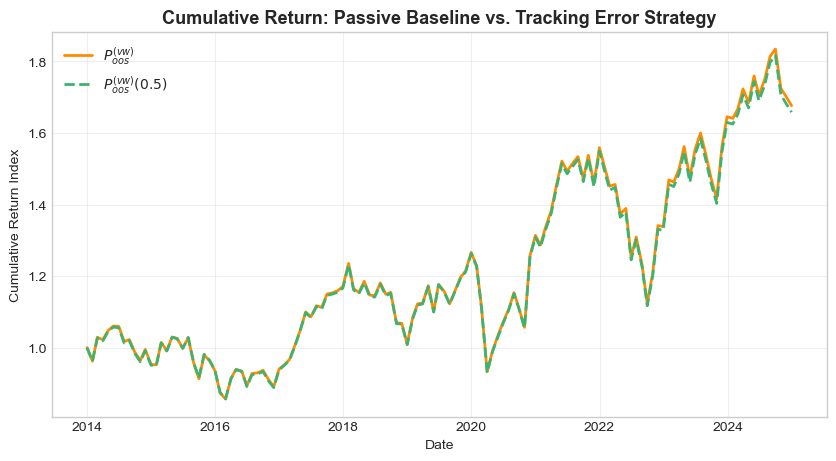

In [59]:
#  Plotting the Cumulative Returns for VW Benchmarks 

cum_vw_base = cum_index(ret_vw_oos)
cum_vw_decarb = cum_index(ret_vw_50)

plt.figure(figsize=(10, 5))
plt.plot(cum_vw_base.index, cum_vw_base.values, label='$P_{oos}^{(vw)}$', color='darkorange', lw=2)
plt.plot(cum_vw_decarb.index, cum_vw_decarb.values, label='$P_{oos}^{(vw)}(0.5)$', color='mediumseagreen', lw=2, linestyle='--')

plt.title('Cumulative Return: Passive Baseline vs. Tracking Error Strategy', fontsize=13, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Cumulative Return Index')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

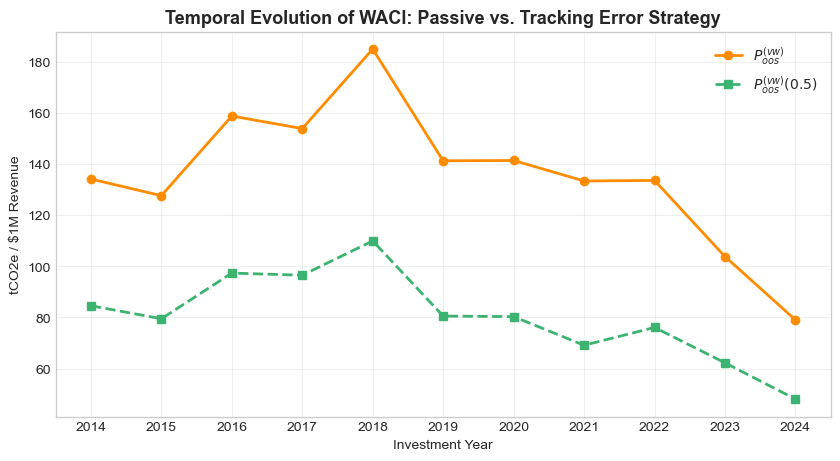

In [60]:
#  Calculate Metrics and Plot WACI for Tracking Error Strategy 

# 1. Calculate WACI and CF for the decarbonized VW portfolio
waci_history_vw_50 = {}
cf_history_vw_50 = {}

for oos_year in OOS_YEARS:
    waci, cf = compute_carbon_metrics(
        weights=weights_vw_50[oos_year],
        investment_year=oos_year,
        carbon_intensity=carbon_intensity,
        total_emissions=total_emissions_eur,
        mv_annual=mv_annual
    )
    waci_history_vw_50[oos_year] = waci
    cf_history_vw_50[oos_year] = cf

# 2. Prepare data for plotting
years = list(OOS_YEARS)
waci_vw_base = [waci_history_vw[y] for y in years]
waci_vw_decarb = [waci_history_vw_50[y] for y in years]

# 3. Plot WACI Evolution
plt.figure(figsize=(10, 5))
plt.plot(years, waci_vw_base, marker='o', label='$P_{oos}^{(vw)}$', color='darkorange', linewidth=2)
plt.plot(years, waci_vw_decarb, marker='s', label='$P_{oos}^{(vw)}(0.5)$', color='mediumseagreen', linewidth=2, linestyle='--')

plt.title('Temporal Evolution of WACI: Passive vs. Tracking Error Strategy', fontsize=13, fontweight='bold')
plt.xlabel('Investment Year')
plt.ylabel('tCO2e / $1M Revenue')
plt.xticks(years)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

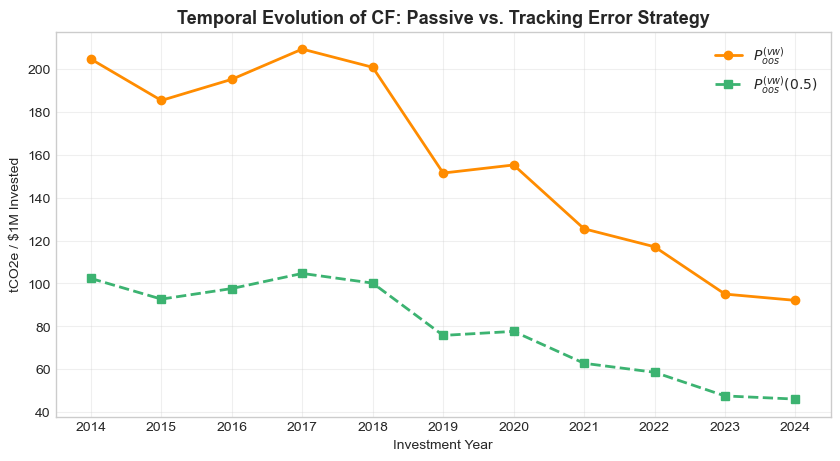

In [61]:
#  Plotting the Evolution of Carbon Footprint (CF) for TE Strategy 

cf_vw_base = [cf_history_vw[y] for y in years]
cf_vw_decarb = [cf_history_vw_50[y] for y in years]

plt.figure(figsize=(10, 5))
plt.plot(years, cf_vw_base, marker='o', label='$P_{oos}^{(vw)}$', color='darkorange', linewidth=2)
plt.plot(years, cf_vw_decarb, marker='s', label='$P_{oos}^{(vw)}(0.5)$', color='mediumseagreen', linewidth=2, linestyle='--')

plt.title('Temporal Evolution of CF: Passive vs. Tracking Error Strategy', fontsize=13, fontweight='bold')
plt.xlabel('Investment Year')
plt.ylabel('tCO2e / $1M Invested')
plt.xticks(years)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [62]:
#  Portfolio Composition Shifts: Top 10 Over/Underweighted Firms (2024) 

analysis_year = 2024
data_year = analysis_year - 1

# 1. Retrieve baseline VW weights for the chosen year
prices_est = load_investment_set_local(analysis_year)
returns_est = compute_returns_oos(prices_est)
isins = returns_est.index.tolist()

caps_clean = mv_annual.loc[~mv_annual.index.duplicated(keep='first'), data_year]
caps_vw = caps_clean.reindex(isins).fillna(0).values
w_vw_base = pd.Series(caps_vw / caps_vw.sum(), index=isins)

# 2. Retrieve TE Optimizer weights for the same year
w_vw_opt = weights_vw_50[analysis_year]

# 3. Calculate Weight Shifts (in percentage points)
weight_diff = (w_vw_opt - w_vw_base) * 100
weight_diff.name = 'Shift_pct'

# 4. Construct DataFrame and merge with Firm Names
df_shifts = pd.DataFrame({
    'Baseline_VW_Weight_%': w_vw_base * 100,
    'Decarbonized_Weight_%': w_vw_opt * 100,
    'Shift_in_Weight_%': weight_diff
})

# Attach names if firm_info exists in your environment
if 'firm_info' in globals() and 'NAME' in firm_info.columns:
    df_shifts = df_shifts.join(firm_info[['NAME']])
else:
    df_shifts['NAME'] = df_shifts.index

# 5. Extract Top 10 Overweighted and Underweighted
df_shifts_sorted = df_shifts.sort_values(by='Shift_in_Weight_%', ascending=False)
top_10_over = df_shifts_sorted.head(10)
top_10_under = df_shifts_sorted.tail(10).sort_values(by='Shift_in_Weight_%', ascending=True)

# 6. Display formatting
print(f"=== TOP 10 OVERWEIGHTED FIRMS IN {analysis_year} ===")
print("(Capital added to these firms to replace heavy polluters)")
display(top_10_over[['NAME', 'Baseline_VW_Weight_%', 'Decarbonized_Weight_%', 'Shift_in_Weight_%']].round(3))

print(f"\n=== TOP 10 UNDERWEIGHTED FIRMS IN {analysis_year} ===")
print("(Capital removed/excluded from these firms to hit the 50% carbon target)")
display(top_10_under[['NAME', 'Baseline_VW_Weight_%', 'Decarbonized_Weight_%', 'Shift_in_Weight_%']].round(3))

=== TOP 10 OVERWEIGHTED FIRMS IN 2024 ===
(Capital added to these firms to replace heavy polluters)


,NAME,Baseline_VW_Weight_%,Decarbonized_Weight_%,Shift_in_Weight_%
DE000ENAG999,E ON N,0.251,0.343,0.092
FR0000051070,MAUREL ET PROM,0.007,0.098,0.092
DE0006231004,INFINEON TECHNOLOGIES,0.442,0.522,0.080
GB0006650450,OXFORD INSTRUMENTS,0.015,0.089,0.074
DE0005089031,UNITED INTERNET,0.041,0.114,0.073
IT0005239360,UNICREDIT,0.331,0.402,0.072
FR0000130213,LAGARDERE GROUPE,0.027,0.099,0.072
SE0000106270,HENNES & MAURITZ B,0.167,0.237,0.069
NL0000009082,KPN KON,0.118,0.182,0.063
GB0007958233,SENIOR,0.007,0.070,0.063



=== TOP 10 UNDERWEIGHTED FIRMS IN 2024 ===
(Capital removed/excluded from these firms to hit the 50% carbon target)


,NAME,Baseline_VW_Weight_%,Decarbonized_Weight_%,Shift_in_Weight_%
CH0012214059,HOLCIM,0.323,0.001,-0.322
DE0007037129,RWE,0.261,0.000,-0.261
IE0001827041,CRH PUBLIC LIMITED,0.289,0.041,-0.248
FR0000124141,VEOLIA ENVIRON,0.188,0.006,-0.182
DK0010244508,A P MOLLER MAERSK B,0.171,0.005,-0.166
IE00BYTBXV33,RYANAIR HOLDINGS,0.166,0.005,-0.161
IT0003132476,ENI,0.463,0.306,-0.157
AT0000743059,OMV,0.133,0.003,-0.130
IT0003128367,ENEL,0.515,0.394,-0.121
ES0130670112,ENDESA,0.183,0.062,-0.121


## 4.5 Four-portfolio comparison

This section presents the three core comparison figures for Section 5 of the report: a unified cumulative return chart, a carbon metric summary, and a year-by-year return breakdown that reveals the asymmetric behaviour of each strategy across market regimes.

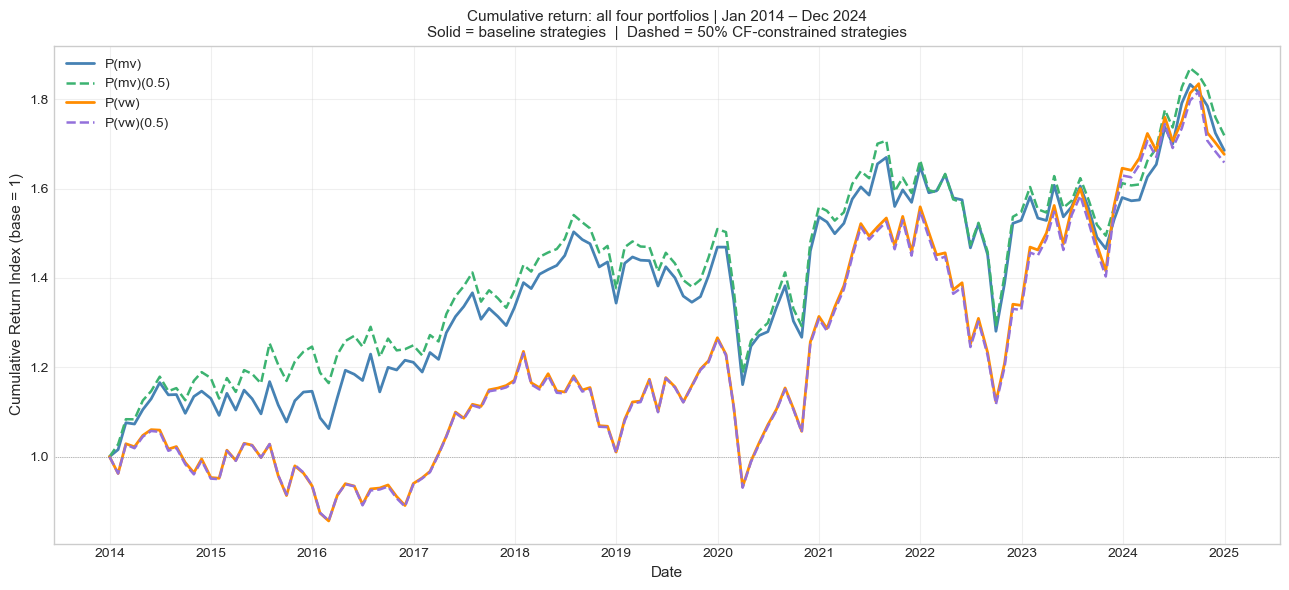

In [63]:
#  F11: All-4 portfolios: cumulative return on one canvas 

portfolios_all = [
    ('P(mv)',       ret_mv,     'steelblue',     '-',  2.0),
    ('P(mv)(0.5)', ret_mv_50,  'mediumseagreen', '--', 1.8),
    ('P(vw)',       ret_vw_oos, 'darkorange',     '-',  2.0),
    ('P(vw)(0.5)', ret_vw_50,  'mediumpurple',   '--', 1.8),
]

fig, ax = plt.subplots(figsize=(13, 6))

for label, ret, color, ls, lw in portfolios_all:
    r  = ret.dropna()
    ci = (1 + r).cumprod()
    t0 = r.index[0] - pd.DateOffset(months=1)
    ci = pd.concat([pd.Series([1.0], index=[t0]), ci])
    ax.plot(ci.index, ci.values, color=color, ls=ls, lw=lw, label=label)

ax.axhline(1, color='gray', lw=0.5, ls=':')
ax.set_ylabel('Cumulative Return Index (base = 1)', fontsize=11)
ax.set_xlabel('Date', fontsize=11)
ax.set_title(
    'Cumulative return: all four portfolios | Jan 2014 – Dec 2024\n'
    'Solid = baseline strategies  |  Dashed = 50% CF-constrained strategies',
    fontsize=11
)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()

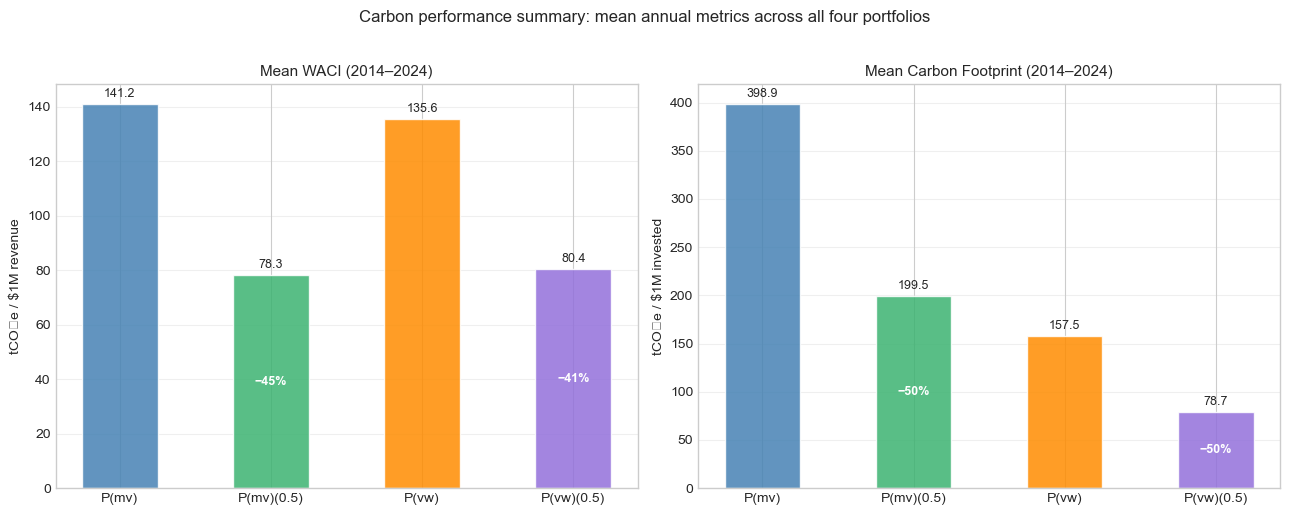

In [64]:
#  F16: Mean WACI and Mean CF summary bars: all 4 portfolios 

labels_bar = ['P(mv)', 'P(mv)(0.5)', 'P(vw)', 'P(vw)(0.5)']
colors_bar = ['steelblue', 'mediumseagreen', 'darkorange', 'mediumpurple']

waci_means = [
    np.mean(list(waci_history_mv.values())),
    np.mean(list(waci_history_50.values())),
    np.mean(list(waci_history_vw.values())),
    np.mean(list(waci_history_vw_50.values())),
]
cf_means = [
    np.mean(list(cf_history_mv.values())),
    np.mean(list(cf_history_50.values())),
    np.mean(list(cf_history_vw.values())),
    np.mean(list(cf_history_vw_50.values())),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, values, ylabel, title in [
    (axes[0], waci_means,
     'tCO₂e / $1M revenue',
     'Mean WACI (2014–2024)'),
    (axes[1], cf_means,
     'tCO₂e / $1M invested',
     'Mean Carbon Footprint (2014–2024)'),
]:
    bars = ax.bar(
        labels_bar, values,
        color=colors_bar, edgecolor='white', alpha=0.85, width=0.5
    )
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=11)
    ax.grid(True, alpha=0.3, axis='y')
    for bar, val in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val + max(values) * 0.01,
            f'{val:.1f}',
            ha='center', va='bottom', fontsize=9
        )

    # Add % reduction labels for constrained portfolios
    baselines = [values[0], values[0], values[2], values[2]]
    for i, (val, base) in enumerate(zip(values, baselines)):
        if val < base:
            pct = (base - val) / base * 100
            ax.text(
                i, val / 2,
                f'−{pct:.0f}%',
                ha='center', va='center',
                fontsize=9, color='white', fontweight='bold'
            )

plt.suptitle(
    'Carbon performance summary: mean annual metrics across all four portfolios',
    fontsize=12, y=1.02
)
plt.tight_layout()
plt.show()

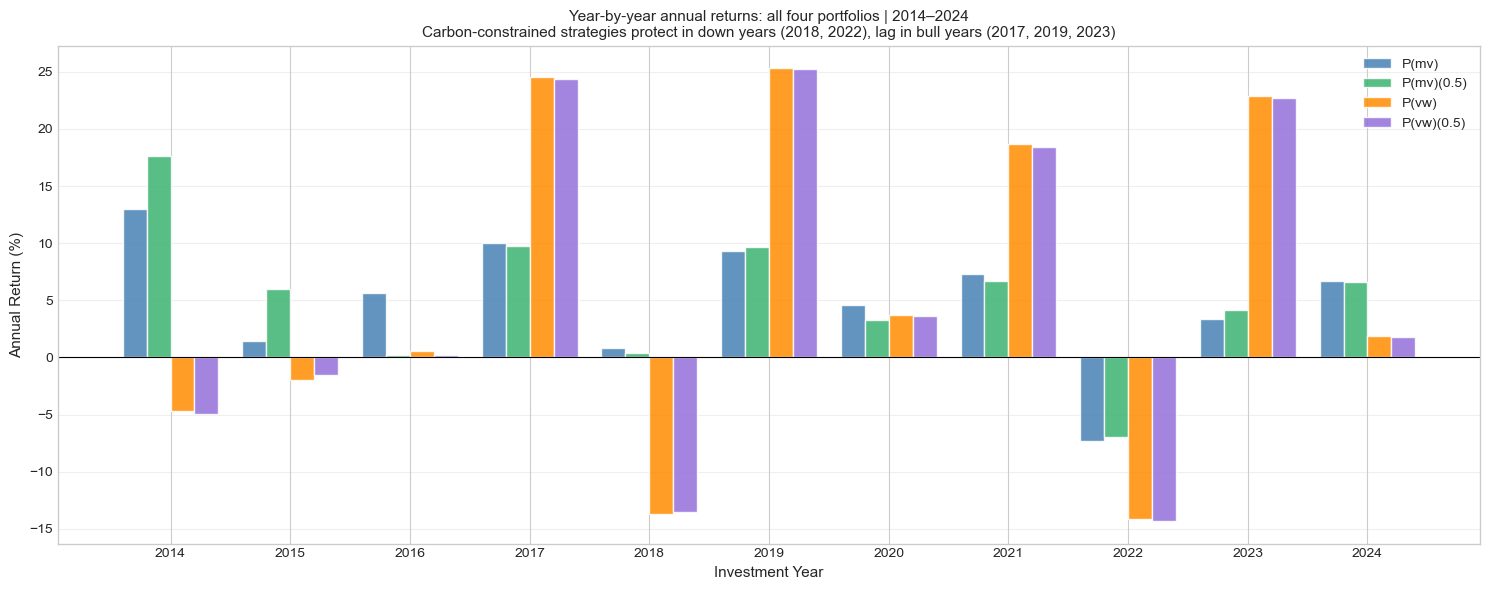

Year-by-year annual returns (%):


,P(mv),P(mv)(0.5),P(vw),P(vw)(0.5)
Year,,,,
2014,13.03,17.61,-4.67,-4.92
2015,1.43,5.96,-1.95,-1.57
2016,5.65,0.23,0.56,0.22
2017,10.06,9.79,24.56,24.37
2018,0.79,0.40,-13.71,-13.56
2019,9.33,9.63,25.32,25.26
2020,4.62,3.28,3.76,3.59
2021,7.32,6.67,18.67,18.43
2022,-7.30,-6.95,-14.14,-14.30


In [65]:
#  F17: Year-by-year annual returns: all 4 portfolios 

years_oos = list(OOS_YEARS)

annual_returns_all = {}
for label, oos_dict in [
    ('P(mv)',       oos_returns_mv),
    ('P(mv)(0.5)', oos_returns_mv_50),
    ('P(vw)',       oos_returns_vw),
    ('P(vw)(0.5)', oos_returns_vw_50),
]:
    annual_returns_all[label] = [
        ((1 + oos_dict[y].dropna()).prod() - 1) * 100
        for y in years_oos
    ]

x      = np.arange(len(years_oos))
width  = 0.20
labels = ['P(mv)', 'P(mv)(0.5)', 'P(vw)', 'P(vw)(0.5)']
colors = ['steelblue', 'mediumseagreen', 'darkorange', 'mediumpurple']

fig, ax = plt.subplots(figsize=(15, 6))

for i, (label, color) in enumerate(zip(labels, colors)):
    vals = annual_returns_all[label]
    bars = ax.bar(
        x + (i - 1.5) * width, vals,
        width=width, label=label,
        color=color, alpha=0.85, edgecolor='white'
    )

ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(years_oos, fontsize=10)
ax.set_ylabel('Annual Return (%)', fontsize=11)
ax.set_xlabel('Investment Year', fontsize=11)
ax.set_title(
    'Year-by-year annual returns: all four portfolios | 2014–2024\n'
    'Carbon-constrained strategies protect in down years (2018, 2022), '
    'lag in bull years (2017, 2019, 2023)',
    fontsize=11
)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Summary table
df_annual = pd.DataFrame(annual_returns_all, index=years_oos).round(2)
df_annual.index.name = 'Year'
print('Year-by-year annual returns (%):')
display(df_annual)

# 5 — Extended Performance Analysis

This section adds a full suite of risk-adjusted, benchmark-relative, carbon, and cost metrics beyond the standard Sharpe ratio. All four portfolios (P(mv), P(mv)(0.5), P(vw), P(vw)(0.5)) are evaluated side-by-side on 23 metrics across 6 categories.

**Market proxy:** P(vw) is used as the market portfolio for all CAPM-derived metrics (Beta, Jensen's Alpha, Treynor Ratio), consistent with it being the value-weighted index of the full EUR CO₂ universe.

**Benchmark pairings:** P(mv)(0.5) is benchmarked against P(mv); P(vw)(0.5) is benchmarked against P(vw).

In [66]:
from scipy.stats import linregress
from scipy.stats import skew as sp_skew, kurtosis as sp_kurt
from scipy.stats import t as t_dist
import warnings
warnings.filterwarnings('ignore')

## 5.1 Reconstruct VW weights and market proxy

We rebuild the value-weighted weight vectors for each year so they can be used in Active Share computations.

In [67]:
#  Reconstruct VW weights dict (same universe as MVP each year) 
vw_weights_dict = {}
for oos_year in OOS_YEARS:
    data_year = oos_year - 1
    caps_clean = mv_annual.loc[~mv_annual.index.duplicated(keep='first'), data_year]
    isins = weights_mv[oos_year].index.tolist()
    caps_yr = caps_clean.reindex(isins).fillna(0)
    if caps_yr.sum() > 0:
        vw_weights_dict[oos_year] = caps_yr / caps_yr.sum()
    else:
        vw_weights_dict[oos_year] = pd.Series(1 / len(isins), index=isins)

# Market proxy = VW portfolio returns
ret_market = ret_vw_oos.copy()
print('VW weights dict built for years:', sorted(vw_weights_dict.keys()))
print('Market proxy: ret_vw_oos (value-weighted EUR CO2 universe)')

VW weights dict built for years: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
Market proxy: ret_vw_oos (value-weighted EUR CO2 universe)


## 5.2 Tracking Error and Information Ratio

Compute annualised ex-post tracking error and information ratio for the two constrained portfolios relative to their respective benchmarks.

In [68]:
#  Tracking Error and Information Ratio (ex-post) 
def te_vs_bench(ret_p, ret_b):
    """
    Ex-post tracking error and information ratio.
    TE  = std(Rp - Rb, ddof=0) * sqrt(12)
    IR  = mean(Rp - Rb) * 12 / TE
    """
    diff = (ret_p.reindex(ret_b.index) - ret_b).dropna()
    te_ann = diff.std(ddof=0) * np.sqrt(12)
    ir = (diff.mean() * 12) / te_ann if te_ann > 0 else np.nan
    return round(te_ann * 100, 3), round(ir, 3)

te_mv50, ir_mv50 = te_vs_bench(ret_mv_50, ret_mv)
te_vw50, ir_vw50 = te_vs_bench(ret_vw_50, ret_vw_oos)

print(f'P(mv)(0.5) vs P(mv) : TE: {te_mv50:.3f}%  |  IR: {ir_mv50:.3f}')
print(f'P(vw)(0.5) vs P(vw) : TE: {te_vw50:.3f}%  |  IR: {ir_vw50:.3f}')

P(mv)(0.5) vs P(mv) : TE: 2.080%  |  IR: 0.053
P(vw)(0.5) vs P(vw) : TE: 0.249%  |  IR: -0.442


## 5.3 Master extended metrics function

A single function computes all 23 metrics for any portfolio, given its return series, the market return series, the risk-free rate, weight dictionaries, and carbon histories.

In [69]:
# Extended Performance Metrics (23 metrics across 6 categories)

def extended_metrics(ret_p, ret_m, rf_series, weights_dict, weights_bench_dict,
                     waci_hist, cf_hist, waci_hist_base, cf_hist_base, label):
    """
    Parameters
    ret_p              : monthly portfolio returns (pd.Series, DatetimeIndex)
    ret_m              : monthly market returns = ret_vw_oos
    rf_series          : monthly rf in decimal
    weights_dict       : {year: pd.Series} portfolio weights
    weights_bench_dict : {year: pd.Series} benchmark weights for Active Share
    waci_hist / cf_hist           : {year: float} this portfolio carbon history
    waci_hist_base / cf_hist_base : {year: float} baseline portfolio carbon history
    label              : string name for this portfolio
    """
    r  = ret_p.dropna()
    rm = ret_m.reindex(r.index).dropna()
    r  = r.reindex(rm.index).dropna()
    rf = rf_series.reindex(r.index).fillna(0)
    T  = len(r)

    # 1. Returns
    ann_ret  = r.mean() * 12
    cum_ret  = (1 + r).prod() - 1
    cagr     = (1 + cum_ret) ** (12 / T) - 1
    win_rate = (r > 0).mean()

    # 2. Risk
    ann_vol  = r.std(ddof=0) * np.sqrt(12)
    cum_idx  = (1 + r).cumprod()
    roll_max = cum_idx.cummax()
    mdd      = ((cum_idx - roll_max) / roll_max).min()
    var95    = np.percentile(r, 5)      # threshold for CVaR
    cvar95   = r[r <= var95].mean()     # CVaR 95%: mean of worst 5% months
    skewness = float(sp_skew(r))
    xkurt    = float(sp_kurt(r, fisher=True))

    # 3. Risk-adjusted
    rf_ann  = rf.mean() * 12
    sharpe  = (ann_ret - rf_ann) / ann_vol

    re  = r - rf
    rem = rm - rf.reindex(rm.index).fillna(0)
    n   = len(re)

    # OLS via matrix algebra to get correct SE for both intercept and slope
    X       = np.column_stack([np.ones(n), rem.values])
    y       = re.values
    bhat    = np.linalg.lstsq(X, y, rcond=None)[0]
    alpha_m, beta = bhat[0], bhat[1]
    resid   = y - X @ bhat
    s2      = (resid ** 2).sum() / (n - 2)   # unbiased variance estimate
    XtXinv  = np.linalg.inv(X.T @ X)
    # se_alpha = sqrt(s2 * (X'X)^{-1}_{00})  the correct intercept SE
    se_alpha = np.sqrt(s2 * XtXinv[0, 0])

    alpha_ann  = alpha_m * 12
    r_squared  = float(np.corrcoef(rem.values, re.values)[0, 1]) ** 2
    treynor    = (ann_ret - rf_ann) / beta if beta != 0 else np.nan

    # Sortino: downside deviation on excess returns
    dd_sq    = np.minimum(re.values, 0) ** 2
    sigma_dn = np.sqrt(dd_sq.mean()) * np.sqrt(12)
    sortino  = (ann_ret - rf_ann) / sigma_dn if sigma_dn > 0 else np.nan

    # 4. Benchmark-relative (Active Share)
    port_years = sorted(weights_dict.keys())
    as_vals = []
    for yr in port_years:
        if yr in weights_bench_dict:
            wp = weights_dict[yr]
            wb = weights_bench_dict[yr]
            common = wp.index.union(wb.index)
            diff = wp.reindex(common).fillna(0) - wb.reindex(common).fillna(0)
            as_vals.append(0.5 * diff.abs().sum())
    active_share_avg = np.mean(as_vals) if as_vals else np.nan

    # 5. Carbon
    carbon_years = sorted(waci_hist.keys())
    mean_waci = np.mean([waci_hist[y] for y in carbon_years])
    mean_cf   = np.mean([cf_hist[y]   for y in carbon_years])
    waci_reduc = np.mean(
        [(waci_hist_base[y] - waci_hist[y]) / waci_hist_base[y]
         for y in carbon_years if waci_hist_base.get(y, 0) > 0]
    )
    cf_reduc = np.mean(
        [(cf_hist_base[y] - cf_hist[y]) / cf_hist_base[y]
         for y in carbon_years if cf_hist_base.get(y, 0) > 0]
    )
    carbon_eff = (sharpe / mean_cf * 1000) if mean_cf > 0 else np.nan

    # 6. Turnover and transaction costs
    to_vals = []
    for i, yr in enumerate(port_years[1:], 1):
        prev = port_years[i - 1]
        if prev in weights_dict and yr in weights_dict:
            wp  = weights_dict[yr]
            wpp = weights_dict[prev]
            common = wp.index.union(wpp.index)
            to_vals.append(
                (wp.reindex(common).fillna(0) -
                 wpp.reindex(common).fillna(0)).abs().sum()
            )
    mean_turnover = np.mean(to_vals) if to_vals else np.nan
    tc_annual     = mean_turnover * 0.001   # 10bp institutional round-trip
    net_ret       = ann_ret - tc_annual
    net_sharpe    = (net_ret - rf_ann) / ann_vol

    return {
        'Portfolio': label,
        # Returns
        'Ann. Return (%)':           round(ann_ret * 100, 2),
        'CAGR (%)':                  round(cagr * 100, 2),
        'Cumulative Return (%)':     round(cum_ret * 100, 2),
        'Win Rate (%)':              round(win_rate * 100, 1),
        # Risk
        'Ann. Volatility (%)':       round(ann_vol * 100, 2),
        'Max Drawdown (%)':          round(mdd * 100, 2),
        'CVaR 95% monthly (%)':      round(cvar95 * 100, 2),
        'Skewness':                  round(skewness, 3),
        'Excess Kurtosis':           round(xkurt, 3),
        # Risk-adjusted
        'Sharpe Ratio':              round(sharpe, 3),
        'Sortino Ratio':             round(sortino, 3),
        'Beta':                      round(beta, 3),
        "Jensen's Alpha (ann %)": round(alpha_ann * 100, 3),
        'Treynor Ratio':             round(treynor, 3),
        'CAPM R2':                   round(r_squared, 3),
        # Benchmark-relative
        'Active Share (avg %)':      round(active_share_avg * 100, 1),
        # Carbon
        'Mean WACI':                 round(mean_waci, 1),
        'Mean CF':                   round(mean_cf, 1),
        'WACI Reduction (%)':        round(waci_reduc * 100, 1),
        'CF Reduction (%)':          round(cf_reduc * 100, 1),
        'Carbon Efficiency Score':   round(carbon_eff, 3),
        # Turnover
        'Mean Annual Turnover (%)':  round(mean_turnover * 100, 1),
        'Est. TC Annual (%)':        round(tc_annual * 100, 3),
        'Net Sharpe (post TC)':      round(net_sharpe, 3),
    }

print('extended_metrics() defined successfully.')


extended_metrics() defined successfully.


## 5.4 Master comparison table (all 4 portfolios, 23 metrics)

In [70]:
# Run extended_metrics for all 4 portfolios

m1 = extended_metrics(
    ret_mv, ret_market, rf_monthly,
    weights_mv, vw_weights_dict,
    waci_history_mv, cf_history_mv,
    waci_history_mv, cf_history_mv,
    'P(mv)'
)

m2 = extended_metrics(
    ret_mv_50, ret_market, rf_monthly,
    weights_mv_50, weights_mv,
    waci_history_50, cf_history_50,
    waci_history_mv, cf_history_mv,
    'P(mv)(0.5)'
)

m3 = extended_metrics(
    ret_vw_oos, ret_market, rf_monthly,
    vw_weights_dict, vw_weights_dict,
    waci_history_vw, cf_history_vw,
    waci_history_vw, cf_history_vw,
    'P(vw)'
)

m4 = extended_metrics(
    ret_vw_50, ret_market, rf_monthly,
    weights_vw_50, vw_weights_dict,
    waci_history_vw_50, cf_history_vw_50,
    waci_history_vw, cf_history_vw,
    'P(vw)(0.5)'
)

# Patch in pre-computed TE and IR for constrained portfolios
m2['Tracking Error vs Bench (%)'] = te_mv50
m2['Information Ratio']           = ir_mv50
m4['Tracking Error vs Bench (%)'] = te_vw50
m4['Information Ratio']           = ir_vw50

# Baselines: TE vs themselves = 0, IR undefined
m1['Tracking Error vs Bench (%)'] = 0.0
m1['Information Ratio']           = np.nan
m3['Tracking Error vs Bench (%)'] = 0.0
m3['Information Ratio']           = np.nan

# Define here so downstream cells (carbon scatter, turnover) can reference them
labels_all  = ['P(mv)', 'P(mv)(0.5)', 'P(vw)', 'P(vw)(0.5)']
metrics_all = [m1, m2, m3, m4]

master_table = pd.DataFrame(metrics_all).set_index('Portfolio').T

print('Master comparison table (23 metrics x 4 portfolios):')
print('=' * 70)
display(master_table)


Master comparison table (23 metrics x 4 portfolios):


Portfolio,P(mv),P(mv)(0.5),P(vw),P(vw)(0.5)
Ann. Return (%),5.740,5.850,6.060,5.960
CAGR (%),4.860,5.050,4.810,4.700
Cumulative Return (%),68.530,71.890,67.640,65.820
Win Rate (%),53.800,54.500,53.800,53.800
Ann. Volatility (%),14.030,13.530,16.510,16.440
Max Drawdown (%),-23.300,-24.180,-27.980,-27.910
CVaR 95% monthly (%),-8.650,-8.320,-9.310,-9.290
Skewness,-0.169,-0.186,0.062,0.049
Excess Kurtosis,1.611,1.613,1.416,1.419
Sharpe Ratio,0.409,0.433,0.367,0.362


## 5.5 CAPM attribution table with statistical significance

Jensen's Alpha is tested for statistical significance using a two-sided t-test. Systematic vs idiosyncratic risk decomposition is derived from the CAPM R².

In [71]:
# CAPM attribution table with correct t-statistics for Jensen's Alpha
# scipy.stats.linregress returns SE of the slope, not the intercept.
# We use OLS matrix algebra to obtain the correct SE for the intercept.

def capm_full(ret_p, ret_m, rf, label):
    r   = ret_p.dropna()
    rm  = ret_m.reindex(r.index).dropna()
    r   = r.reindex(rm.index).dropna()
    rfr = rf.reindex(r.index).fillna(0)
    re  = r - rfr
    rem = rm - rfr
    n   = len(re)

    # OLS: [1, Rm_excess] * [alpha_m, beta]' = Re
    X      = np.column_stack([np.ones(n), rem.values])
    y      = re.values
    bhat   = np.linalg.lstsq(X, y, rcond=None)[0]
    alpha_m, slope = bhat[0], bhat[1]

    resid   = y - X @ bhat
    s2      = (resid ** 2).sum() / (n - 2)    # unbiased sigma^2
    XtXinv  = np.linalg.inv(X.T @ X)
    se_alpha = np.sqrt(s2 * XtXinv[0, 0])     # correct SE for intercept

    t_alpha = alpha_m / se_alpha if se_alpha > 0 else np.nan
    p_alpha = 2 * t_dist.sf(abs(t_alpha), df=n - 2) if not np.isnan(t_alpha) else np.nan
    sig     = ('***' if p_alpha < 0.01 else
                '**'  if p_alpha < 0.05 else
                '*'   if p_alpha < 0.10 else '')

    r_val     = float(np.corrcoef(rem.values, re.values)[0, 1])
    r_squared = r_val ** 2

    return {
        'Portfolio':              label,
        'Alpha (ann %)':          round(alpha_m * 12 * 100, 3),
        't-stat (alpha)':         round(t_alpha, 2),
        'p-value (alpha)':        round(p_alpha, 4),
        'Sig.':                   sig,
        'Beta':                   round(slope, 4),
        'R2':                     round(r_squared, 4),
        'Systematic risk (%)':    round(r_squared * 100, 1),
        'Idiosyncratic risk (%)': round((1 - r_squared) * 100, 1),
    }

capm_table = pd.DataFrame([
    capm_full(ret_mv,     ret_market, rf_monthly, 'P(mv)'),
    capm_full(ret_mv_50,  ret_market, rf_monthly, 'P(mv)(0.5)'),
    capm_full(ret_vw_oos, ret_market, rf_monthly, 'P(vw)'),
    capm_full(ret_vw_50,  ret_market, rf_monthly, 'P(vw)(0.5)'),
]).set_index('Portfolio')

print('CAPM Attribution Table (market proxy: P(vw))')
print('Significance: *** p<0.01  ** p<0.05  * p<0.10')
print('=' * 60)
display(capm_table)


CAPM Attribution Table (market proxy: P(vw))
Significance: *** p<0.01  ** p<0.05  * p<0.10


,Alpha (ann %),t-stat (alpha),p-value (alpha),Sig.,Beta,R2,Systematic risk (%),Idiosyncratic risk (%)
Portfolio,,,,,,,,
P(mv),1.426,0.61,0.5444,,0.7118,0.7008,70.1,29.9
P(mv)(0.5),1.683,0.75,0.4561,,0.6875,0.7033,70.3,29.7
P(vw),-0.000,-2.46,0.0154,**,1.0000,1.0000,100.0,0.0
P(vw)(0.5),-0.085,-1.17,0.2449,,0.9960,0.9998,100.0,0.0


## 5.6 Rolling 24-month Sharpe Ratio and Beta

Rolling windows reveal how the risk profile of each strategy evolved over the sample. Periods of market stress (2020, 2022) and bull markets (2017, 2019, 2023) are particularly informative.

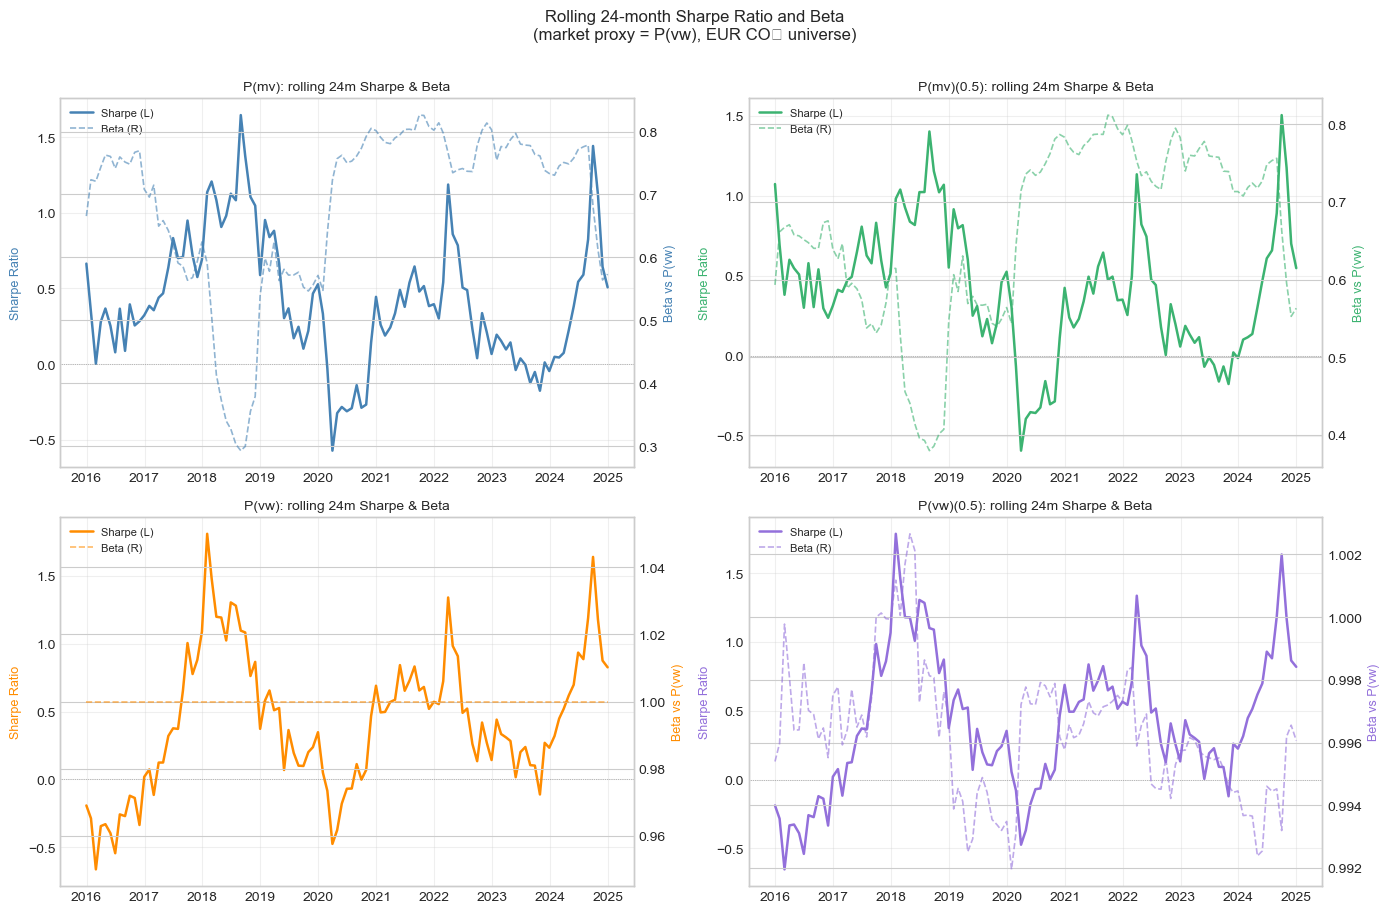

In [72]:
#  Rolling 24-month Sharpe and Beta 

def rolling_capm(ret_p, ret_m, rf, window=24):
    results = []
    r   = ret_p.dropna()
    rm  = ret_m.reindex(r.index)
    rfr = rf.reindex(r.index).fillna(0)
    for i in range(window, len(r) + 1):
        rw   = r.iloc[i - window:i]
        rmw  = rm.iloc[i - window:i]
        rfw  = rfr.iloc[i - window:i]
        re   = rw - rfw
        rem  = rmw - rfw
        valid = re.notna() & rem.notna()
        if valid.sum() < 10:
            continue
        ann_r = rw.mean() * 12
        ann_v = rw.std(ddof=0) * np.sqrt(12)
        rf_a  = rfw.mean() * 12
        slope, intercept, _, _, _ = linregress(rem[valid], re[valid])
        results.append({
            'date':   r.index[i - 1],
            'sharpe': (ann_r - rf_a) / ann_v if ann_v > 0 else np.nan,
            'beta':   slope,
            'alpha':  intercept * 12
        })
    return pd.DataFrame(results).set_index('date')

roll_mv   = rolling_capm(ret_mv,     ret_market, rf_monthly)
roll_mv50 = rolling_capm(ret_mv_50,  ret_market, rf_monthly)
roll_vw   = rolling_capm(ret_vw_oos, ret_market, rf_monthly)
roll_vw50 = rolling_capm(ret_vw_50,  ret_market, rf_monthly)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=False)

portfolios = [
    (roll_mv,   'P(mv)',       'steelblue'),
    (roll_mv50, 'P(mv)(0.5)', 'mediumseagreen'),
    (roll_vw,   'P(vw)',       'darkorange'),
    (roll_vw50, 'P(vw)(0.5)', 'mediumpurple'),
]

for ax, (roll, label, color) in zip(axes.flat, portfolios):
    ax2 = ax.twinx()
    ax.plot(roll.index, roll['sharpe'], color=color, lw=1.8, label='Sharpe (L)')
    ax2.plot(roll.index, roll['beta'],  color=color, lw=1.2, ls='--',
             alpha=0.6, label='Beta (R)')
    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.set_title(f'{label}: rolling 24m Sharpe & Beta', fontsize=10)
    ax.set_ylabel('Sharpe Ratio', fontsize=9, color=color)
    ax2.set_ylabel('Beta vs P(vw)', fontsize=9, color=color)
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    'Rolling 24-month Sharpe Ratio and Beta\n(market proxy = P(vw), EUR CO\u2082 universe)',
    fontsize=12, y=1.01
)
plt.tight_layout()
plt.show()

## 5.7 Drawdown profile — all 4 portfolios

The drawdown chart overlays peak-to-trough loss paths for all four strategies, making the downside protection effect of both the carbon constraint and the minimum-variance objective immediately visible.

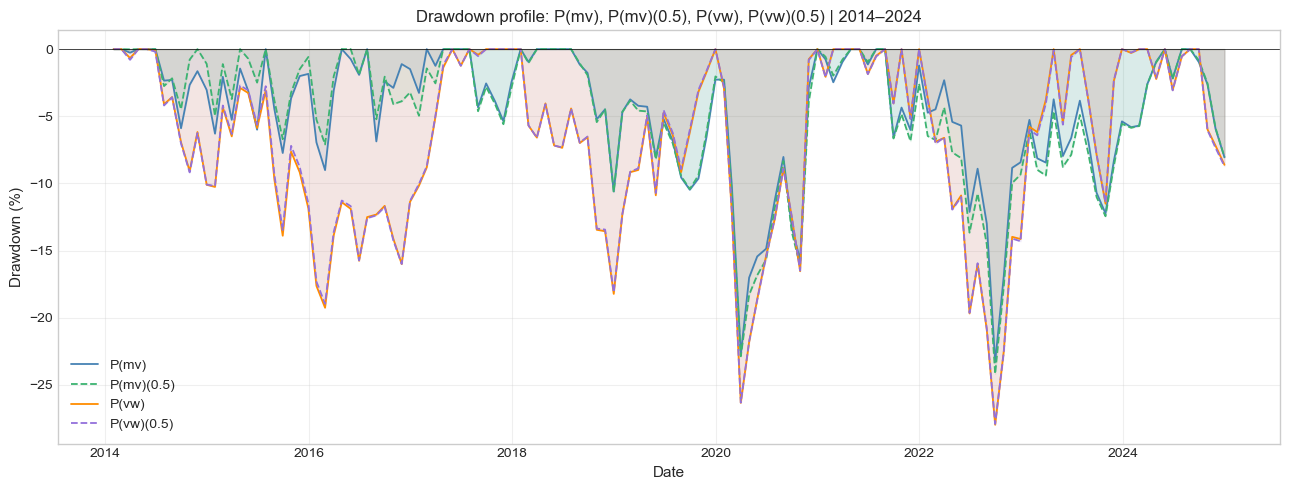

In [73]:
#  Drawdown underwater chart 

fig, ax = plt.subplots(figsize=(13, 5))

portfolios_dd = [
    ('P(mv)',       ret_mv,     'steelblue',     '-'),
    ('P(mv)(0.5)', ret_mv_50,  'mediumseagreen', '--'),
    ('P(vw)',       ret_vw_oos, 'darkorange',     '-'),
    ('P(vw)(0.5)', ret_vw_50,  'mediumpurple',   '--'),
]

for label, ret, color, ls in portfolios_dd:
    r      = ret.dropna()
    ci     = (1 + r).cumprod()
    dd     = (ci - ci.cummax()) / ci.cummax() * 100
    ax.fill_between(dd.index, dd, 0, alpha=0.10, color=color)
    ax.plot(dd.index, dd, color=color, lw=1.3, ls=ls, label=label)

ax.axhline(0, color='black', lw=0.5)
ax.set_ylabel('Drawdown (%)', fontsize=11)
ax.set_xlabel('Date', fontsize=11)
ax.set_title(
    'Drawdown profile: P(mv), P(mv)(0.5), P(vw), P(vw)(0.5) | 2014\u20132024',
    fontsize=12
)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5.8 Carbon-financial efficiency analysis

Two complementary views: (left) the financial cost of decarbonization measured as the change in Sharpe ratio per percentage point of CF reduction; (right) the Carbon Efficiency Score, defined as Sharpe Ratio per unit of mean financed emissions (× 1000 for readability).

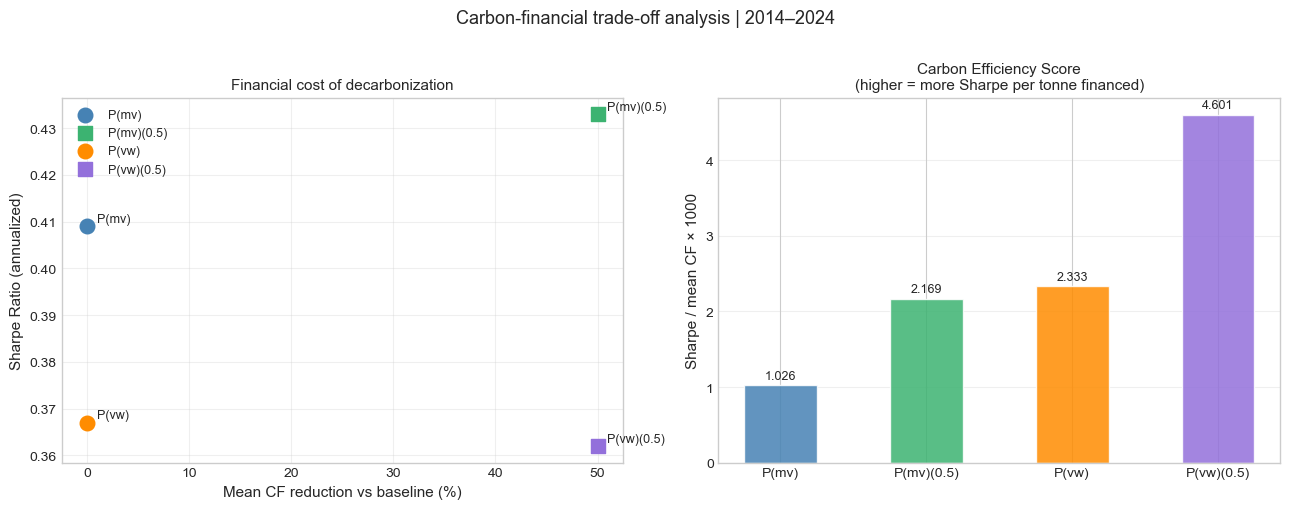

In [74]:
#  Carbon-Financial Efficiency 

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# labels_all and metrics_all defined in cell 96
colors_all  = ['steelblue', 'mediumseagreen', 'darkorange', 'mediumpurple']
markers_all = ['o', 's', 'o', 's']

#  Left: Sharpe vs CF Reduction scatter 
ax = axes[0]
for label, m, color, marker in zip(labels_all, metrics_all, colors_all, markers_all):
    cf_red = m.get('CF Reduction (%)', 0) or 0
    ax.scatter(cf_red, m['Sharpe Ratio'],
               color=color, marker=marker, s=110, zorder=3, label=label)
    ax.annotate(label, (cf_red, m['Sharpe Ratio']),
                textcoords='offset points', xytext=(7, 3), fontsize=9)

ax.set_xlabel('Mean CF reduction vs baseline (%)', fontsize=11)
ax.set_ylabel('Sharpe Ratio (annualized)', fontsize=11)
ax.set_title('Financial cost of decarbonization', fontsize=11)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)

#  Right: Carbon Efficiency Score bar chart 
ax2 = axes[1]
ces  = [m['Carbon Efficiency Score'] for m in metrics_all]
bars = ax2.bar(labels_all, ces, color=colors_all, edgecolor='white', alpha=0.85, width=0.5)

for bar, val in zip(bars, ces):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        val + max(ces) * 0.01,
        f'{val:.3f}',
        ha='center', va='bottom', fontsize=9
    )

ax2.set_ylabel('Sharpe / mean CF \u00d7 1000', fontsize=11)
ax2.set_title('Carbon Efficiency Score\n(higher = more Sharpe per tonne financed)', fontsize=11)
ax2.grid(True, alpha=0.3, axis='y')

plt.suptitle(
    'Carbon-financial trade-off analysis | 2014\u20132024',
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.show()

## 5.9 Annual turnover and estimated transaction costs

Annual turnover is defined as the sum of absolute weight changes at each rebalancing date. Transaction costs are estimated at 10 basis points per unit of turnover (institutional round-trip), subtracted from annualised return to compute the net Sharpe ratio.

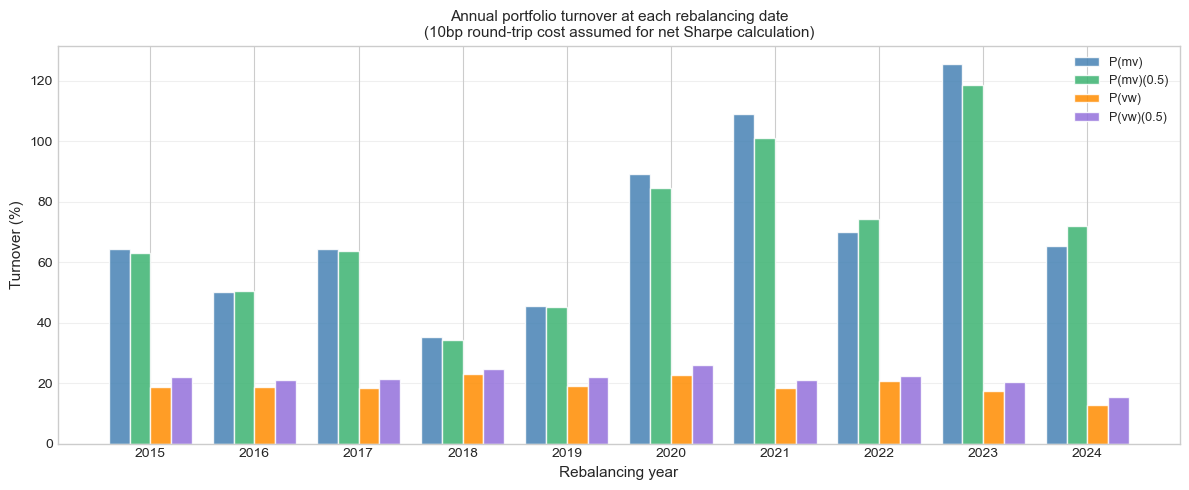

Mean annual turnover and net Sharpe summary:
-------------------------------------------------------
P(mv)          Turnover:  71.8%  Est. TC:  0.072%  Net Sharpe:  0.404
P(mv)(0.5)     Turnover:  70.7%  Est. TC:  0.071%  Net Sharpe:  0.427
P(vw)          Turnover:  18.9%  Est. TC:  0.019%  Net Sharpe:  0.366
P(vw)(0.5)     Turnover:  21.6%  Est. TC:  0.022%  Net Sharpe:  0.361


In [75]:
#  Annual Turnover by Year 

def annual_turnover_series(weights_dict):
    """Compute turnover at each rebalancing date."""
    years = sorted(weights_dict.keys())
    rows  = []
    for i, yr in enumerate(years[1:], 1):
        prev = years[i - 1]
        wp   = weights_dict[yr]
        wpp  = weights_dict[prev]
        common = wp.index.union(wpp.index)
        to = (wp.reindex(common).fillna(0) -
              wpp.reindex(common).fillna(0)).abs().sum()
        rows.append({'Year': yr, 'Turnover': to})
    return pd.DataFrame(rows).set_index('Year')

to_mv   = annual_turnover_series(weights_mv)
to_mv50 = annual_turnover_series(weights_mv_50)
to_vw   = annual_turnover_series(vw_weights_dict)
to_vw50 = annual_turnover_series(weights_vw_50)

fig, ax = plt.subplots(figsize=(12, 5))

x     = np.array(sorted(weights_mv.keys())[1:])
width = 0.2

for i, (to, label, color) in enumerate([
    (to_mv,   'P(mv)',       'steelblue'),
    (to_mv50, 'P(mv)(0.5)', 'mediumseagreen'),
    (to_vw,   'P(vw)',       'darkorange'),
    (to_vw50, 'P(vw)(0.5)', 'mediumpurple'),
]):
    vals = [to.loc[yr, 'Turnover'] * 100 if yr in to.index else 0 for yr in x]
    ax.bar(x + (i - 1.5) * width, vals, width=width,
           label=label, color=color, alpha=0.85, edgecolor='white')

ax.set_xlabel('Rebalancing year', fontsize=11)
ax.set_ylabel('Turnover (%)', fontsize=11)
ax.set_title(
    'Annual portfolio turnover at each rebalancing date\n'
    '(10bp round-trip cost assumed for net Sharpe calculation)',
    fontsize=11
)
ax.set_xticks(x)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Summary
print('Mean annual turnover and net Sharpe summary:')
print('-' * 55)
for label, m in zip(labels_all, metrics_all):
    print(f"{label:<14} "
          f"Turnover: {m['Mean Annual Turnover (%)']:>5.1f}%  "
          f"Est. TC: {m['Est. TC Annual (%)']:>6.3f}%  "
          f"Net Sharpe: {m['Net Sharpe (post TC)']:>6.3f}")